# Imports and Paths

In [1]:
import osmnx as ox
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

import os
import math
import json
from pathlib import Path
from tqdm import tqdm
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import cv2
import random
import geopandas as gpd
import glob

from sklearn.model_selection import train_test_split
import tensorflow as tf

from tqdm import tqdm
from scipy.ndimage import distance_transform_edt
from rasterio.features import rasterize

from scipy.spatial import cKDTree
from multiprocessing import Pool


In [2]:
# Define path locations
DRIVE_BASE = 'data/'

IMG_PATH_2019_WET = os.path.join(DRIVE_BASE, "realigned_images/2019_wet_aligned.tif")
IMG_PATH_2019_DRY = os.path.join(DRIVE_BASE, "realigned_images/2019_dry_aligned.tif")

IMG_PATH_2024 = os.path.join(DRIVE_BASE, "realigned_images/2024_dry_aligned.tif")

LULC_PATH_2019 = os.path.join(DRIVE_BASE, "lulc/senegal_esri_lulc_2019.tif")
LULC_PATH_2024 = os.path.join(DRIVE_BASE, "lulc/senegal_esri_lulc_2024_aligned.tif")

CNN_PATCHES_OUT_DIR = os.path.join(DRIVE_BASE, "patches")
os.makedirs(CNN_PATCHES_OUT_DIR, exist_ok=True)

In [3]:
# Define constants for splitting into patches of PATCH_SIZE by PATCH_SIZE
PATCH_SIZE = 64
MIN_URBAN_FRAC = 0.5
STRIDE = 32
SCALE = 10000.0

# Bands selection (1-based indices in geotiff)
# R G B NIR are 1,2,3, 4 respectively
BANDS = [1, 2, 3, 4]

URBAN_CLASS = 7

NUM_LULC_CLASSES = 12

# Random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [4]:
# LULC class mapping
LULC_CLASSES = {
    0: "Nothing (No data)",
    1: "Water",
    2: "Trees",
    4: "Flooded vegetation",
    5: "Crops",
    7: "Built area (Urban)",
    8: "Bare ground",
    9: "Snow / Ice",
    10: "Clouds",
    11: "Rangeland"
}

LULC_COLORS = {
    0: "#000000", # black
    1: "#1f78b4", # blue
    2: "#33a02c", # green
    4: "#6baed6", # light blue
    5: "#ff7f00", # orange
    7: "#e31a1c", # red (urban)
    8: "#b15928", # brown
    9: "#f0f0f0", # white/grey
    10: "#bdbdbd", # grey
    11: "#cab2d6", # purple
}

lulc_cmap = mcolors.ListedColormap(
    [LULC_COLORS[k] for k in sorted(LULC_COLORS.keys())]
)

lulc_norm = mcolors.BoundaryNorm(
    boundaries=list(sorted(LULC_COLORS.keys())) + [max(LULC_COLORS.keys()) + 1],
    ncolors=len(LULC_COLORS)
)

# Visualise Senegal Infrastructure

## Visualise Senegal Educational Facilities Through OSM

In [36]:
schools = gpd.read_file("data/osm/schools_senegal.gpkg")
schools = schools.to_crs(epsg=32628)
print(len(schools))
schools.explore()

3194


## Visualise Senegal Airports Through OSM



In [37]:
airports = gpd.read_file("data/osm/airports_senegal.gpkg")

print(len(airports))
airports = airports.to_crs(epsg=32628)
airports.explore()

27


# Data Pre-processing

## Sanity Check

In [11]:
# Sanity Checks
def open_info(path):
    with rasterio.open(path) as src:
        print("Path:", path)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("Width x Height:", src.width, "x", src.height)
        print("Bands:", src.count)
        print("Nodata:", src.nodata)
        print("Dtype:", src.dtypes)

open_info(IMG_PATH_2019_WET)
open_info(IMG_PATH_2019_DRY)
open_info(IMG_PATH_2024)
open_info(LULC_PATH_2019)
open_info(LULC_PATH_2024)

# Verify shapes equal (image and lulc)
with rasterio.open(IMG_PATH_2019_DRY) as im, rasterio.open(LULC_PATH_2019) as lulc:
    same_shape = (im.width == lulc.width) and (im.height == lulc.height)
    same_transform = (im.transform == lulc.transform)
    same_crs = (im.crs == lulc.crs)
    print("Same shape:", same_shape)
    print("Same transform:", same_transform)
    print("Same CRS:", same_crs)

if not same_shape or not same_transform or not same_crs:
    print("WARNING: Images and LULC are not perfectly aligned. Either reproject/resample or use the align script.")


Path: data/realigned_images/2019_wet_aligned.tif
CRS: EPSG:32628
Transform: | 9.99, 0.00, 191776.60|
| 0.00,-9.99, 1859196.30|
| 0.00, 0.00, 1.00|
Width x Height: 70964 x 51867
Bands: 6
Nodata: None
Dtype: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
Descriptions: (None, None, None, None, None, None)
... (33 lines trimmed) ...
| 0.00,-9.99, 1859196.30|
| 0.00, 0.00, 1.00|
Width x Height: 70964 x 51867
Bands: 1
Nodata: 0.0
Dtype: ('uint8',)
Descriptions: (None,)
Same shape: True
Same transform: True
Same CRS: True


## Infrastructure Proximity Raster

### Rasterising the Infrastructure Distance Data

In [38]:
# Convert the points of interest into binary rasters that line up w the images
def rasterise_pois(gdf, reference_raster, out_value=1):
    shapes = ((geom, out_value) for geom in gdf.geometry if geom is not None)

    return rasterize(
        shapes=shapes,
        out_shape=(reference_raster.height, reference_raster.width),
        transform=reference_raster.transform,
        fill=0,
        dtype="uint8"
    )

In [39]:
with rasterio.open(IMG_PATH_2019_DRY) as ref:
    school_binary = rasterise_pois(schools, ref)
    airport_binary = rasterise_pois(airports, ref)

In [40]:
print("Airport POI pixels:", int(airport_binary.sum()))
print("School POI pixels:", int(school_binary.sum()))

Airport POI pixels: 263385
School POI pixels: 212069


### Viewing Rasterised OSM Data (Schools and Airports)

#### Airports

In [49]:
from scipy.ndimage import label

def find_valid_airports(
    airport_binary,
    img_path,
    max_airports=10,
    check_band=1
):
    """
    Find up to max_airports distinct airports that overlap valid image data.

    Returns a list of (row, col) representative pixels, one per airport.
    """

    # Label connected components (each airport)
    labeled, num_airports = label(airport_binary)

    print(f"Found {num_airports} airport components")

    valids = []

    with rasterio.open(img_path) as ds:
        nodata = ds.nodata

        for airport_id in range(1, num_airports + 1):
            ys, xs = np.where(labeled == airport_id)

            if len(xs) == 0:
                continue

            # Use centre pixel as representative
            y = int(np.mean(ys))
            x = int(np.mean(xs))

            val = ds.read(
                check_band,
                window=Window(x, y, 1, 1)
            )[0, 0]

            if nodata is not None:
                valid = val != nodata
            else:
                valid = val != 0

            if valid:
                valids.append((y, x))

            if len(valids) >= max_airports:
                break

    if len(valids) == 0:
        raise ValueError("No airports overlap valid image data")

    return valids

def show_2019_dry_raw_valid_airports(
    img_path,
    airport_binary,
    window_size=512,
    bands=(1, 2, 3),
    max_airports=10
):
    valid_airports = find_valid_airports(
        airport_binary,
        img_path,
        max_airports=max_airports
    )

    for i, (y, x) in enumerate(valid_airports):
        half = window_size // 2
        row_off = max(0, y - half)
        col_off = max(0, x - half)

        win = Window(col_off, row_off, window_size, window_size)

        with rasterio.open(img_path) as ds:
            img = np.stack(
                [ds.read(b, window=win).astype(np.float32) for b in bands],
                axis=-1
            )

        # Normalise for display
        img_min = np.percentile(img, 2)
        img_max = np.percentile(img, 98)
        img = np.clip(
            (img - img_min) / (img_max - img_min + 1e-6),
            0,
            1
        )

        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title(f"2019 Dry Raw RGB – Airport {i + 1}")
        plt.axis("off")

        # Overlay airport footprint
        ap_patch = airport_binary[
            row_off:row_off + window_size,
            col_off:col_off + window_size
        ]
        plt.contour(ap_patch, levels=[0.5], colors="yellow", linewidths=1)

        plt.show()

In [ ]:
show_2019_dry_raw_valid_airports(
    img_path=IMG_PATH_2019_DRY,
    airport_binary=airport_binary,
    max_airports=10
)

#### Schools

In [ ]:
def find_valid_schools(
    school_binary,
    img_path,
    max_schools=10,
    check_band=1
):
    """
    Find up to max_schools distinct schools that overlap valid image data.

    Returns a list of (row, col) representative pixels, one per school.
    """

    # Label connected components (each school)
    labeled, num_schools = label(school_binary)

    print(f"Found {num_schools} school components")

    valids = []

    with rasterio.open(img_path) as ds:
        nodata = ds.nodata

        for school_id in range(1, num_schools + 1):
            ys, xs = np.where(labeled == school_id)

            if len(xs) == 0:
                continue

            # Use center pixel as representative
            y = int(np.mean(ys))
            x = int(np.mean(xs))

            val = ds.read(
                check_band,
                window=Window(x, y, 1, 1)
            )[0, 0]

            if nodata is not None:
                valid = val != nodata
            else:
                valid = val != 0

            if valid:
                valids.append((y, x))

            if len(valids) >= max_schools:
                break

    if len(valids) == 0:
        raise ValueError("No schools overlap valid image data")

    return valids

def show_2019_dry_raw_valid_schools(
    img_path,
    school_binary,
    window_size=512,
    bands=(1, 2, 3),
    max_schools=10
):
    valid_schools = find_valid_schools(
        school_binary,
        img_path,
        max_schools=max_schools
    )

    for i, (y, x) in enumerate(valid_schools):
        half = window_size // 2
        row_off = max(0, y - half)
        col_off = max(0, x - half)

        win = Window(col_off, row_off, window_size, window_size)

        with rasterio.open(img_path) as ds:
            img = np.stack(
                [ds.read(b, window=win).astype(np.float32) for b in bands],
                axis=-1
            )

        # Normalise for display
        img_min = np.percentile(img, 2)
        img_max = np.percentile(img, 98)
        img = np.clip(
            (img - img_min) / (img_max - img_min + 1e-6),
            0,
            1
        )

        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title(f"2019 Dry Raw RGB - School {i + 1}")
        plt.axis("off")

        # Overlay school footprint
        sc_patch = school_binary[
            row_off:row_off + window_size,
            col_off:col_off + window_size
        ]
        plt.contour(sc_patch, levels=[0.5], colors="yellow", linewidths=1)

        plt.show()

In [ ]:
show_2019_dry_raw_valid_schools(
    img_path=IMG_PATH_2019_DRY,
    school_binary=school_binary,
    max_schools=10
)

### Testing turning POIs into Distance Rasters w full memory loading
This was the first attempt at creating the distance rasters, but failed since there was not enough memory to hold all the data at once.

In [22]:
# Convert binary POI rasters into distance rasters
def compute_distance_raster_tiled(
    binary_raster,
    pixel_size,
    tile_size=2048,
    pad=512
):
    h, w = binary_raster.shape
    dist_out = np.full((h, w), np.inf, dtype=np.float32)

    for row in range(0, h, tile_size):
        for col in range(0, w, tile_size):
            r0 = max(row - pad, 0)
            r1 = min(row + tile_size + pad, h)
            c0 = max(col - pad, 0)
            c1 = min(col + tile_size + pad, w)

            tile = binary_raster[r0:r1, c0:c1]

            dist_tile = distance_transform_edt(1 - tile)
            dist_tile *= pixel_size

            tr0 = row - r0
            tc0 = col - c0
            tr1 = tr0 + min(tile_size, h - row)
            tc1 = tc0 + min(tile_size, w - col)

            dist_out[row:row + (tr1 - tr0), col:col + (tc1 - tc0)] = \
                dist_tile[tr0:tr1, tc0:tc1]

    return dist_out


In [24]:
pixel_size = ref.transform.a # m per pixel

school_dist = compute_distance_raster_tiled(school_binary, pixel_size)
airport_dist = compute_distance_raster_tiled(airport_binary, pixel_size)

In [ ]:
def normalise_distance(dist, max_dist=5000):
    dist = np.clip(dist, 0, max_dist)
    return np.log1p(dist) / np.log1p(max_dist)

In [ ]:
school_dist = normalise_distance(school_dist)
airport_dist = normalise_distance(airport_dist)

### Get the distances from 3 Nearest Schools & Airports

In [ ]:
 build_poi_kdtree(gdf, ref_ds):
    """
    Convert POIs to pixel coordinates and build a KD-tree.
    """
    if gdf is None or len(gdf) == 0:
        raise ValueError("POI gdf is empty")
    
    coords = []
    transform = ref_ds.transform
    
    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type != "Point":
            geom = geom.centroid
        
        x, y = geom.x, geom.y
        
        # Convert geographic coords to pixel coords
        col, row = ~transform * (x, y)
        
        # Make sure coordinates are within raster bounds
        if 0 <= row < ref_ds.height and 0 <= col < ref_ds.width:
            coords.append((int(row), int(col)))
    
    if len(coords) == 0:
        raise ValueError("No valid POI coordinates within raster bounds")
    
    coords = np.array(coords)
    tree = cKDTree(coords)
    
    print(f"Built KD-tree with {len(coords)} POIs")
    return tree, coords

def precompute_distance_rasters(ref_ds, kdtree, pixel_size, k=3, max_dist=5000, chunk_size=5000):
    """
    Precompute distance rasters for entire image in chunks to avoid memory issues.
    """
    height, width = ref_ds.height, ref_ds.width
    
    # Pre-allocate the output array
    dists = np.zeros((height, width, k), dtype=np.float32)
    
    print(f"Processing {height} x {width} raster in {chunk_size}x{chunk_size} chunks...")
    
    total_chunks = ((height + chunk_size - 1) // chunk_size) * ((width + chunk_size - 1) // chunk_size)
    chunk_num = 0
    
    # Process in chunks
    for r_start in range(0, height, chunk_size):
        r_end = min(r_start + chunk_size, height)
        
        for c_start in range(0, width, chunk_size):
            c_end = min(c_start + chunk_size, width)
            chunk_num += 1
            
            # Create coordinate grid for this chunk only
            chunk_h = r_end - r_start
            chunk_w = c_end - c_start
            
            rows, cols = np.meshgrid(
                np.arange(r_start, r_end),
                np.arange(c_start, c_end),
                indexing='ij'
            )
            coords = np.column_stack([rows.ravel(), cols.ravel()])
            
            # Query distances for this chunk
            chunk_dists, _ = kdtree.query(
                coords,
                k=k,
                distance_upper_bound=max_dist / pixel_size,
                workers=-1
            )
            
            # Convert to meters and normalise
            chunk_dists = np.clip(chunk_dists * pixel_size, 0, max_dist) / max_dist
            chunk_dists = chunk_dists.reshape(chunk_h, chunk_w, k).astype(np.float32)
            
            # Store in output array
            dists[r_start:r_end, c_start:c_end, :] = chunk_dists
            
            print(f"Chunk {chunk_num}/{total_chunks} complete ({r_start}:{r_end}, {c_start}:{c_end})")
    
    print(f"Distance computation complete: shape {dists.shape}")
    return dists

def precompute_all_data(
    img_path_2019_dry,
    img_path_2019_wet,
    lulc_path_2019,
    lulc_path_2024,
    schools_gdf,
    airports_gdf,
    output_dir= os.path.join(DRIVE_BASE, 'preprocessed_data')
):
    """
    Precompute all distance rasters and convert rasters to .npy format. Only ran once and then stored.
    """
    os.makedirs(output_dir, exist_ok=True)
    
    # Open reference raster
    with rasterio.open(img_path_2019_dry) as ref:
        pixel_size = ref.transform[0]
        print(f"Raster size: {ref.height} x {ref.width}")
        print(f"Pixel size: {pixel_size} meters")
        
        # Build KD-trees
        print("\nBuilding KD-Trees")
        school_tree, school_coords = build_poi_kdtree(schools_gdf, ref)
        airport_tree, airport_coords = build_poi_kdtree(airports_gdf, ref)
        
        # Precompute distance rasters
        print("\nComputing School Distances")
        school_dists = precompute_distance_rasters(ref, school_tree, pixel_size, k=3, chunk_size=2000)
        np.save(os.path.join(output_dir, 'school_distances.npy'), school_dists)
        print("School distances computed.")
        del school_dists
        
        
        print("\nComputing Airport Distances")
        airport_dists = precompute_distance_rasters(ref, airport_tree, pixel_size, k=3, chunk_size=2000)
        np.save(os.path.join(output_dir, 'airport_distances.npy'), airport_dists)
        print("airport_dists distances computed.")
        del airport_dists
    
    print(f"\n All preprocessing complete, data saved to {output_dir}/")

In [ ]:
# Precompute everything
print("STEP 1: Preprocessing...")
precompute_all_data(
    img_path_2019_dry=IMG_PATH_2019_DRY,
    img_path_2019_wet=IMG_PATH_2019_WET,
    lulc_path_2019=LULC_PATH_2019,
    lulc_path_2024=LULC_PATH_2024,
    schools_gdf=schools,
    airports_gdf=airports,
    output_dir= os.path.join(DRIVE_BASE, 'preprocessed_data')
)

### Verifying the distance rasters to make sure they make sense

In [21]:
"""
Verify that distance rasters align correctly with satellite imagery
by visualising the same geographic window from both datasets
"""

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from matplotlib.patches import Circle
import geopandas as gpd


def plot_window_comparison(
    img_path,
    school_dist_path,
    airport_dist_path,
    schools_gdf,
    airports_gdf,
    center_row,
    center_col,
    window_size=500,
    rgb_bands=[1, 2, 3],
    max_dist_meters=5000
):
    """
    Compare a window of imagery with corresponding distance maps and POI locations.
    """
    print(f"Extracting window centered at (row={center_row}, col={center_col})")
    print(f"Window size: {window_size}x{window_size} pixels")
    
    half = window_size // 2
    r_start, r_end = center_row - half, center_row + half
    c_start, c_end = center_col - half, center_col + half
    
    # Load imagery window
    print("\nLoading satellite imagery window...")
    with rasterio.open(img_path) as src:
        # Read RGB bands
        img_window = src.read(
            rgb_bands,
            window=rasterio.windows.Window(c_start, r_start, window_size, window_size)
        )
        
        # Get geographic bounds for this window
        transform = src.window_transform(
            rasterio.windows.Window(c_start, r_start, window_size, window_size)
        )
        
        # Calculate pixel coordinates for POIs
        def geo_to_window_coords(gdf, src_transform):
            """Convert geographic coords to window pixel coords"""
            coords = []
            for geom in gdf.geometry:
                if geom is None or geom.is_empty:
                    continue
                if geom.geom_type != "Point":
                    geom = geom.centroid
                
                # Convert to pixel coordinates relative to full raster
                col, row = ~src.transform * (geom.x, geom.y)
                
                # Convert to window-relative coordinates
                win_row = row - r_start
                win_col = col - c_start
                
                # Only keep POIs within window
                if 0 <= win_row < window_size and 0 <= win_col < window_size:
                    coords.append((win_row, win_col))
            
            return coords
        
        school_coords = geo_to_window_coords(schools_gdf, src.transform)
        airport_coords = geo_to_window_coords(airports_gdf, src.transform)
    
    # Normalize imagery for display (stretch to 0-1)
    img_display = np.transpose(img_window, (1, 2, 0)).astype(float)
    for i in range(3):
        p2, p98 = np.percentile(img_display[:, :, i], (2, 98))
        img_display[:, :, i] = np.clip((img_display[:, :, i] - p2) / (p98 - p2), 0, 1)
    
    print(f"   Found {len(school_coords)} schools in window")
    print(f"   Found {len(airport_coords)} airports in window")
    
    # Load distance windows
    print("\nLoading distance raster windows...")
    school_dists = np.load(school_dist_path, mmap_mode='r')
    airport_dists = np.load(airport_dist_path, mmap_mode='r')
    
    school_window = school_dists[r_start:r_end, c_start:c_end, :]
    airport_window = airport_dists[r_start:r_end, c_start:c_end, :]
    
    print(f"   School distances shape: {school_window.shape}")
    print(f"   Airport distances shape: {airport_window.shape}")
    
    # Create visualization
    print("\nCreating comparison plot...")
    fig = plt.figure(figsize=(20, 12))
    
    # Create grid
    gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)
    
    # Row 1: Satellite image with POI overlays
    ax1 = fig.add_subplot(gs[0, :])
    ax1.imshow(img_display)
    
    # Overlay school locations
    for row, col in school_coords:
        circle = Circle((col, row), radius=5, color='blue', fill=True, alpha=0.7, linewidth=2)
        ax1.add_patch(circle)
    
    # Overlay airport locations
    for row, col in airport_coords:
        circle = Circle((col, row), radius=8, color='red', fill=True, alpha=0.7, linewidth=2)
        ax1.add_patch(circle)
    
    ax1.set_title('Satellite Imagery with POI Locations\n(Blue = Schools, Red = Airports)', 
                  fontsize=14, fontweight='bold')
    ax1.axis('off')
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='blue', alpha=0.7, label=f'Schools ({len(school_coords)} in view)'),
        Patch(facecolor='red', alpha=0.7, label=f'Airports ({len(airport_coords)} in view)')
    ]
    ax1.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
    # Row 2: School distances (3 nearest)
    for k in range(3):
        ax = fig.add_subplot(gs[1, k])
        im = ax.imshow(school_window[:, :, k], cmap='viridis_r', vmin=0, vmax=1)
        
        # Overlay school locations
        for row, col in school_coords:
            circle = Circle((col, row), radius=3, color='blue', fill=False, linewidth=2)
            ax.add_patch(circle)
        
        # Convert normalised distance to meters for title
        mean_dist_norm = school_window[:, :, k].mean()
        mean_dist_meters = mean_dist_norm * max_dist_meters
        
        ax.set_title(f'Distance to School #{k+1}\n(Mean: {mean_dist_meters:.0f}m)', 
                    fontsize=11, fontweight='bold')
        ax.axis('off')
        
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Normalised Distance\n(0=close, 1=far)', fontsize=9)
    
    # Row 3: Airport distances (3 nearest)
    for k in range(3):
        ax = fig.add_subplot(gs[2, k])
        im = ax.imshow(airport_window[:, :, k], cmap='plasma_r', vmin=0, vmax=1)
        
        # Overlay airport locations
        for row, col in airport_coords:
            circle = Circle((col, row), radius=3, color='red', fill=False, linewidth=2)
            ax.add_patch(circle)
        
        # Convert normalised distance to meters for title
        mean_dist_norm = airport_window[:, :, k].mean()
        mean_dist_meters = mean_dist_norm * max_dist_meters
        
        ax.set_title(f'Distance to Airport #{k+1}\n(Mean: {mean_dist_meters:.0f}m)', 
                    fontsize=11, fontweight='bold')
        ax.axis('off')
        
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Normalised Distance\n(0=close, 1=far)', fontsize=9)
    
    plt.suptitle(f'Alignment Verification: Window at ({center_row}, {center_col})', 
                fontsize=16, fontweight='bold', y=0.98)
    
    # Save
    output_name = f'alignment_check_r{center_row}_c{center_col}.png'
    plt.savefig(output_name, dpi=150, bbox_inches='tight')
    print(f"\n Saved to '{output_name}'")
    plt.show()
    
    # Print verification info
    print("\nAlignment Verification")
    if len(school_coords) > 0:
        print(f"Found {len(school_coords)} schools in the imagery window")
    else:
        print("No schools found in this window, try a different location")
    
    if len(airport_coords) > 0:
        print(f"Found {len(airport_coords)} airports in the imagery window")
    else:
        print("No airports found in this window, try a different location")
    
    return fig


def find_interesting_windows(
    schools_gdf,
    airports_gdf,
    img_path,
    n_suggestions=5
):
    """
    Suggest interesting window locations that contain POIs.
    """
    print("Finding Windows with POIs")
    
    with rasterio.open(img_path) as src:
        transform = src.transform
        height, width = src.height, src.width
        
        # Convert all POIs to pixel coordinates
        all_coords = []
        
        for gdf, name in [(schools_gdf, 'school'), (airports_gdf, 'airport')]:
            for geom in gdf.geometry:
                if geom is None or geom.is_empty:
                    continue
                if geom.geom_type != "Point":
                    geom = geom.centroid
                
                col, row = ~transform * (geom.x, geom.y)
                
                if 0 <= row < height and 0 <= col < width:
                    all_coords.append((int(row), int(col), name))
        
        if len(all_coords) == 0:
            print("No POIs found within raster bounds")
            return []
        
        print(f"Found {len(all_coords)} POIs total within raster bounds")
        
        # Sample diverse locations to see interesting proximity rasters
        suggestions = []
        step = max(1, len(all_coords) // n_suggestions)
        
        for i in range(0, min(len(all_coords), n_suggestions * step), step):
            row, col, poi_type = all_coords[i]
            suggestions.append((row, col))
            print(f"  Suggestion {len(suggestions)}: ({row}, {col}) - near {poi_type}")
        
        return suggestions


def quick_check_dakar(
    img_path,
    school_dist_path,
    airport_dist_path,
    schools_gdf,
    airports_gdf,
    window_size=500,
    rgb_bands=[1, 2, 3]
):
    """
    Quick check focusing on Dakar area, automatically finds a good window with POIs.
    """
    print("Quick Dakar Area Check")
    
    # Find windows with POIs
    suggestions = find_interesting_windows(schools_gdf, airports_gdf, img_path, n_suggestions=3)
    
    if len(suggestions) == 0:
        print("No POIs found in raster!")
        return
    
    # Use the first suggestion (usually a good one with POIs)
    center_row, center_col = suggestions[1]
    
    print(f"\nUsing window at: ({center_row}, {center_col})")
    print("This should show you if distances align with the imagery.\n")
    
    plot_window_comparison(
        img_path,
        school_dist_path,
        airport_dist_path,
        schools_gdf,
        airports_gdf,
        center_row,
        center_col,
        window_size,
        rgb_bands
    )

=== Quick Dakar Area Check ===
=== Finding Windows with POIs ===
Found 3221 POIs total within raster bounds
  Suggestion 1: (23409, 4455) - near school
  Suggestion 2: (46831, 16999) - near school
  Suggestion 3: (11273, 18087) - near school

Using window at: (46831, 16999)
This should show you if distances align with the imagery.

Extracting window centered at (row=46831, col=16999)
Window size: 500x500 pixels

1. Loading satellite imagery window...
   Found 55 schools in window
   Found 0 airports in window

2. Loading distance raster windows...
   School distances shape: (500, 500, 3)
   Airport distances shape: (500, 500, 3)

3. Creating comparison plot...

✓ Saved to 'alignment_check_r46831_c16999.png'


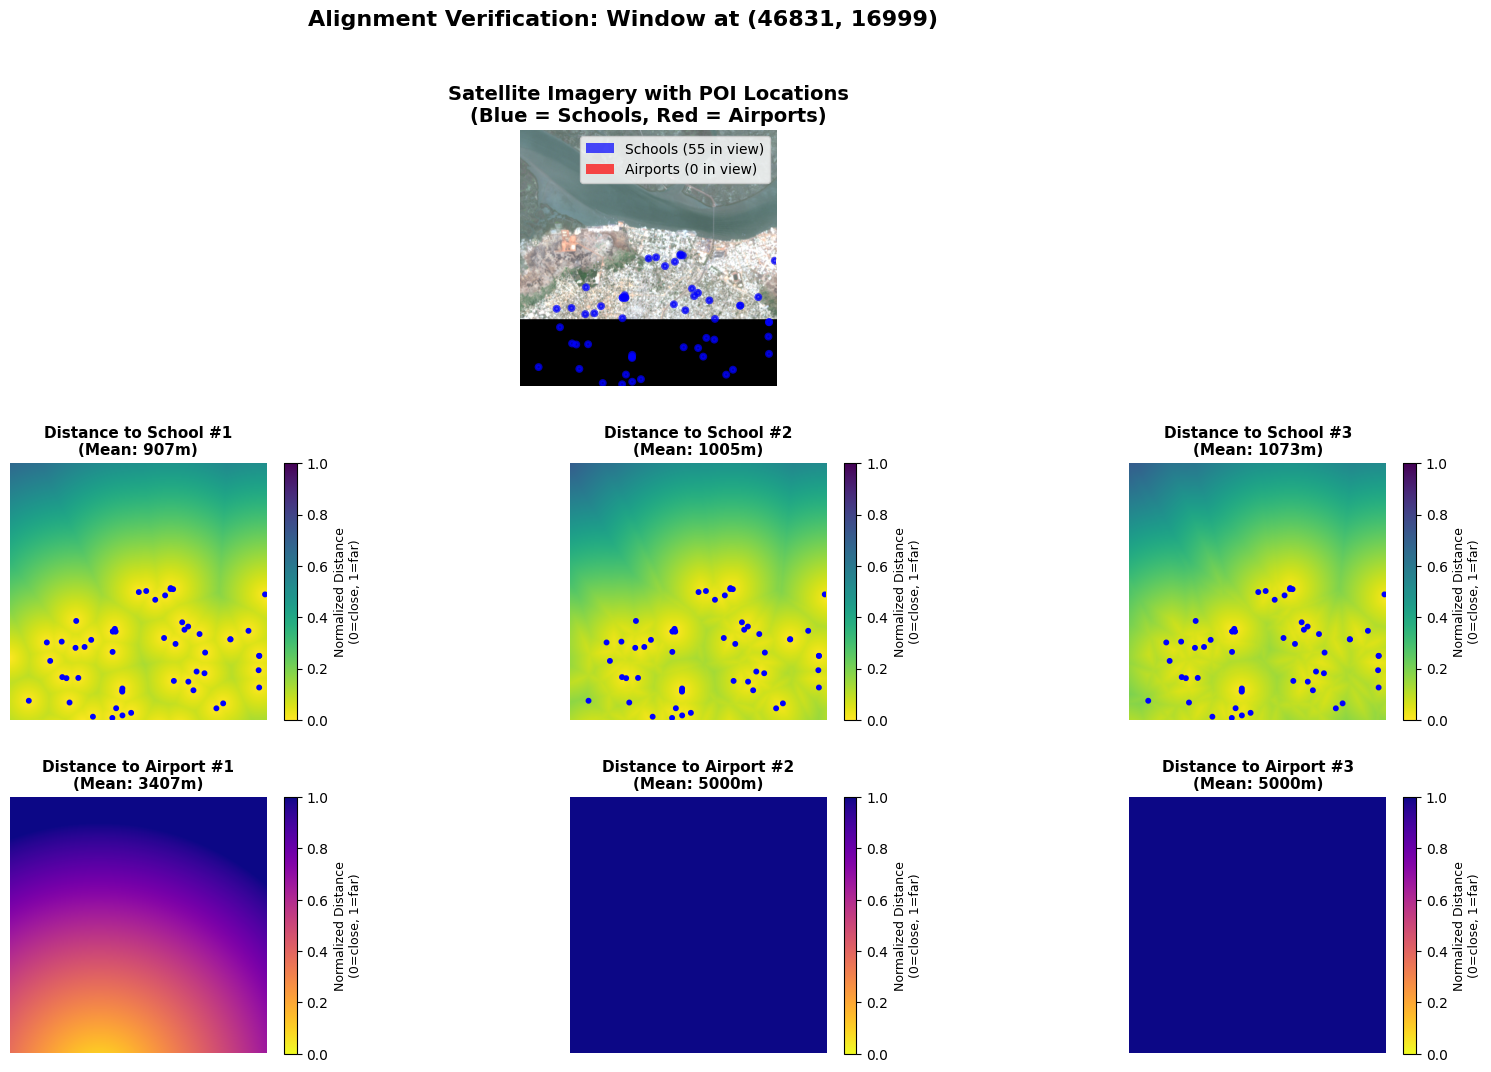


=== Alignment Verification ===
✓ Found 55 schools in the imagery window
  Check: Do the blue circles align with schools in the satellite image?
  Check: Are areas near blue circles darker (smaller distance) in school distance maps?
  No airports found in this window - try a different location


In [22]:
school_dist_path = os.path.join(DRIVE_BASE, "preprocessed_data", "school_distances.npy")
airport_dist_path = os.path.join(DRIVE_BASE, "preprocessed_data", "airport_distances.npy")

quick_check_dakar(
    img_path=IMG_PATH_2019_DRY,
    school_dist_path=school_dist_path,
    airport_dist_path=airport_dist_path,
    schools_gdf=schools,
    airports_gdf=airports,
    window_size=500,
    rgb_bands=[1, 2, 3]
)

## 32x32 Patch Extraction

In [42]:
BLOCK_ROWS = 512

OUT_DIR = "patches_npz_32"
os.makedirs(OUT_DIR, exist_ok=True)

def extract_patches_from_block(
    dry_block,
    wet_block,
    lulc_2019_block,
    lulc_2024_block,
    school_dist_block,
    airport_dist_block,
    patch_size,
    stride,
    global_row_offset,
    saved_counter
):
    """
    All arrays are aligned and clipped to the SAME window.

    dry_block: (H, W, 4)
    wet_block: (H, W, 4)
    lulc_2019_block: (H, W)
    lulc_2024_block: (H, W)
    school_dist: (H, W, 3)
    airport_dist: (H, W, 3)
    """

    H, W, _ = dry_block.shape

    for r in range(0, H - patch_size + 1, stride):
        for c in range(0, W - patch_size + 1, stride):

            lulc_2019_patch = lulc_2019_block[r:r+patch_size, c:c+patch_size]
            lulc_2024_patch = lulc_2024_block[r:r+patch_size, c:c+patch_size]

            # skip if no urban pixels
            if not np.any(lulc_2019_patch == URBAN_CLASS):
                continue

            # Extract
            dry_patch = dry_block[r:r+patch_size, c:c+patch_size, :] # (H, W, 4)
            wet_patch = wet_block[r:r+patch_size, c:c+patch_size, :] # (H, W, 4)

            school_patch = school_dist_block[
                r:r+patch_size, c:c+patch_size, :
            ]

            airport_patch = airport_dist_block[
                r:r+patch_size, c:c+patch_size, :
            ]

            # urban_mask = (lulc_patch == URBAN_CLASS).astype(np.uint8)

            
            patch = np.concatenate([
                np.transpose(dry_patch, (2, 0, 1)),
                np.transpose(wet_patch, (2, 0, 1)),
                lulc_2019_patch[None, :, :], 
                lulc_2024_patch[None, :, :], 
                np.transpose(school_patch, (2, 0, 1)),
                np.transpose(airport_patch, (2, 0, 1)),
            ], axis=0)

            # sanity check
            assert patch.shape[0] == 16

            out_path = os.path.join(
                OUT_DIR,
                f"patch_r{global_row_offset+r}_c{c}_urban.npz"
            )

            np.savez_compressed(out_path, x=patch)
            saved_counter += 1

    return saved_counter


def extract_and_save_patches_blockwise(
    img_dry_path,
    img_wet_path,
    lulc_2019_path,
    lulc_2024_path,
    school_dists_array,
    airport_dists_array,
    patch_size,
    stride,
    block_rows
):
    saved = 0

    with rasterio.open(img_dry_path) as dry_ds, \
         rasterio.open(img_wet_path) as wet_ds, \
         rasterio.open(lulc_2019_path) as lulc_ds_2019, \
         rasterio.open(lulc_2024_path) as lulc_ds_2024:

        H, W = dry_ds.height, dry_ds.width

        assert dry_ds.count >= 4
        assert wet_ds.count >= 4

        print(f"Raster size: {H} x {W}")
        print("Starting blockwise extraction...")

        for row0 in tqdm(range(0, H, block_rows), desc="Blocks"):
            row1 = min(row0 + block_rows + patch_size, H)

            win = Window(
                col_off=0,
                row_off=row0,
                width=W,
                height=row1 - row0
            )

            # Read rasters
            dry_block = np.stack(
                [dry_ds.read(b, window=win) for b in (1, 2, 3, 4)],
                axis=-1
            )

            wet_block = np.stack(
                [wet_ds.read(b, window=win) for b in (1, 2, 3, 4)],
                axis=-1
            )

            lulc_2019_block = lulc_ds_2019.read(1, window=win)
            lulc_2024_block = lulc_ds_2024.read(1, window=win)

            # Get distance blocks
            school_block = school_dists_array[row0:row1, :, :]
            airport_block = airport_dists_array[row0:row1, :, :]

            saved = extract_patches_from_block(
                dry_block,
                wet_block,
                lulc_2019_block,
                lulc_2024_block,
                school_block,
                airport_block,
                patch_size,
                stride,
                global_row_offset=row0,
                saved_counter=saved
            )

    print(f"\n Saved {saved} patches to {OUT_DIR}")


In [43]:
school_dists_array = np.load(
    "data/preprocessed_data/school_distances.npy",
    mmap_mode="r"
)

airport_dists_array = np.load(
    "data/preprocessed_data/airport_distances.npy",
    mmap_mode="r"
)

extract_and_save_patches_blockwise(
    img_dry_path=IMG_PATH_2019_DRY,
    img_wet_path=IMG_PATH_2019_WET,
    lulc_2019_path=LULC_PATH_2019,
    lulc_2024_path=LULC_PATH_2024,
    school_dists_array=school_dists_array,
    airport_dists_array=airport_dists_array,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    block_rows=BLOCK_ROWS
)

Raster size: 51867 x 70964
Starting blockwise extraction...



✓ Saved 261242 patches to patches_npz_32


In [6]:
def normalise_rgb(image):
    """
    image: (3, H, W)
    returns: (H, W, 3) in [0,1]
    """
    rgb = np.stack([image[0], image[1], image[2]], axis=-1)
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)
    return rgb

In [7]:
def compute_ndvi(red, nir):
    red = red.astype(np.float32)
    nir = nir.astype(np.float32)
    return (nir - red) / (nir + red + 1e-6)

In [53]:
# Finding the patches w the most airports / schools near
def patch_min_distance(patch, start_channel):
    """
    patch: (C, H, W)
    start_channel:
        9  -> schools (channels 9,10,11)
        12 -> airports (channels 12,13,14)
    """
    dists = patch[start_channel:start_channel+3]  # (3, H, W)
    return np.min(dists)

patch_files = glob.glob("patches_npz/*.npz")
print(f"Found {len(patch_files)} patches")

school_scores = []
airport_scores = []

for pf in tqdm(patch_files, desc="Scanning patches"):
    data = np.load(pf)
    patch = data["x"]

    school_min = patch_min_distance(patch, start_channel=9)
    airport_min = patch_min_distance(patch, start_channel=12)

    school_scores.append((school_min, pf))
    airport_scores.append((airport_min, pf))

school_scores.sort(key=lambda x: x[0]) # smaller = closer

top_school_patches = school_scores[:10]
for dist, pf in top_school_patches:
    print(f"{pf} | min school distance = {dist:.2f}")

airport_scores.sort(key=lambda x: x[0])

top_airport_patches = airport_scores[:10]
for dist, pf in top_airport_patches:
    print(f"{pf} | min airport distance = {dist:.2f}")

Found 114385 patches


patches_npz\patch_r10080_c14656_urban.npz | min school distance = 0.00
patches_npz\patch_r10080_c14688_urban.npz | min school distance = 0.00
patches_npz\patch_r10080_c14752_urban.npz | min school distance = 0.00
patches_npz\patch_r10080_c14784_urban.npz | min school distance = 0.00
patches_npz\patch_r10112_c14656_urban.npz | min school distance = 0.00
patches_npz\patch_r10112_c14688_urban.npz | min school distance = 0.00
patches_npz\patch_r10112_c14752_urban.npz | min school distance = 0.00
patches_npz\patch_r10112_c14784_urban.npz | min school distance = 0.00
patches_npz\patch_r10144_c15520_urban.npz | min school distance = 0.00
patches_npz\patch_r10144_c18912_urban.npz | min school distance = 0.00
patches_npz\patch_r13408_c48800_urban.npz | min airport distance = 0.00
patches_npz\patch_r13408_c48832_urban.npz | min airport distance = 0.00
patches_npz\patch_r13440_c48800_urban.npz | min airport distance = 0.00
patches_npz\patch_r13440_c48832_urban.npz | min airport distance = 0.00
pa

Found 114385 patches
patches_npz\patch_r10400_c47296_urban.npz
Patch shape: (16, 64, 64)


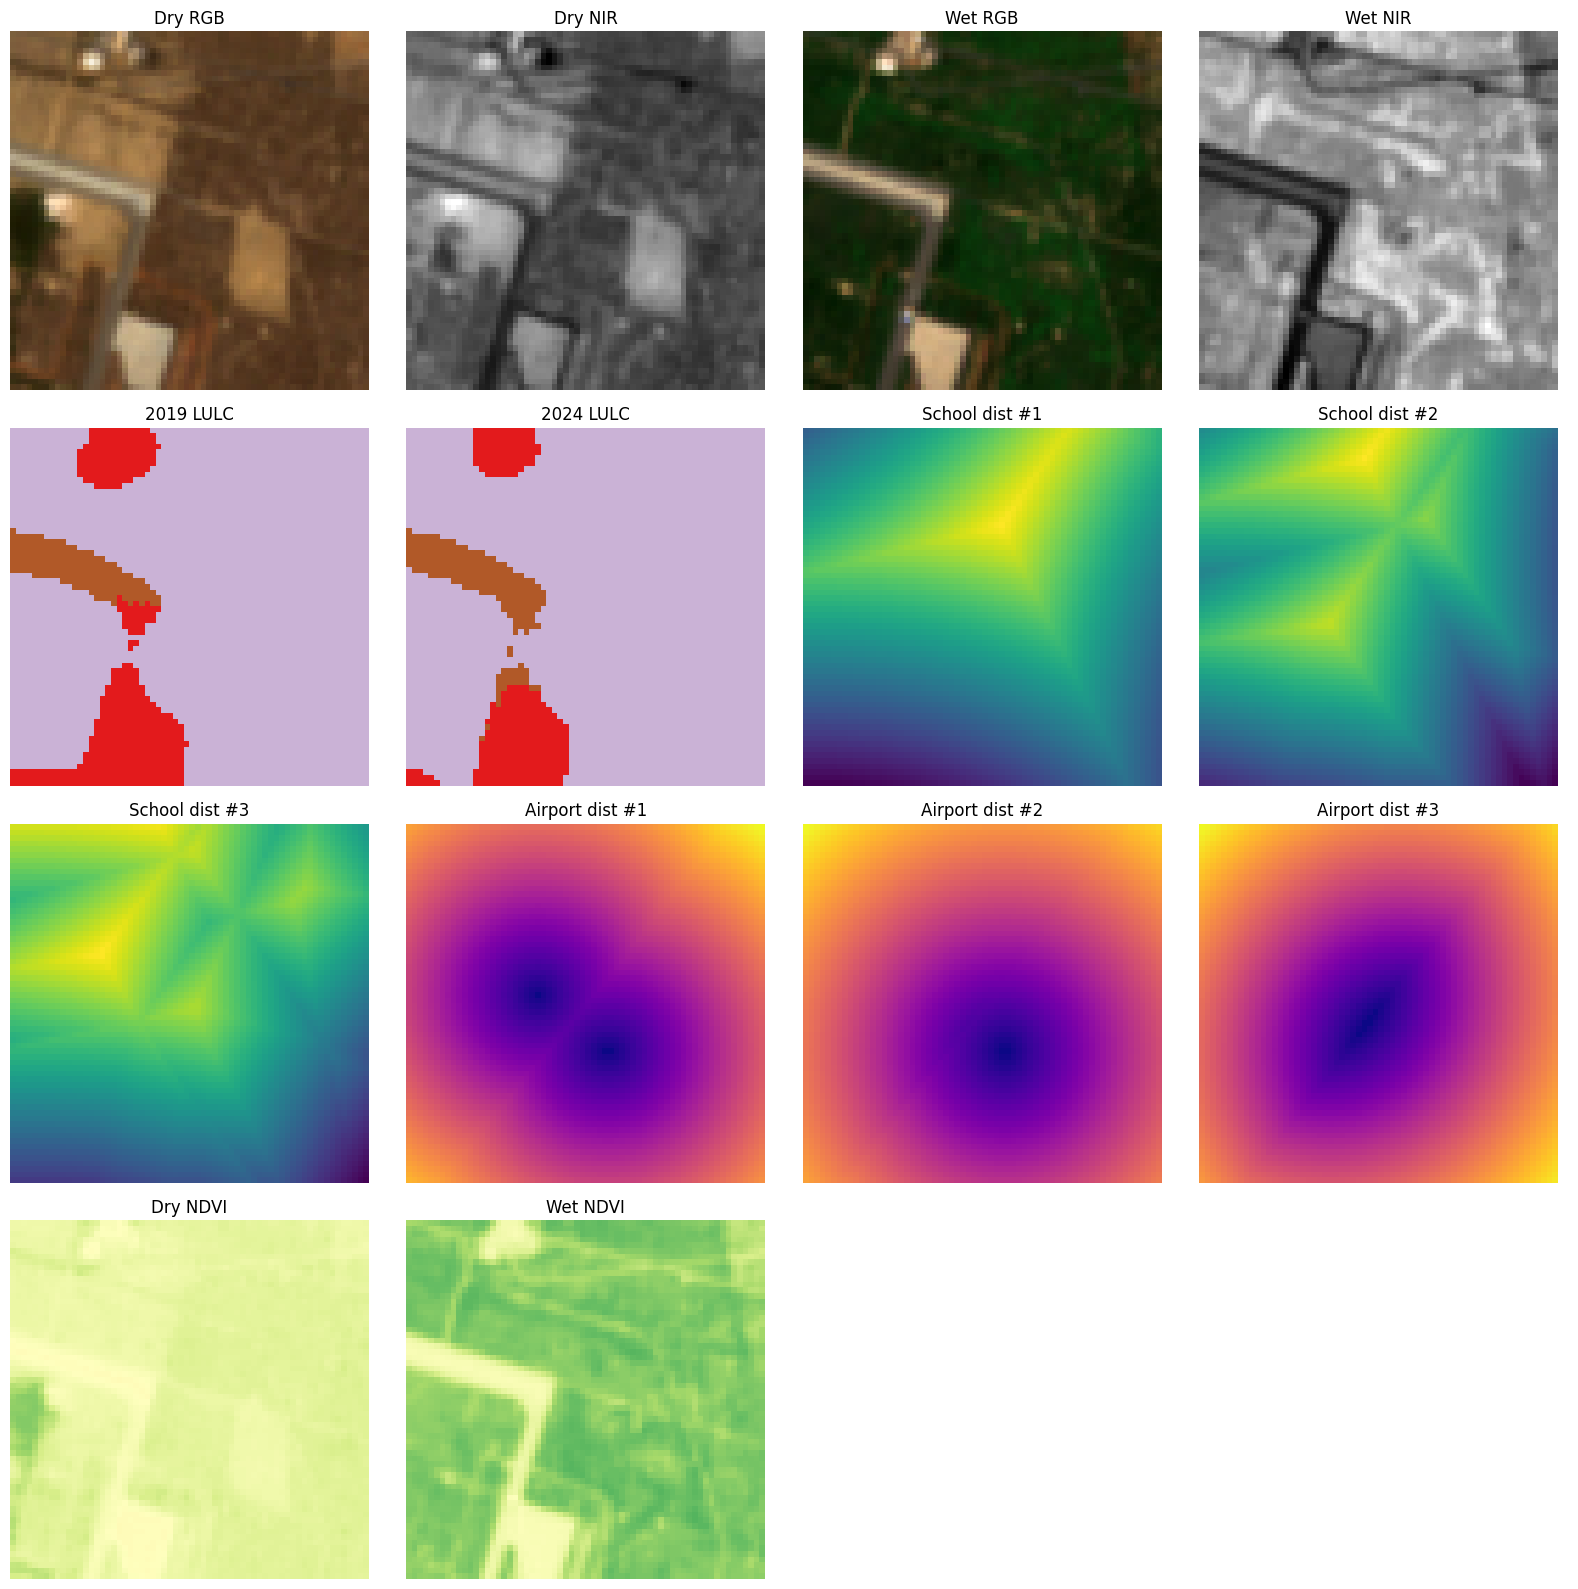

In [10]:
patch_files = glob.glob("patches_npz/*.npz")
print(f"Found {len(patch_files)} patches")

patch_path = patch_files[300]
print(patch_path)

patch_path = "patches_npz\patch_r22816_c4064_urban.npz"
data = np.load(patch_path)

patch = data["x"]
print("Patch shape:", patch.shape)

# Split the channels
dry = patch[0:4]
wet = patch[4:8]
lulc_2019 = patch[8]
lulc_2024 = patch[9]
school = patch[10:13]
airport = patch[13:16]

# Visualise
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes = axes.ravel()

# Dry RGB
dry_rgb = normalise_rgb(dry[0:3])
axes[0].imshow(dry_rgb)
axes[0].set_title("Dry RGB")

# Dry NIR 
axes[1].imshow(dry[3], cmap="gray")
axes[1].set_title("Dry NIR")

# Wet RGB 
wet_rgb = normalise_rgb(wet[0:3])
axes[2].imshow(wet_rgb)
axes[2].set_title("Wet RGB")

# Wet NIR 
axes[3].imshow(wet[3], cmap="gray")
axes[3].set_title("Wet NIR")

# Urban Mask
axes[4].imshow(lulc_2019, cmap=lulc_cmap, norm=lulc_norm)
axes[4].set_title("2019 LULC")
axes[5].imshow(lulc_2024, cmap=lulc_cmap, norm=lulc_norm)
axes[5].set_title("2024 LULC")

# School distances
for i in range(3):
    axes[6 + i].imshow(school[i], cmap="viridis")
    axes[6 + i].set_title(f"School dist #{i+1}")

# Airport distances 
for i in range(3):
    axes[9 + i].imshow(airport[i], cmap="plasma")
    axes[9 + i].set_title(f"Airport dist #{i+1}")

# NDVIs
dry_ndvi = compute_ndvi(dry[0], dry[3])
wet_ndvi = compute_ndvi(wet[0], wet[3])

axes[12].imshow(dry_ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[12].set_title("Dry NDVI")

axes[13].imshow(wet_ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[13].set_title("Wet NDVI")


# turn off unused axes
for ax in axes[11:]:
    ax.axis("off")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

count number of transitions / visualise lulcs to ensure correctness

In [27]:
import re

PATCH_DIR = "patches_npz"
PATCH_KEY = "x"
LULC_2019_CH = 8 # channel for lulc in patches
THRESHOLDS = [0.30, 0.50, 0.70]

# filename pattern
FILENAME_RE = re.compile(r"patch_r(\d+)_c(\d+)_urban\.npz")

# Counters for the different transitions
uu = 0  # urban -> urban
nu = 0  # non-urban -> urban
nn = 0  # non-urban -> non-urban
un = 0  # urban -> non-urban

stats = {
    t: {
        "UU": 0,
        "NU": 0,
        "NN": 0,
        "UN": 0,
        "TOTAL": 0
    }
    for t in THRESHOLDS
}

# Load patch names
patch_files = sorted(glob.glob(os.path.join(PATCH_DIR, "*.npz")))
print(f"Found {len(patch_files)} patches")


with rasterio.open(LULC_PATH_2024) as lulc24_ds:

    for pf in tqdm(patch_files, desc="Counting transitions"):
        fname = os.path.basename(pf)
        m = FILENAME_RE.match(fname)

        if m is None:
            raise ValueError(f"Filename does not match expected pattern: {fname}")

        row = int(m.group(1))
        col = int(m.group(2))

        # load patch 
        data = np.load(pf)
        patch = data[PATCH_KEY]

        lulc_2019 = patch[LULC_2019_CH]

        # read corresponding LULC 2024 window 
        win = Window(
            col_off=col,
            row_off=row,
            width=PATCH_SIZE,
            height=PATCH_SIZE
        )

        lulc_2024 = lulc24_ds.read(1, window=win)

        # sanity check 
        if lulc_2024.shape != lulc_2019.shape:
            raise ValueError(
                f"LULC shape mismatch at {fname}: "
                f"{lulc_2019.shape} vs {lulc_2024.shape}"
            )

        # boolean urban masks
        urban_19 = (lulc_2019 == URBAN_CLASS)
        urban_24 = (lulc_2024 == URBAN_CLASS)

        # count transitions
        uu += np.sum(urban_19 & urban_24)
        nu += np.sum(~urban_19 & urban_24)
        nn += np.sum(~urban_19 & ~urban_24)
        un += np.sum(urban_19 & ~urban_24)


        # urban fractions
        frac19 = np.mean(lulc_2019 == URBAN_CLASS)
        frac24 = np.mean(lulc_2024 == URBAN_CLASS)

        # evaluate per threshold
        for t in THRESHOLDS:
            u19 = frac19 >= t
            u24 = frac24 >= t

            if u19 and u24:
                stats[t]["UU"] += 1
            elif (not u19) and u24:
                stats[t]["NU"] += 1
            elif (not u19) and (not u24):
                stats[t]["NN"] += 1
            elif u19 and (not u24):
                stats[t]["UN"] += 1

            stats[t]["TOTAL"] += 1

# Print results
total = uu + nu + nn + un

print("\nLULC Transitions (pixel level) ")
print(f"Urban -> Urban: {uu:,}")
print(f"Non-Urban -> Urban: {nu:,}")
print(f"Non-Urban -> Non-Urban: {nn:,}")
print(f"Urban -> Non-Urban: {un:,}")
print(f"Total pixels: {total:,}")

print("\nPercentages")
print(f"Urban -> Urban: {100*uu/total:.2f}%")
print(f"Non-Urban -> Urban: {100*nu/total:.2f}%")
print(f"Non-Urban -> Non-Urban: {100*nn/total:.2f}%")
print(f"Urban -> Non-Urban: {100*un/total:.2f}%")

Found 114385 patches



=== LULC TRANSITIONS (PIXEL LEVEL) ===
Urban → Urban       : 96,759,256
Non-Urban → Urban   : 28,380,202
Non-Urban → Non-Urb : 337,107,446
Urban → Non-Urban   : 6,274,056
Total pixels        : 468,520,960

=== PERCENTAGES ===
Urban → Urban       : 20.65%
Non-Urban → Urban   : 6.06%
Non-Urban → Non-Urb : 71.95%
Urban → Non-Urban   : 1.34%


In [28]:
print("\nPatch-level transitions")

for t in THRESHOLDS:
    s = stats[t]
    print(f"\nThreshold: {int(t*100)}% urban")
    print(f"Urban -> Urban: {s['UU']}")
    print(f"Non-Urban -> Urban: {s['NU']}")
    print(f"Non-Urban -> Non-Urb: {s['NN']}")
    print(f"Urban -> Non-Urban: {s['UN']}")
    print(f"Total patches: {s['TOTAL']}")

    print("Percentages:")
    for k in ["UU", "NU", "NN", "UN"]:
        print(f"  {k}: {100*s[k]/s['TOTAL']:.2f}%")


=== PATCH-LEVEL TRANSITIONS ===

--- Threshold: 30% urban ---
Urban → Urban       : 26535
Non-Urban → Urban   : 8155
Non-Urban → Non-Urb : 78555
Urban → Non-Urban   : 1140
Total patches       : 114385
Percentages:
... (18 lines trimmed) ...
Urban → Urban       : 12019
Non-Urban → Urban   : 3863
Non-Urban → Non-Urb : 98156
Urban → Non-Urban   : 347
Total patches       : 114385
Percentages:
  UU: 10.51%
  NU: 3.38%
  NN: 85.81%
  UN: 0.30%


Showing patches:
  patch_r25984_c16864_urban.npz
  patch_r25184_c8224_urban.npz
  patch_r22528_c5504_urban.npz
  patch_r45024_c29952_urban.npz
  patch_r21696_c10144_urban.npz


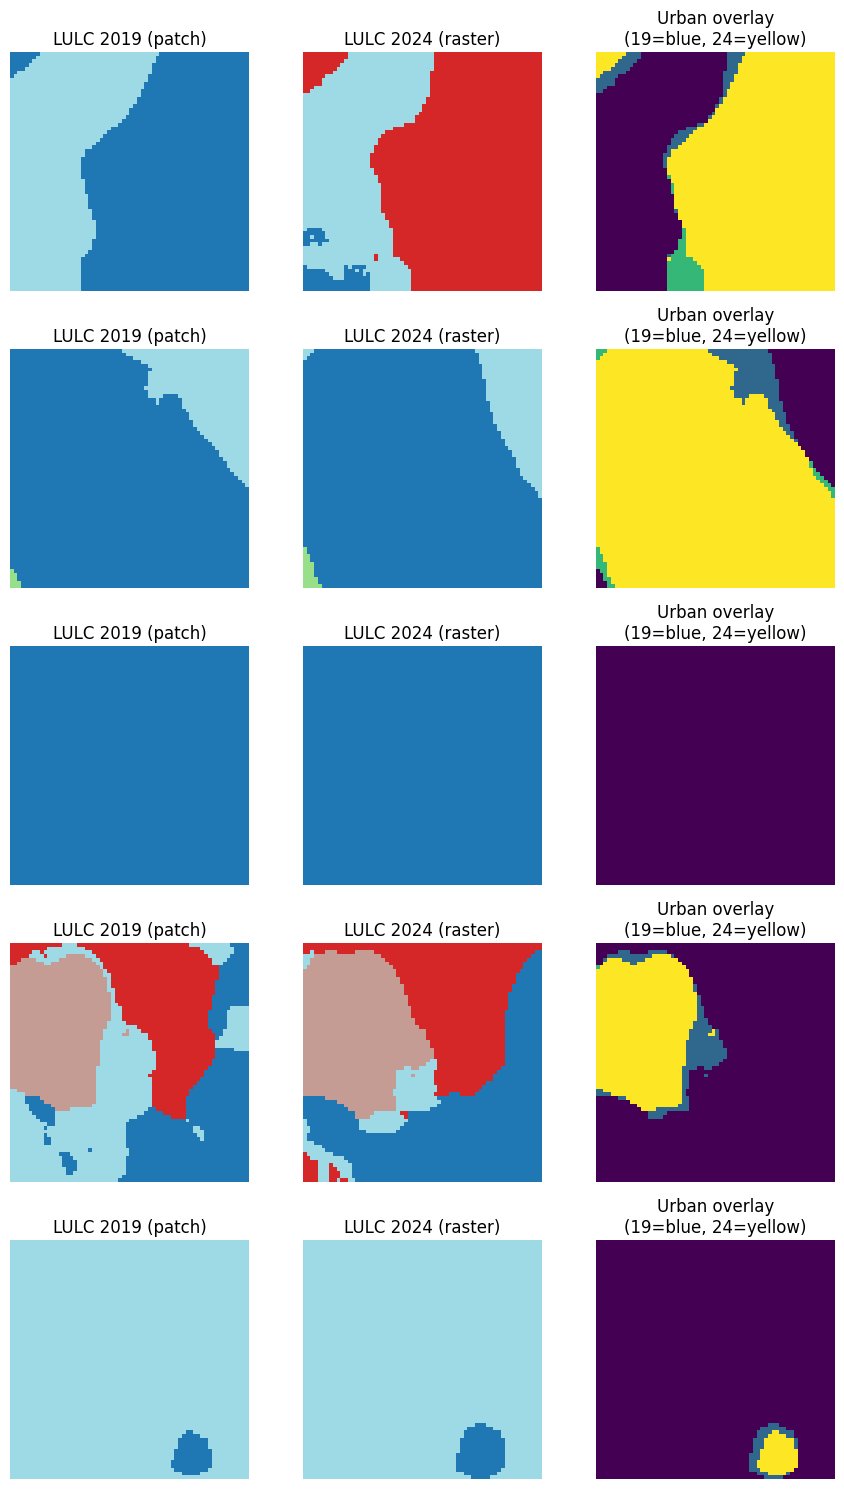

In [31]:
N_SAMPLES = 5
patch_files = glob.glob(os.path.join(PATCH_DIR, "*.npz"))
assert len(patch_files) >= N_SAMPLES

samples = random.sample(patch_files, N_SAMPLES)

print("Showing patches:")
for s in samples:
    print(" ", os.path.basename(s))

with rasterio.open(LULC_PATH_2024) as lulc24_ds:
    fig, axes = plt.subplots(
        N_SAMPLES,
        3,
        figsize=(9, 3 * N_SAMPLES)
    )

    if N_SAMPLES == 1:
        axes = axes[None, :]

    for i, pf in enumerate(samples):
        fname = os.path.basename(pf)
        m = FILENAME_RE.match(fname)

        if m is None:
            raise ValueError(f"Bad filename: {fname}")

        row = int(m.group(1))
        col = int(m.group(2))

        # load patch
        patch = np.load(pf)[PATCH_KEY]
        lulc19 = patch[LULC_2019_CH]

        # load LULC 2024
        win = Window(col, row, PATCH_SIZE, PATCH_SIZE)
        lulc24 = lulc24_ds.read(1, window=win)

        # urban masks
        urban19 = (lulc19 == URBAN_CLASS)
        urban24 = (lulc24 == URBAN_CLASS)

        # plot
        axes[i, 0].imshow(lulc19, cmap="tab20")
        axes[i, 0].set_title("LULC 2019 (patch)")

        axes[i, 1].imshow(lulc24, cmap="tab20")
        axes[i, 1].set_title("LULC 2024 (raster)")

        axes[i, 2].imshow(
            urban19.astype(int) * 2 + urban24.astype(int),
            cmap="viridis"
        )
        axes[i, 2].set_title("Urban overlay\n(19=blue, 24=yellow)")

        for j in range(3):
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
# OLDDDDD
# Patch extraction + skipping NODATA
urban_to_urban_locs = []
urban_to_nonurban_locs = []
nonurban__to_nonurban_locs = []
nonurban_to_urban_locs = []
discreps = 0

print(f"Extracting patches with size {PATCH_SIZE} and stride {STRIDE}")

with rasterio.open(IMG_PATH_2019_DRY) as src_dry, \
     rasterio.open(LULC_PATH_2019) as lulc_2019, \
     rasterio.open(LULC_PATH_2024) as lulc_2024:

    H, W = src_dry.height, src_dry.width

    for row in tqdm(range(0, H - PATCH_SIZE + 1, STRIDE), desc="Rows"):
        for col in range(0, W - PATCH_SIZE + 1, STRIDE):

            win = Window(col, row, PATCH_SIZE, PATCH_SIZE)

            img_sample = src_dry.read(1, window=win)
            x_lulc_patch = lulc_2019.read(1, window=win)
            y_lulc_patch = lulc_2024.read(1, window=win)

            if np.all(x_lulc_patch == 0) or np.all(img_sample == 0):
                continue

            if np.all(y_lulc_patch == 0):
                discreps += 1
                continue

            x_urban_frac = np.mean(x_lulc_patch == URBAN_CLASS)
            y_urban_frac = np.mean(y_lulc_patch == URBAN_CLASS)

            x_class = 1 if x_urban_frac >= MIN_URBAN_FRAC else 0
            y_class = 1 if y_urban_frac >= MIN_URBAN_FRAC else 0

            if x_class == 1 and y_class == 1:
                urban_to_urban_locs.append((row, col))
            elif x_class == 1 and y_class == 0:
                urban_to_nonurban_locs.append((row, col))
            elif x_class == 0 and y_class == 0:
                nonurban_to_nonurban_locs.append((row, col))
            else:
                nonurban_to_urban_locs.append((row, col))

print("\n urban to urban:", len(urban_to_urban_locs))
print("urban to non-urban:", len(urban_to_nonurban_locs))
print("non-urban to non-urban:", len(nonurban__to_nonurban_locs))
print("non-urban to urban:", len(nonurban_to_urban_locs))
print("discreps:", discreps)

Extracting patches with size 128 and stride 32



 urban to urban: 12100
urban to non-urban: 187
non-urban to non-urban: 1868531
non-urban to urban: 3798
discreps: 24


## Undersample Non-Urban Patches to Match Urban

Images

In [7]:
# Undersample majority to match minority
min_count = min(len(nonurban_to_urban_locs), len(nonurban__to_nonurban_locs))

nonurban_to_urban_locs_sel = nonurban_to_urban_locs # keep all minority samples
nonurban_to_nonurban_locs_sel = random.sample(nonurban__to_nonurban_locs, min_count)

print("Final balanced count:", min_count, "each class")

Final balanced count: 3798 each class


## Save Patches

In [8]:
def save_patch(src, loc, label, idx):
    row, col = loc
    win = Window(col, row, PATCH_SIZE, PATCH_SIZE)

    # read all necessary bands (just a double check that we only keep needed bands)
    arr = []
    for b in BANDS:
        arr.append(src.read(b, window=win).astype("float32"))
    arr = np.stack(arr, axis=0) # (C,H,W)

    # Compute the center coords of the patch
    x_center, y_center = src.xy(row + PATCH_SIZE // 2, col + PATCH_SIZE // 2)

    out_path = os.path.join(CNN_OUT_DIR, f"patch_{"turns_urban" if label == 1 else "stays_nonurban"}_{idx}.npz")
    np.savez_compressed(out_path, img=arr, label=label, row=row, col=col, x_center=x_center, y_center=y_center)

    return out_path

saved_paths = []

with rasterio.open(IMG_PATH_2019) as src:
    idx = 0
    for loc in tqdm(nonurban_to_urban_locs_sel, desc="Saving nonurban to urban"):
        saved_paths.append(save_patch(src, loc, 1, idx))
        idx += 1
    for loc in tqdm(nonurban_to_nonurban_locs_sel, desc="Saving non-urban"):
        saved_paths.append(save_patch(src, loc, 0, idx))
        idx += 1

print("Saved", len(saved_paths), "patches.")

Saved 7596 patches.


## Load a Saved Patch to Verify Correctness Visually

In [5]:
# pick a random saved patch
patch_files = glob.glob(CNN_OUT_DIR + "/*.npz")
patch_file = random.choice(patch_files)
random_patch_data = np.load(patch_file)

def display_patch(patch_data):
  img = patch_data["img"]
  label = patch_data["label"]

  print("Loaded:", patch_file)
  print("Label:", "Urban" if label == 1 else "Non-urban")
  print("Patch shape:", img.shape)

  # extract RGB (R=b0, G=b1, B=b2)
  rgb = np.stack([img[0], img[1], img[2]], axis=-1)

  # normalise to [0,1]
  rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)

  plt.figure(figsize=(3,3))
  plt.imshow(rgb)
  plt.axis("off")
  plt.title(f"RGB Patch – {'Turned Urban' if label==1 else 'Stayed Nonurban'}")
  plt.show()

Loaded: data/cnn_patches\patch_turns_urban_2294.npz
Label: Urban
Patch shape: (4, 128, 128)


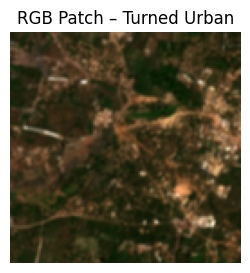

In [6]:
display_patch(random_patch_data)

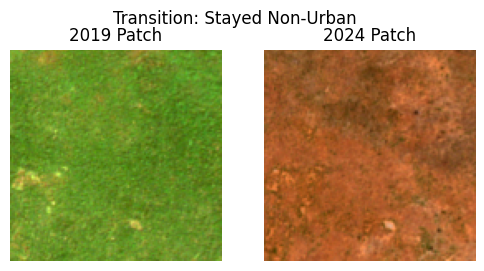

In [7]:
# pick a random saved 2019 patch
patch_files = glob.glob(CNN_OUT_DIR + "/*.npz")
patch_file = random.choice(patch_files)
patch_data = np.load(patch_file)

# Retrieve metadata
row = int(patch_data["row"])
col = int(patch_data["col"])
label = int(patch_data["label"])
img_2019 = patch_data["img"]  # (C,64,64)

PATCH_SIZE = img_2019.shape[1]

# Load the corresponding 2024 patch
with rasterio.open(IMG_PATH_2024) as src_2024:
    win = rasterio.windows.Window(col, row, PATCH_SIZE, PATCH_SIZE)

    # read same bands as in 2019
    arr_2024 = np.stack(
        [src_2024.read(b, window=win).astype("float32") for b in BANDS],
        axis=0
    )

def make_rgb(arr):
    rgb = np.stack([arr[0], arr[1], arr[2]], axis=-1)
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)
    return rgb

rgb_2019 = make_rgb(img_2019)
rgb_2024 = make_rgb(arr_2024)

plt.figure(figsize=(6,3))

plt.subplot(1,2,1)
plt.imshow(rgb_2019)
plt.title("2019 Patch")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(rgb_2024)
plt.title("2024 Patch")
plt.axis("off")

plt.suptitle(
    "Transition: " + ("Non-Urban -> Urban" if label == 1 else "Stayed Non-Urban")
)
plt.show()


In [8]:
import glob
import numpy as np
import random

# patch_files = glob.glob(CNN_OUT_DIR + "/*.npz")
# patch_files[:5]

# patch_file = random.choice(patch_files)
# print(patch_file)

data = np.load(patch_file)

print(data)
print("Stored keys:", data.files)



NpzFile 'data/cnn_patches\\patch_stays_nonurban_4710.npz' with keys: img, label, row, col, x_center...
Stored keys: ['img', 'label', 'row', 'col', 'x_center', 'y_center']


In [9]:
# Get raster for lulc using row and col
def show_lulc_at_row_col(
    lulc_path,
    row,
    col,
    patch_size=128,
    title="LULC patch (row/col)"
):
    """
    Display a LULC patch given top-left (row, col).
    """
    with rasterio.open(lulc_path) as src:
        win = Window(col, row, patch_size, patch_size)
        lulc_patch = src.read(1, window=win)

    plt.figure(figsize=(4, 4))
    # plt.imshow(lulc_patch, cmap="tab20")
    plt.imshow(lulc_patch, cmap=lulc_cmap, norm=lulc_norm)
    # plt.colorbar(label="LULC class")
    plt.title(title)
    plt.axis("off")

    plt.legend(
        handles=lulc_legend_handles(),
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        borderaxespad=0.0
    )
    
    plt.show()

# Get raster for lulc using x/y coords
def show_lulc_at_xy_center(
    lulc_path,
    x_center,
    y_center,
    patch_size=128,
    title="LULC patch (x/y center)"
):
    """
    Display a LULC patch given center coordinates (EPSG:32628).
    """
    with rasterio.open(lulc_path) as src:
        # Convert map coords to pixel indices
        row_c, col_c = src.index(x_center, y_center)

        # Compute top-left pixel of patch
        row = row_c - patch_size // 2
        col = col_c - patch_size // 2

        win = Window(col, row, patch_size, patch_size)
        lulc_patch = src.read(1, window=win)

    plt.figure(figsize=(4, 4))
    # plt.imshow(lulc_patch, cmap="tab20")
    plt.imshow(lulc_patch, cmap=lulc_cmap, norm=lulc_norm)
    # plt.colorbar(label="LULC class")
    plt.title(title)
    plt.axis("off")

    plt.legend(
        handles=lulc_legend_handles(),
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        borderaxespad=0.0
    )
    
    plt.show()

def extract_cnn_rgb_patch(img_path, row, col, patch_size=128):
    """
    Extract RGB patch (bands 1,2,3) from aligned satellite image.
    Returns (H, W, 3) normalised to [0,1].
    """
    with rasterio.open(img_path) as src:
        win = Window(col, row, patch_size, patch_size)
        rgb = np.stack([
            src.read(1, window=win),
            src.read(2, window=win),
            src.read(3, window=win)
        ], axis=-1).astype(np.float32)

    # Normalize for display
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)
    return rgb

def extract_lulc_patch(lulc_path, row, col, patch_size=128):
    with rasterio.open(lulc_path) as src:
        win = Window(col, row, patch_size, patch_size)
        return src.read(1, window=win)

def show_cnn_and_lulc_side_by_side(
    row,
    col,
    patch_size=128,
):
    # Extract patches
    rgb_2019 = extract_cnn_rgb_patch(IMG_PATH_2019, row, col, patch_size)
    rgb_2024 = extract_cnn_rgb_patch(IMG_PATH_2024, row, col, patch_size)

    lulc_2019 = extract_lulc_patch(LULC_PATH_2019, row, col, patch_size)
    lulc_2024 = extract_lulc_patch(LULC_PATH_2024, row, col, patch_size)

    # Plot
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    # 2019
    axes[0, 0].imshow(rgb_2019)
    axes[0, 0].set_title("2019 RGB")
    axes[0, 0].axis("off")

    im1 = axes[0, 1].imshow(lulc_2019, cmap=lulc_cmap, norm=lulc_norm)
    axes[0, 1].set_title("2019 LULC")
    axes[0, 1].axis("off")

    # 2024
    axes[1, 0].imshow(rgb_2024)
    axes[1, 0].set_title("2024 RGB")
    axes[1, 0].axis("off")

    im2 = axes[1, 1].imshow(lulc_2024, cmap=lulc_cmap, norm=lulc_norm)
    axes[1, 1].set_title("2024 LULC")
    axes[1, 1].axis("off")

    # Single shared legend
    fig.legend(
        handles=lulc_legend_handles(),
        loc="center right",
        bbox_to_anchor=(1.15, 0.5)
    )

    plt.tight_layout()
    plt.show()


def lulc_legend_handles():
    handles = []
    for k in sorted(LULC_CLASSES.keys()):
        handles.append(
            mpatches.Patch(
                color=LULC_COLORS[k],
                label=f"{k}: {LULC_CLASSES[k]}"
            )
        )
    return handles

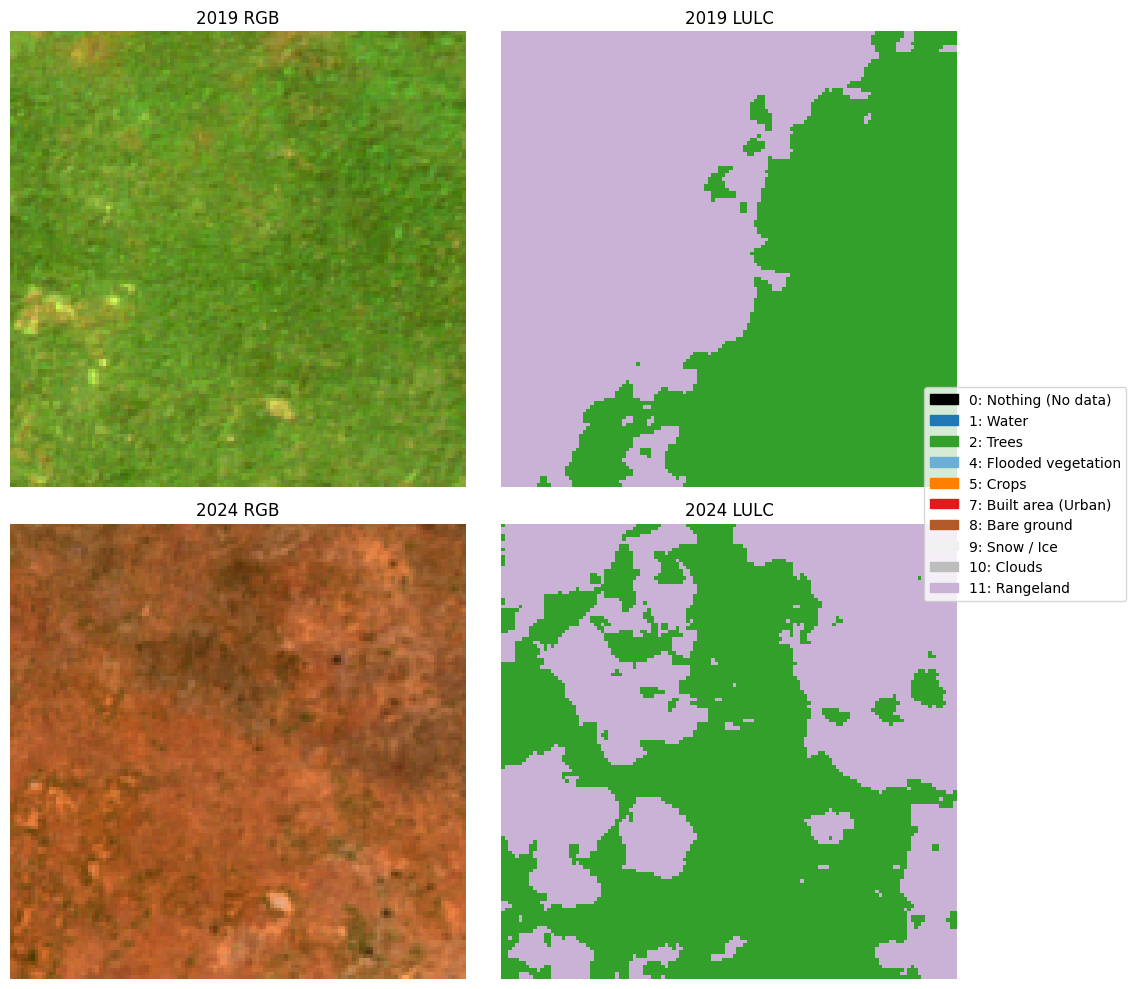

In [10]:
row = int(data["row"])
col = int(data["col"])

show_cnn_and_lulc_side_by_side(row, col)

# Data Preparation for Training (Keras Models) 
Load and split data to get train (70) / validation (15) / test (15)

Images

In [11]:
def load_patches(patch_dir):
    X, y = [], []

    for f in glob.glob(patch_dir + "/*.npz"):
        data = np.load(f)
        img = data["img"] # (C, H, W)
        label = int(data["label"])

        # Convert to (H, W, C)
        img = np.transpose(img, (1, 2, 0))

        X.append(img)
        y.append(label)

    return np.array(X), np.array(y)

In [12]:
X, y = load_patches(CNN_OUT_DIR)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7596, 128, 128, 4)
y shape: (7596,)


In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

In [14]:
X_train = X_train / np.max(X_train)
X_val = X_val / np.max(X_train)
X_test = X_test / np.max(X_train)

# LULC CNN + Comparison to IMG CNN (Keras Implementation)

In [18]:
from tensorflow.keras import layers, models

def build_lulc_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")  # binary
    ])

    return model

In [19]:
model = build_lulc_cnn(input_shape=X_train.shape[1:])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall(),
        tf.keras.metrics.AUC()
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,209 (430.50 KB)

 Trainable params: 109,761 (428.75 KB)

 Non-trainable params: 448 (1.75 KB)

In [20]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=16
)

Epoch 1/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 133s 360ms/step - accuracy: 0.9168 - auc: 0.9647 - loss: 0.2351 - precision: 0.9296 - recall: 0.9019 - val_accuracy: 0.5000 - val_auc: 0.4984 - val_loss: 16.3104 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 128s 357ms/step - accuracy: 0.9434 - auc: 0.9757 - loss: 0.1860 - precision: 0.9512 - recall: 0.9349 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 42.0493 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 127s 354ms/step - accuracy: 0.9482 - auc: 0.9793 - loss: 0.1687 - precision: 0.9539 - recall: 0.9419 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 62.4096 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/20
357/357 ━━━━━━━━━━━━━━━━━━━━ 128s 357ms/step - accuracy: 0.9559 - auc: 0.9825 - loss: 0.1498 - precision: 0.9578 - recall: 0.9538 - val_accuracy: 0.6054 - val_auc: 0.6037 - val_loss: 5.9429 - val_precision: 0.5751 - val_reca

In [23]:
import keras

model.save("cnn_lulc_only.keras")

In [58]:
lulc_model = keras.models.load_model("cnn_lulc_only.keras")
img_model = keras.models.load_model("cnn_urban_transition_model.keras")

In [59]:
import glob
import numpy as np
import os

def index_patches_by_row_col(patch_dir):
    index = {}
    for f in glob.glob(patch_dir + "/*.npz"):
        d = np.load(f)
        key = (int(d["row"]), int(d["col"]))
        index[key] = f
    return index

img_patch_index = index_patches_by_row_col(CNN_OUT_DIR)
lulc_patch_index = index_patches_by_row_col(LULC_OUT_DIR)

print(f"img patches: {len(img_patch_index)}, lulc patches: {len(lulc_patch_index)}")

img patches: 7596, lulc patches: 8158


In [60]:
img_keys  = set(img_patch_index.keys())
lulc_keys = set(lulc_patch_index.keys())

common_keys = img_keys & lulc_keys

print("Comparable patches:", len(common_keys))

common_keys = list(common_keys)

labels = [
    int(np.load(lulc_patch_index[k])["label"])
    for k in common_keys
]

test_keys = common_keys

Comparable patches: 3808


In [61]:
def load_lulc_by_keys(keys):
    X, y = [], []
    for k in keys:
        d = np.load(lulc_patch_index[k])
        X.append(np.expand_dims(d["lulc"], axis=-1))
        y.append(int(d["label"]))
    return np.array(X), np.array(y)

X_lulc_test, y_test = load_lulc_by_keys(common_keys)

def load_img_by_keys(keys):
    X = []
    missing = 0
    total = 0
    for k in keys:
        total += 1
        if k not in img_patch_index:
            missing += 1
            continue
            # raise RuntimeError(f"Missing image patch for {k}")

        d = np.load(img_patch_index[k])
        img = np.transpose(d["img"], (1, 2, 0)) # (H,W,C)
        X.append(img)

    return np.array(X), missing, total

X_img_test, missing, total = load_img_by_keys(common_keys)
print(f"Missing {missing} out of total {total}")

Missing 0 out of total 3808


In [62]:
y_prob_lulc = lulc_model.predict(X_lulc_test).ravel()
y_prob_img  = img_model.predict(X_img_test).ravel()

y_pred_lulc = (y_prob_lulc >= 0.5).astype(int)
y_pred_img  = (y_prob_img  >= 0.5).astype(int)

119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 142ms/step
119/119 ━━━━━━━━━━━━━━━━━━━━ 18s 147ms/step


LULC-only CNN
              precision    recall  f1-score   support

           0      0.004     0.800     0.007        10
           1      0.999     0.441     0.612      3798

    accuracy                          0.442      3808
   macro avg      0.501     0.620     0.310      3808
weighted avg      0.996     0.442     0.610      3808


Image-based CNN
              precision    recall  f1-score   support

           0      0.007     0.500     0.015        10
           1      0.998     0.824     0.903      3798

    accuracy                          0.823      3808
   macro avg      0.503     0.662     0.459      3808
weighted avg      0.996     0.823     0.900      3808

LULC-only AUC: 0.802
Image CNN AUC: 0.757


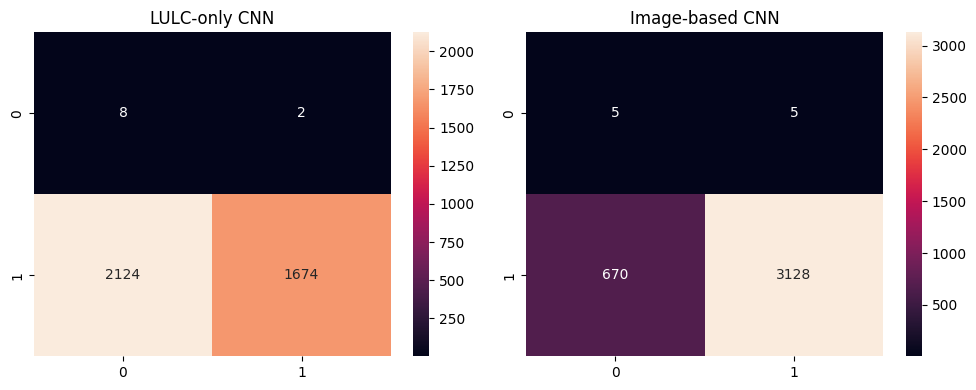

In [63]:
from sklearn.metrics import classification_report, roc_auc_score

print("LULC-only CNN")
print(classification_report(y_test, y_pred_lulc, digits=3))

print("\nImage-based CNN")
print(classification_report(y_test, y_pred_img, digits=3))

auc_lulc = roc_auc_score(y_test, y_prob_lulc)
auc_img  = roc_auc_score(y_test, y_prob_img)

print(f"LULC-only AUC: {auc_lulc:.3f}")
print(f"Image CNN AUC: {auc_img:.3f}")

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(y_test, y_pred_lulc),
            annot=True, fmt="d", ax=axes[0])
axes[0].set_title("LULC-only CNN")

sns.heatmap(confusion_matrix(y_test, y_pred_img),
            annot=True, fmt="d", ax=axes[1])
axes[1].set_title("Image-based CNN")

plt.tight_layout()
plt.show()

# Training Model (Baseline CNN)

In [15]:
from tensorflow.keras import layers, models

def build_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid") # binary
    ])

    return model

In [16]:
model = build_cnn(input_shape=X_train.shape[1:])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │           1,184 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 64, 64, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32, 32, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 111,073 (433.88 KB)

 Trainable params: 110,625 (432.13 KB)

 Non-trainable params: 448 (1.75 KB)

Add class weights even after undersampling to correctly show that the minor class is still a minority

In [17]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights))
print(class_weights)

{0: np.float64(1.0001881113619262), 1: np.float64(0.9998119593832268)}


In [19]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall(),
        tf.keras.metrics.AUC()
    ]
)

In [20]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    # callbacks=[
    #     tf.keras.callbacks.EarlyStopping(
    #         monitor="val_loss",
    #         patience=5,
    #         restore_best_weights=True
    #     )
    # ]
)

Epoch 1/100
167/167 ━━━━━━━━━━━━━━━━━━━━ 129s 749ms/step - accuracy: 0.8336 - auc_1: 0.9098 - loss: 0.3864 - precision_1: 0.8175 - recall_1: 0.8590 - val_accuracy: 0.5127 - val_auc_1: 0.5123 - val_loss: 331.0700 - val_precision_1: 0.8182 - val_recall_1: 0.0316
Epoch 2/100
167/167 ━━━━━━━━━━━━━━━━━━━━ 124s 744ms/step - accuracy: 0.9319 - auc_1: 0.9786 - loss: 0.1844 - precision_1: 0.9310 - recall_1: 0.9331 - val_accuracy: 0.5294 - val_auc_1: 0.5298 - val_loss: 1908.3198 - val_precision_1: 0.5149 - val_recall_1: 1.0000
Epoch 3/100
167/167 ━━━━━━━━━━━━━━━━━━━━ 126s 752ms/step - accuracy: 0.9584 - auc_1: 0.9887 - loss: 0.1282 - precision_1: 0.9528 - recall_1: 0.9646 - val_accuracy: 0.5031 - val_auc_1: 0.5035 - val_loss: 8381.0479 - val_precision_1: 0.5013 - val_recall_1: 1.0000
Epoch 4/100
167/167 ━━━━━━━━━━━━━━━━━━━━ 152s 814ms/step - accuracy: 0.9628 - auc_1: 0.9921 - loss: 0.1045 - precision_1: 0.9590 - recall_1: 0.9669 - val_accuracy: 0.4996 - val_auc_1: 0.5000 - val_loss: 50449.3242 -

In [ ]:
model.save("cnn_urban_transition_model_100_ep.keras")

In [21]:
from tensorflow.keras.models import load_model

mdl = load_model("cnn_urban_transition_model.keras")

In [130]:
results = mdl.evaluate(X_test, y_test, verbose=0)

for name, value in zip(mdl.metrics_names, results):
    print(f"{name}: {value:.4f}")

loss: 68.3203
compile_metrics: 0.6132


In [125]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(X_test) > 0.5).astype(int)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=[
    "Non-urban -> Non-urban",
    "Non-urban -> Urban"
]))

36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 150ms/step
[[ 11 559]
 [  1 569]]
                        precision    recall  f1-score   support

Non-urban -> Non-urban       0.92      0.02      0.04       570
    Non-urban -> Urban       0.50      1.00      0.67       570

              accuracy                           0.51      1140
             macro avg       0.71      0.51      0.35      1140
          weighted avg       0.71      0.51      0.35      1140



 # MAE

In [6]:
def load_unlabelled_patches(patch_dir):
    X = []
    for f in glob.glob(patch_dir + "/*.npz"):
        d = np.load(f)
        img = np.transpose(d["img"], (1, 2, 0))
        X.append(img)
    X = np.array(X).astype("float32")
    X /= X.max() # normalise
    return X

X_unlabelled = load_unlabelled_patches(CNN_OUT_DIR)
print("Unlabelled patches:", X_unlabelled.shape)

Unlabelled patches: (7596, 128, 128, 4)


In [9]:
# Masking function to randomly mask the given percentage of pixels
# def random_mask(images, mask_ratio=0.75):
#     batch, H, W, C = images.shape
#     mask = np.random.rand(batch, H, W, 1) > mask_ratio
#     return images * mask, mask

def apply_random_mask(batch, mask_ratio=0.75):
    """
    batch: (B, H, W, C)
    """
    B, H, W, C = batch.shape
    mask = tf.random.uniform((B, H, W, 1)) > mask_ratio
    masked = batch * tf.cast(mask, batch.dtype)
    return masked

In [8]:
from tensorflow.keras import layers, models

def build_mae(input_shape):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    x = layers.Conv2D(64, 4, strides=2, padding="same", activation="relu")(inputs)
    x = layers.Conv2D(128, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(256, 4, strides=2, padding="same", activation="relu")(x)

    # Decoder
    x = layers.Conv2DTranspose(128, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(64, 4, strides=2, padding="same", activation="relu")(x)
    outputs = layers.Conv2DTranspose(
        input_shape[-1], 4, strides=2, padding="same"
    )(x)

    return models.Model(inputs, outputs)

In [10]:
BATCH_SIZE = 8 # keep small
AUTOTUNE = tf.data.AUTOTUNE

dataset = (
    tf.data.Dataset.from_tensor_slices(X_unlabelled)
    .shuffle(1024)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [18]:
mae = build_mae((128, 128, 4))
mae.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="mse"
)

EPOCHS = 30

for epoch in tqdm(range(EPOCHS), desc="Epoch progress"):
    epoch_loss = []

    for batch in tqdm(dataset, desc=f"inner for {epoch}", position=0):
        masked = apply_random_mask(batch)
        loss = mae.train_on_batch(masked, batch)
        epoch_loss.append(loss)

    print(f"Epoch {epoch+1}/{EPOCHS} - loss: {np.mean(epoch_loss):.4f}")

Epoch 1/30 - loss: 0.0017


Epoch 2/30 - loss: 0.0005


Epoch 3/30 - loss: 0.0004


Epoch 4/30 - loss: 0.0003


Epoch 5/30 - loss: 0.0003


Epoch 6/30 - loss: 0.0003


... (20 outputs left out)

Epoch 27/30 - loss: 0.0001


Epoch 28/30 - loss: 0.0001


Epoch 29/30 - loss: 0.0001


Epoch 30/30 - loss: 0.0001


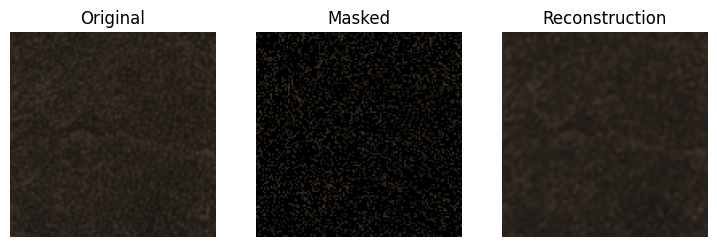

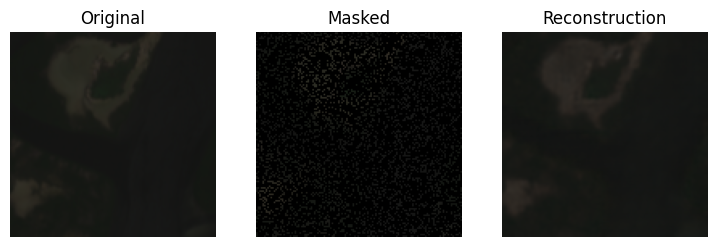

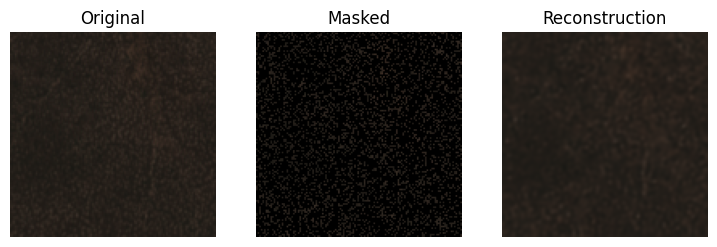

In [19]:
import matplotlib.pyplot as plt

def show_mae_reconstruction(model, dataset, n=3):
    batch = next(iter(dataset))
    masked = apply_random_mask(batch)
    recon = model(masked)

    for i in range(n):
        fig, axs = plt.subplots(1, 3, figsize=(9, 3))

        # Original
        axs[0].imshow(batch[i, :, :, :3])
        axs[0].set_title("Original")
        axs[0].axis("off")

        # Masked
        axs[1].imshow(masked[i, :, :, :3])
        axs[1].set_title("Masked")
        axs[1].axis("off")

        # Reconstruction
        axs[2].imshow(recon[i, :, :, :3])
        axs[2].set_title("Reconstruction")
        axs[2].axis("off")

        plt.show()

show_mae_reconstruction(mae, dataset)

In [20]:
def build_encoder(input_shape):
    inputs = tf.keras.Input(shape=input_shape)

    x = layers.Conv2D(64, 4, strides=2, padding="same", activation="relu")(inputs)
    x = layers.Conv2D(128, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(256, 4, strides=2, padding="same", activation="relu")(x)

    return tf.keras.Model(inputs, x, name="mae_encoder")

In [21]:
encoder = build_encoder((128, 128, 4))

# Copy weights layer by layer
for enc_layer, mae_layer in zip(encoder.layers, mae.layers):
    if enc_layer.weights:
        enc_layer.set_weights(mae_layer.get_weights())

encoder.trainable = False

In [22]:
def build_transition_classifier(encoder):
    inputs = tf.keras.Input(shape=(128, 128, 4))

    x = encoder(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs)
    return model

In [23]:
transition_model = build_transition_classifier(encoder)

transition_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall()
    ]
)

In [25]:
import glob
import numpy as np
from sklearn.model_selection import train_test_split

PATCH_DIR = CNN_OUT_DIR  # e.g. data/cnn_patches

all_patch_files = glob.glob(f"{PATCH_DIR}/*.npz")

labels = []
for f in all_patch_files:
    d = np.load(f)
    labels.append(int(d["label"]))

labels = np.array(labels)

train_files, val_files = train_test_split(
    all_patch_files,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Train patches:", len(train_files))
print("Val patches:", len(val_files))

Train patches: 6076
Val patches: 1520


In [26]:
import tensorflow as tf

def load_patch_npz(path):
    data = np.load(path.numpy().decode())
    img = data["img"] # (C,H,W)
    img = np.transpose(img, (1, 2, 0)) # -> (H,W,C)
    label = int(data["label"])
    return img.astype("float32"), label

In [27]:
def tf_load_patch(path):
    img, label = tf.py_function(
        load_patch_npz,
        [path],
        [tf.float32, tf.int32]
    )
    img.set_shape((128, 128, 4))
    label.set_shape(())
    return img, label

In [28]:
BATCH_SIZE = 16

train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_files)
    .shuffle(1000)
    .map(tf_load_patch, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices(val_files)
    .map(tf_load_patch, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [29]:
class_weight = {
    0: 1.0,
    1: 1.0
}

transition_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    class_weight=class_weight
)

Epoch 1/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 52s 132ms/step - accuracy: 0.5932 - auc: 0.6011 - loss: 89.3271 - precision: 0.5831 - recall: 0.6537 - val_accuracy: 0.6618 - val_auc: 0.7302 - val_loss: 0.8797 - val_precision: 0.6013 - val_recall: 0.9605
Epoch 2/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 49s 130ms/step - accuracy: 0.6251 - auc: 0.6853 - loss: 0.8037 - precision: 0.6073 - recall: 0.7077 - val_accuracy: 0.6651 - val_auc: 0.7082 - val_loss: 0.6405 - val_precision: 0.6116 - val_recall: 0.9053
Epoch 3/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 50s 130ms/step - accuracy: 0.6206 - auc: 0.6848 - loss: 0.6757 - precision: 0.6127 - recall: 0.6560 - val_accuracy: 0.6592 - val_auc: 0.7405 - val_loss: 0.6479 - val_precision: 0.6112 - val_recall: 0.8750
Epoch 4/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 50s 131ms/step - accuracy: 0.6145 - auc: 0.6233 - loss: 0.6700 - precision: 0.5745 - recall: 0.8831 - val_accuracy: 0.6362 - val_auc: 0.7187 - val_loss: 0.6387 - val_precision: 0.5818 - val_recall: 0.9684
Epoch 5/20
380/380 

In [34]:
transition_model.save("trans_model.keras")

In [30]:
for imgs, labels in train_dataset.take(1):
    print(imgs.shape, labels.shape)

(16, 128, 128, 4) (16,)


In [32]:
test_files = val_files

test_dataset = (
    tf.data.Dataset.from_tensor_slices(test_files)
    .map(tf_load_patch, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(16)
    .prefetch(tf.data.AUTOTUNE)
)

In [35]:
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

y_true = []
y_prob = []

for imgs, labels in test_dataset:
    probs = transition_model.predict(imgs, verbose=0)
    y_true.extend(labels.numpy())
    y_prob.extend(probs[:, 0])

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

In [36]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_true, y_pred))
print("AUC:", roc_auc_score(y_true, y_prob))

              precision    recall  f1-score   support

           0       1.00      0.03      0.06       760
           1       0.51      1.00      0.67       760

    accuracy                           0.51      1520
   macro avg       0.75      0.51      0.36      1520
weighted avg       0.75      0.51      0.36      1520

AUC: 0.5151125346260388


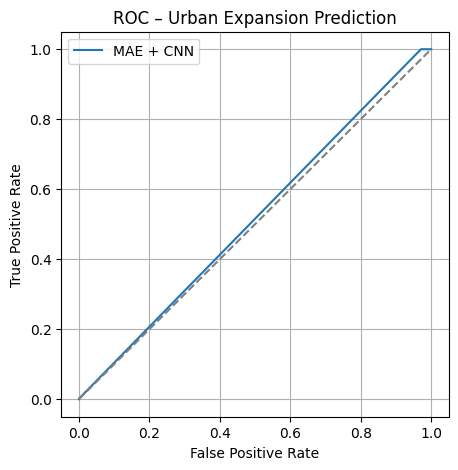

In [37]:
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_true, y_prob)

plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label="MAE + CNN")
plt.plot([0,1], [0,1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC – Urban Expansion Prediction")
plt.legend()
plt.grid(True)
plt.show()

# FOR TOTAL URBAN PIXEL CHANGE RATHER THAN 50%

In [124]:
import os
import glob
import numpy as np
import torch
from torch.utils.data import Dataset

class UrbanGrowthDataset(Dataset):
    def __init__(self, patch_dir):
        self.files = sorted(glob.glob(os.path.join(patch_dir, "*.npz")))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        x = data["x"]

        # Extract LULC channels and calculate the urban change to use as the 'y'
        lulc_2019 = x[8]
        lulc_2024 = x[9]

        urban_frac_2019 = np.mean(lulc_2019 == URBAN_CLASS)
        urban_frac_2024 = np.mean(lulc_2024 == URBAN_CLASS)

        y = urban_frac_2024 - urban_frac_2019

        # Remove the 2024 lulc (the y)
        x_features = np.concatenate([x[:9], x[10:]], axis=0)

        return torch.from_numpy(x_features).float(), torch.tensor(y, dtype=torch.float32)


In [125]:
"""
Used to test the effectiveness of using the 3 closest airports and schools as opposed to just the closest
"""

import os
import glob
import numpy as np
import torch
from torch.utils.data import Dataset

class UrbanGrowthDatasetClosestProx(Dataset):
    def __init__(self, patch_dir):
        self.files = sorted(glob.glob(os.path.join(patch_dir, "*.npz")))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        x = data["x"]

        # Labels (urban growth)
        lulc_2019 = x[8]
        lulc_2024 = x[9]

        urban_frac_2019 = np.mean(lulc_2019 == URBAN_CLASS)
        urban_frac_2024 = np.mean(lulc_2024 == URBAN_CLASS)

        y = urban_frac_2024 - urban_frac_2019

        # Core features
        dry_wet_lulc = x[:10]  # 0:4 dry, 4:8 wet, 8: lulc2019, 9: lulc2024

        # Only keeping closest infrastrucrure
        closest_school = x[10]
        closest_airport = x[13]

        closest_school = closest_school[None, :, :]
        closest_airport = closest_airport[None, :, :]

        # AuxMAE features
        auxmae = x[16:]

        # Remove lulc_2024 from inputs
        # Keep lulc_2019 only
        dry_wet_lulc = np.concatenate([dry_wet_lulc[:9]], axis=0)

        # Final feature stack
        x_features = np.concatenate([
            dry_wet_lulc,
            closest_school,
            closest_airport,
            auxmae
        ], axis=0)

        return torch.from_numpy(x_features).float(), torch.tensor(y, dtype=torch.float32)

In [60]:
dataset = UrbanGrowthDataset("data/patches")
x, y = dataset[5]
print(f"x shape: {x.shape}")
print(f"y value: {y.item():.4f}")

# Verify channel breakdown
print(f"Dry S2: channels 0-3 ({x[0:4].shape})")
print(f"Wet S2: channels 4-7 ({x[4:8].shape})")
print(f"LULC 2019 channel 8 ({x[8].shape})")
print(f"School: channels 9-11 ({x[9:12].shape})")
print(f"Airport: channels 12-14 ({x[12:15].shape})")
print(f"AuxMAE: channels 15-18 ({x[15:16].shape})")

x shape: torch.Size([16, 64, 64])
y value: 0.0293
Dry S2: channels 0-3 (torch.Size([4, 64, 64]))
Wet S2: channels 4-7 (torch.Size([4, 64, 64]))
LULC 2019 channel 8 (torch.Size([64, 64]))
School: channels 9-11 (torch.Size([3, 64, 64]))
Airport: channels 12-14 (torch.Size([3, 64, 64]))
AuxMAE: channels 15-18 (torch.Size([1, 64, 64]))


In [61]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class UrbanGrowthCNN(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(),
        )

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        return self.head(x).squeeze(1)


In [126]:
import torch
import torch.nn as nn

class UrbanGrowthCNNLarge(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        self.encoder = nn.Sequential(
            # Block 1
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4 (no pooling after final block)
            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.ReLU(),
        )

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        return self.head(x).squeeze(1)

In [63]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x)
            loss = criterion(pred, y)
            total_loss += loss.item() * x.size(0)

    return total_loss / len(loader.dataset)

In [64]:
import torch
from torch.utils.data import DataLoader
from torch.optim import Adam
from torch.nn import SmoothL1Loss

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32
# LR = 1.0536525243383263e-4
LR = 1e-4
# WEIGHT_DECAY = 1.034552520746944e-6
EPOCHS = 20
PATCH_DIR = "data/patches"

In [65]:
from torch.utils.data import random_split

# Initialize Dataset
print("Loading dataset...", PATCH_DIR)
full_dataset = UrbanGrowthDataset(PATCH_DIR)
N = len(full_dataset)

# Split datasets
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size

print(
    f"Total samples: {N} | "
    f"Train: {train_size} | "
    f"Val: {val_size} | "
    f"Test: {test_size}"
)

train_ds, val_ds, test_ds = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

Loading dataset... data/patches
Total samples: 214387 | Train: 160790 | Val: 32158 | Test: 21439


In [14]:
# from torch.utils.data import WeightedRandomSampler

# # 1. Calculate weights for the TRAINING set only
# print("Calculating weights for balancing...")
# train_targets = []

# # We have to loop through the train_ds to get the targets
# # (Note: This might take 30-60s depending on dataset size)
# for i in range(len(train_ds)):
#     _, y = train_ds[i]
#     train_targets.append(y.item())

# train_targets = np.array(train_targets)

# # 2. Define "Importance"
# # If y is 0, weight is small (e.g., 0.1). If y is high, weight is high.
# # We add a small epsilon (0.1) so zero-change patches still get picked occasionally.
# sample_weights = np.abs(train_targets) + 0.1 

# # Optional: Boost the weights of high-change areas even more
# # sample_weights[sample_weights > 0.1] *= 10 

# # 3. Create the Sampler
# sampler = WeightedRandomSampler(
#     weights=sample_weights,
#     num_samples=len(sample_weights),
#     replacement=True
# )

# print("Sampler ready.")

In [66]:
# Create Loaders
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Initialize Model
# Check the first sample to automatically set input channels
sample_x, _ = full_dataset[0]
in_channels = sample_x.shape[0]

In [67]:
PATCH_DIR

'data/patches'

In [68]:
print(f"Building model with {in_channels} input channels...")
model = UrbanGrowthCNNLarge(in_channels=in_channels).to(DEVICE)

optimizer = Adam(
    model.parameters(),
    lr=LR,
    # weight_decay=WEIGHT_DECAY
)
criterion = SmoothL1Loss()

# Training Loop
train_losses = []
val_losses = []
best_epoch = -1

print("Starting training...")
best_val_loss = float("inf")

for epoch in range(EPOCHS):
    # Train
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad()
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    avg_train_loss = train_loss / len(train_loader.dataset)

    # Validation
    avg_val_loss = evaluate(model, val_loader, criterion)

    # Store metrics
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f}"
    )

    # Save best model (based on validation only)
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "cnn_auxmae_no_decay.pt")
        print("=> New best model saved!")

# Save training history
np.save("train_losses_cnn_auxmae_no_decay.npy", train_losses)
np.save("val_losses_cnn_auxmae_no_decay.npy", val_losses)

with open("training_meta_cnn_auxmae_no_decay.txt", "w") as f:
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Best val loss: {best_val_loss:.6f}\n")

print("\nTraining complete.")

Building model with 16 input channels...
Starting training...
Epoch 01 | Train Loss: 0.004769 | Val Loss: 0.003561
=> New best model saved!
Epoch 02 | Train Loss: 0.003577 | Val Loss: 0.003198
=> New best model saved!
Epoch 03 | Train Loss: 0.003183 | Val Loss: 0.002906
=> New best model saved!
Epoch 04 | Train Loss: 0.002942 | Val Loss: 0.003031
Epoch 05 | Train Loss: 0.002786 | Val Loss: 0.002876
... (17 lines trimmed) ...
Epoch 16 | Train Loss: 0.001024 | Val Loss: 0.001916
=> New best model saved!
Epoch 17 | Train Loss: 0.000958 | Val Loss: 0.001852
=> New best model saved!
Epoch 18 | Train Loss: 0.000907 | Val Loss: 0.001885
Epoch 19 | Train Loss: 0.000846 | Val Loss: 0.001741
=> New best model saved!
Epoch 20 | Train Loss: 0.000789 | Val Loss: 0.002226

Training complete.


In [70]:
# Save training history
np.save("train_losses_cnn_auxmae_no_decay.npy", train_losses)
np.save("val_losses_cnn_auxmae_no_decay.npy", val_losses)

with open("training_meta_cnn_auxmae_no_decay.txt", "w") as f:
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Best val loss: {best_val_loss:.6f}\n")

In [71]:
# Load best model
model.load_state_dict(
    torch.load("cnn_auxmae_no_decay.pt")
)

# Final evaluation
test_loss = evaluate(model, test_loader, criterion)
print(f"Final Test Loss: {test_loss:.6f}")

Final Test Loss: 0.001777


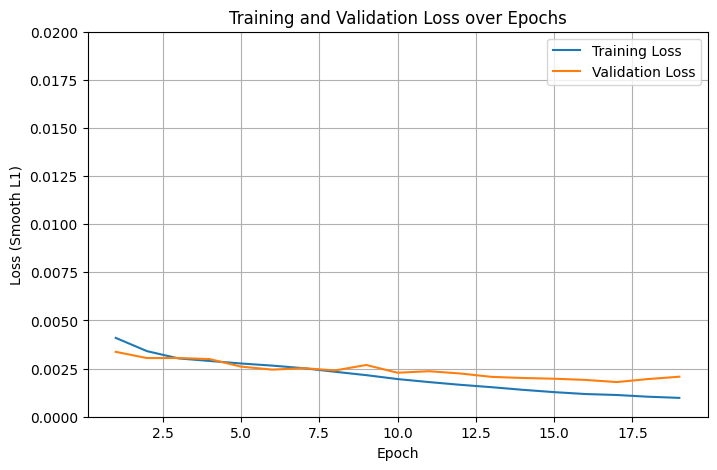

In [57]:
# Load logged losses
train_losses = np.load("train_losses_cnn_auxmae_closest_prox.npy")
val_losses = np.load("val_losses_cnn_auxmae_closest_prox.npy")

epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (Smooth L1)")
plt.title("Training and Validation Loss over Epochs")
plt.legend()
plt.grid(True)
plt.ylim(0.0, 0.02)
plt.show()

In [25]:
# Same as AuxMAE augmented dataset just with the AuxMAE channels removed
class UrbanGrowthDatasetBaseline(Dataset):
    def __init__(self, patch_dir):
        self.files = sorted(glob.glob(os.path.join(patch_dir, "*.npz")))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        x = data["x"] # (20, H, W)

        lulc_2019 = x[8]
        lulc_2024 = x[9]
        urban_frac_2019 = np.mean(lulc_2019 == URBAN_CLASS)
        urban_frac_2024 = np.mean(lulc_2024 == URBAN_CLASS)
        y = urban_frac_2024 - urban_frac_2019

        x_features = np.concatenate([x[:9], x[10:16]], axis=0) # drop lulc_2024 and auxmae
        return torch.from_numpy(x_features).float(), torch.tensor(y, dtype=torch.float32)

In [26]:
ds = UrbanGrowthDatasetBaseline("data/patches")
x, y = ds[0]
print(f"x shape: {x.shape}")

x shape: torch.Size([15, 64, 64])


In [72]:
# Baseline dataset
full_dataset_baseline = UrbanGrowthDatasetBaseline("data/patches")
N = len(full_dataset_baseline)
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size
_, _, test_ds_baseline = random_split(
    full_dataset_baseline,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)
test_loader_baseline = DataLoader(test_ds_baseline, batch_size=BATCH_SIZE, shuffle=False)

# AuxMAE dataset
full_dataset_auxmae = UrbanGrowthDataset("data/patches")
_, _, test_ds_auxmae = random_split(
    full_dataset_auxmae,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)
test_loader_auxmae = DataLoader(test_ds_auxmae, batch_size=BATCH_SIZE, shuffle=False)

# Verify shapes
x_base, _ = test_ds_baseline[0]
x_aux, _ = test_ds_auxmae[0]
print(f"Baseline input channels: {x_base.shape[0]}")  # should be 15
print(f"AuxMAE input channels: {x_aux.shape[0]}")   # should be 19

# Comparing against strongest baseline
baseline_model = UrbanGrowthCNNLarge(in_channels=15).to(DEVICE)
baseline_model.load_state_dict(torch.load("best_urban_growth_model_64_large.pt", map_location=DEVICE))
baseline_model.eval()
baseline_test_loss = evaluate(baseline_model, test_loader_baseline, criterion)

auxmae_cnn_model = UrbanGrowthCNNLarge(in_channels=x_aux.shape[0]).to(DEVICE)
auxmae_cnn_model.load_state_dict(torch.load("cnn_auxmae_no_decay.pt", map_location=DEVICE))
auxmae_cnn_model.eval()
auxmae_test_loss = evaluate(auxmae_cnn_model, test_loader_auxmae, criterion)

print(f"Baseline test loss: {baseline_test_loss:.6f}")
print(f"AuxMAE test loss: {auxmae_test_loss:.6f}")
print(f"Improvement: {(baseline_test_loss - auxmae_test_loss):.6f}")
print(f"Relative improvement: {(baseline_test_loss - auxmae_test_loss) / baseline_test_loss * 100:.2f}%")

Baseline input channels: 15
AuxMAE input channels: 16
Baseline test loss: 0.001349
AuxMAE test loss: 0.001777
Improvement: -0.000428
Relative improvement: -31.76%


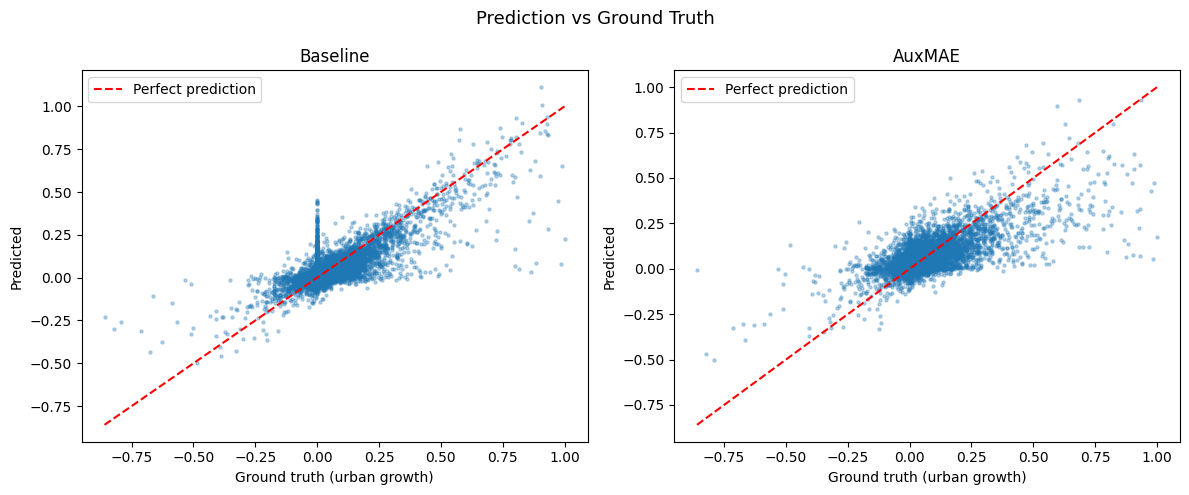

In [73]:
def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            all_preds.extend(pred.cpu().numpy())
            all_targets.extend(y.cpu().numpy())
    return np.array(all_preds), np.array(all_targets)

preds_base, targets = get_predictions(baseline_model, test_loader_baseline, DEVICE)
preds_aux, _ = get_predictions(auxmae_cnn_model, test_loader_auxmae, DEVICE)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, preds, title in zip(axes, [preds_base, preds_aux], ["Baseline", "AuxMAE"]):
    ax.scatter(targets, preds, alpha=0.3, s=5)
    ax.plot([targets.min(), targets.max()],
            [targets.min(), targets.max()], "r--", label="Perfect prediction")
    ax.set_xlabel("Ground truth (urban growth)")
    ax.set_ylabel("Predicted")
    ax.set_title(title)
    ax.legend()

plt.suptitle("Prediction vs Ground Truth", fontsize=13)
plt.tight_layout()
plt.savefig("prediction_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [74]:
from sklearn.metrics import r2_score, mean_absolute_error

for preds, title in [(preds_base, "Baseline"), (preds_aux, "AuxMAE")]:
    mae = mean_absolute_error(targets, preds)
    r2 = r2_score(targets, preds)
    rmse = np.sqrt(np.mean((preds - targets) ** 2))
    print(f"{title}:")
    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R2: {r2:.4f}")

Baseline:
MAE: 0.027433
RMSE: 0.051934
R2: 0.6592
AuxMAE:
MAE: 0.027267
RMSE: 0.059613
R2: 0.5509


Patches where AuxMAE is WORSE than baseline:
Mean error increase: 0.5061
Target values: 0.6758 mean, 0.2990 std

Patches where AuxMAE is BETTER than baseline:
Mean error decrease: -0.3752
Target values: 0.0303 mean, 0.1322 std


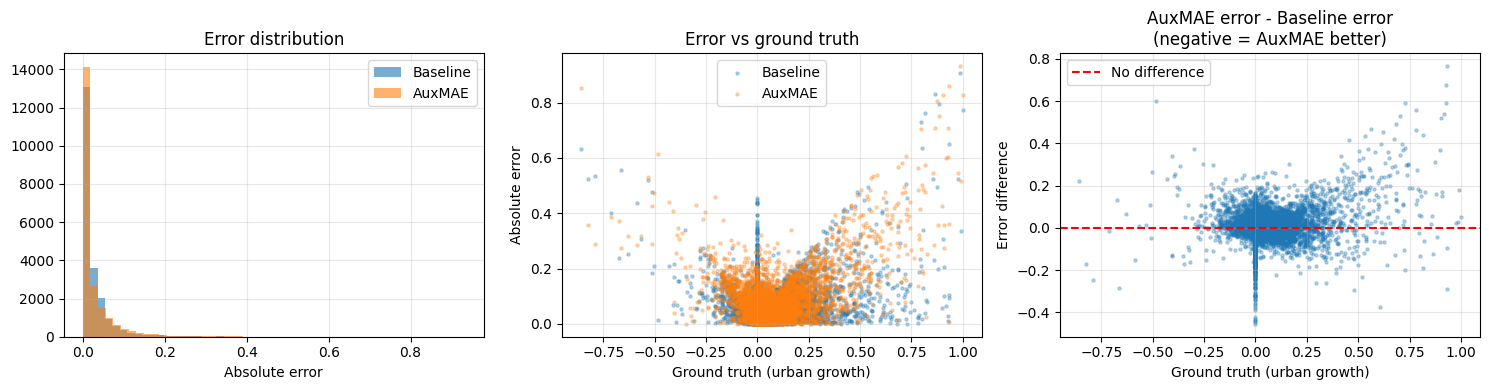

In [75]:
preds_base, targets_base = get_predictions(baseline_model, test_loader_baseline, DEVICE)
preds_aux, targets_aux = get_predictions(auxmae_cnn_model, test_loader_auxmae, DEVICE)

errors_base = np.abs(preds_base - targets_base)
errors_aux = np.abs(preds_aux - targets_aux)

# Where does AuxMAE do much worse than baseline?
diff = errors_aux - errors_base
worst_idx = np.argsort(diff)[-20:] # 20 patches where AuxMAE is worst relative to baseline
best_idx = np.argsort(diff)[:20] # 20 patches where AuxMAE is better

print("Patches where AuxMAE is WORSE than baseline:")
print(f"Mean error increase: {diff[worst_idx].mean():.4f}")
print(f"Target values: {targets_base[worst_idx].mean():.4f} mean, {targets_base[worst_idx].std():.4f} std")

print("\nPatches where AuxMAE is BETTER than baseline:")
print(f"Mean error decrease: {diff[best_idx].mean():.4f}")
print(f"Target values: {targets_base[best_idx].mean():.4f} mean, {targets_base[best_idx].std():.4f} std")

# Error distribution comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(errors_base, bins=50, alpha=0.6, label="Baseline")
axes[0].hist(errors_aux, bins=50, alpha=0.6, label="AuxMAE")
axes[0].set_title("Error distribution")
axes[0].set_xlabel("Absolute error")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(targets_base, errors_base, alpha=0.3, s=5, label="Baseline")
axes[1].scatter(targets_aux, errors_aux, alpha=0.3, s=5, label="AuxMAE")
axes[1].set_title("Error vs ground truth")
axes[1].set_xlabel("Ground truth (urban growth)")
axes[1].set_ylabel("Absolute error")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].scatter(targets_base, diff, alpha=0.3, s=5)
axes[2].axhline(0, color="red", linestyle="--", label="No difference")
axes[2].set_title("AuxMAE error - Baseline error\n(negative = AuxMAE better)")
axes[2].set_xlabel("Ground truth (urban growth)")
axes[2].set_ylabel("Error difference")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [76]:
# Split test set into zero-change and non-zero-change patches
zero_mask = np.abs(targets_base) < 0.01  # essentially no urban change
nonzero_mask = ~zero_mask

print(f"Zero-change patches: {zero_mask.sum()} ({zero_mask.mean()*100:.1f}%)")
print(f"Nonzero patches: {nonzero_mask.sum()} ({nonzero_mask.mean()*100:.1f}%)")

for preds, name in [(preds_base, "Baseline"), (preds_aux, "AuxMAE")]:
    print(f"\n{name}:")
    print(f"R2 on zero-change: {r2_score(targets_base[zero_mask], preds[zero_mask]):.4f}")
    print(f"R2 on nonzero: {r2_score(targets_base[nonzero_mask], preds[nonzero_mask]):.4f}")
    print(f"MAE on zero-change: {mean_absolute_error(targets_base[zero_mask], preds[zero_mask]):.6f}")
    print(f"MAE on nonzero: {mean_absolute_error(targets_base[nonzero_mask], preds[nonzero_mask]):.6f}")

Zero-change patches: 13152 (61.3%)
Nonzero patches: 8287 (38.7%)

Baseline:
R2 on zero-change: -205.8322
R2 on nonzero: 0.7068
MAE on zero-change: 0.016203
MAE on nonzero: 0.045254

AuxMAE:
R2 on zero-change: -70.4285
R2 on nonzero: 0.5170
MAE on zero-change: 0.007942
MAE on nonzero: 0.057938


# Hyperparam Finetuning (CNN)

In [20]:
class UrbanGrowthCNN(nn.Module):
    def __init__(self, in_channels, base_channels=32, depth=3):
        super().__init__()

        layers = []
        c_in = in_channels
        c = base_channels

        for d in range(depth):
            layers.append(nn.Conv2d(c_in, c, 3, padding=1))
            layers.append(nn.ReLU())
            layers.append(nn.Conv2d(c, c, 3, padding=1))
            layers.append(nn.ReLU())

            if d < depth - 1:
                layers.append(nn.MaxPool2d(2))

            c_in = c
            c *= 2

        self.encoder = nn.Sequential(*layers)

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(c_in, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        return self.head(x).squeeze(1)

In [25]:
def build_model(arch_name, in_channels):
    if arch_name == "small":
        # Shallow
        return UrbanGrowthCNN(
            in_channels=in_channels,
            base_channels=16,
            depth=2
        )
    elif arch_name == "medium":
        # Default CNN
        return UrbanGrowthCNN(
            in_channels=in_channels,
            base_channels=32,
            depth=3
        )
    elif arch_name == "large":
        # Deeper CNN
        return UrbanGrowthCNN(
            in_channels=in_channels,
            base_channels=32,
            depth=4
        )
    else:
        raise ValueError(f"Unknown architecture: {arch_name}")

In [21]:
import torch
from torch.utils.data import DataLoader
from torch.optim import Adam
from torch.nn import SmoothL1Loss

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PATCH_DIR = "data/patches"

In [22]:
from torch.utils.data import random_split

# Initialize Dataset
print("Loading dataset...", PATCH_DIR)
full_dataset = UrbanGrowthDataset(PATCH_DIR)
N = len(full_dataset)

# Get input channels from first sample
sample_x, _ = full_dataset[0]
in_channels = sample_x.shape[0]
print(f"Input channels: {in_channels}")

# Split datasets
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size

print(
    f"Total samples: {N} | "
    f"Train: {train_size} | "
    f"Val: {val_size} | "
    f"Test: {test_size}"
)

train_ds, val_ds, test_ds = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

Loading dataset... patches_npz
Input channels: 15
Total samples: 114385 | Train: 85788 | Val: 17157 | Test: 11440


In [28]:
# Create Loaders
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Initialize Model
# We check the first sample to automatically set input channels
sample_x, _ = full_dataset[0]
in_channels = sample_x.shape[0]

In [32]:
import logging
import optuna
from optuna.pruners import MedianPruner
from torch.utils.data import DataLoader

def objective(trial, arch_name):
    lr = trial.suggest_float("lr", 1e-4, 3e-3, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)

    model = build_model(arch_name, in_channels).to(DEVICE)

    optimizer = Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )
    criterion = SmoothL1Loss()

    TUNE_EPOCHS = 6
    best_val = float("inf")

    for epoch in tqdm(range(TUNE_EPOCHS)):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        val_loss = evaluate(model, val_loader, criterion)
        trial.report(val_loss, epoch)

        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        best_val = min(best_val, val_loss)

    return best_val

In [33]:
architectures = ["small", "medium", "large"]
studies = {}

for arch in architectures:
    print(f"\nOptimising {arch} architecture")

    study = optuna.create_study(
        direction="minimize",
        study_name=f"cnn_{arch}",
        pruner=optuna.pruners.MedianPruner(n_warmup_steps=2)
    )

    study.optimize(
        lambda trial: objective(trial, arch),
        n_trials=20,
        show_progress_bar=True
    )

    studies[arch] = study


=== Optimising small architecture ===


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-02-09 20:45:05,850] Trial 0 finished with value: 0.006375292156393986 and parameters: {'lr': 0.0005392809543052038, 'weight_decay': 2.656774299581462e-05}. Best is trial 0 with value: 0.006375292156393986.


[I 2026-02-09 21:21:43,291] Trial 1 finished with value: 0.006741297895350107 and parameters: {'lr': 0.0017703923729704893, 'weight_decay': 0.00017903460178997856}. Best is trial 0 with value: 0.006375292156393986.


[I 2026-02-09 23:52:46,487] Trial 2 finished with value: 0.0064016586044031805 and parameters: {'lr': 0.00012751403020481344, 'weight_decay': 1.601982767797846e-05}. Best is trial 0 with value: 0.006375292156393986.


[I 2026-02-10 00:30:34,532] Trial 3 finished with value: 0.0063898811040642885 and parameters: {'lr': 0.00024691563243760267, 'weight_decay': 0.00029878426872988423}. Best is trial 0 with value: 0.006375292156393986.


... (54 outputs left out)

[I 2026-02-11 10:45:38,159] Trial 16 pruned. 


[I 2026-02-11 11:24:21,932] Trial 17 finished with value: 0.00543239119336951 and parameters: {'lr': 0.0003881121764075938, 'weight_decay': 2.4536161253757337e-06}. Best is trial 14 with value: 0.005047739767869255.


[I 2026-02-11 12:03:12,395] Trial 18 finished with value: 0.005417283320816134 and parameters: {'lr': 0.00016381584605001376, 'weight_decay': 5.485630332100224e-06}. Best is trial 14 with value: 0.005047739767869255.


[I 2026-02-11 12:35:18,014] Trial 19 pruned. 


In [34]:
for arch, study in studies.items():
    print(f"\n=== {arch.upper()} ===")
    print(f"Best validation loss: {study.best_value:.6f}")
    print("Best hyperparameters:")
    for k, v in study.best_trial.params.items():
        print(f"  {k}: {v}")


=== SMALL ===
Best validation loss: 0.006103
Best hyperparameters:
  lr: 0.0003103003859630326
  weight_decay: 3.800667108561135e-06

=== MEDIUM ===
Best validation loss: 0.005223
Best hyperparameters:
  lr: 0.00019469996004166948
  weight_decay: 1.1147791624105492e-06

=== LARGE ===
Best validation loss: 0.005048
Best hyperparameters:
  lr: 0.00010536525243383263
  weight_decay: 1.034552520746944e-06


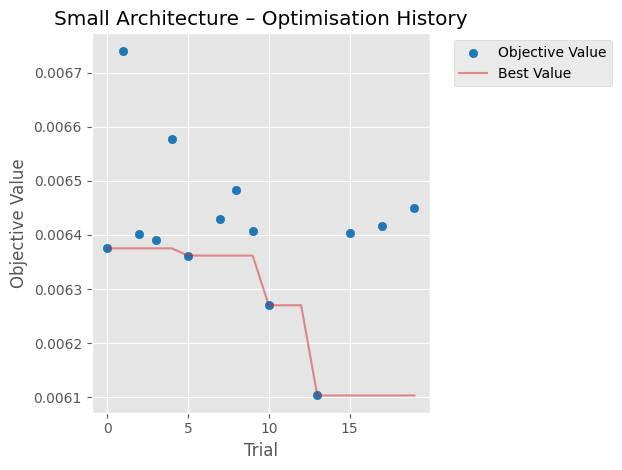

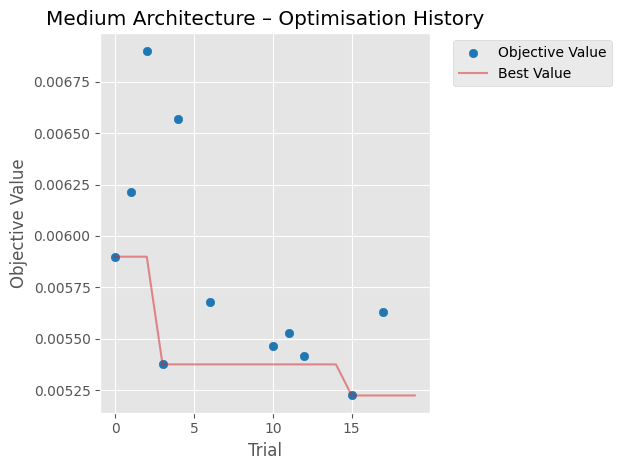

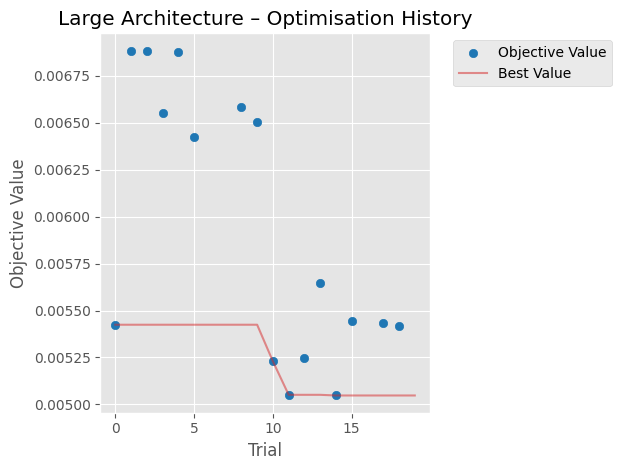

In [35]:
import optuna.visualization.matplotlib as optuna_vis
import matplotlib.pyplot as plt

for arch, study in studies.items():
    fig = optuna_vis.plot_optimization_history(study)
    plt.title(f"{arch.capitalize()} Architecture - Optimisation History")
    plt.show()

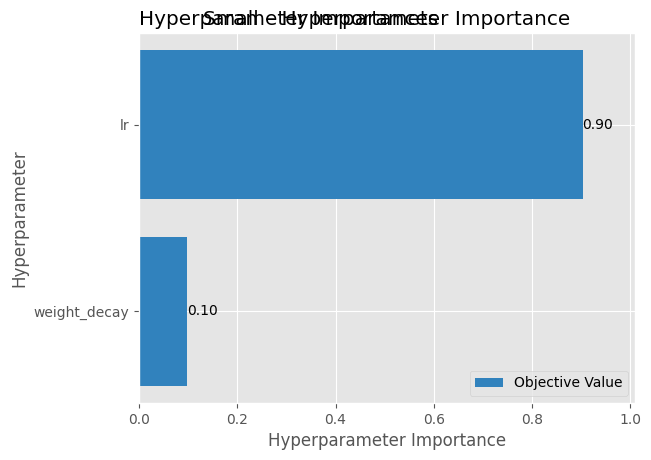

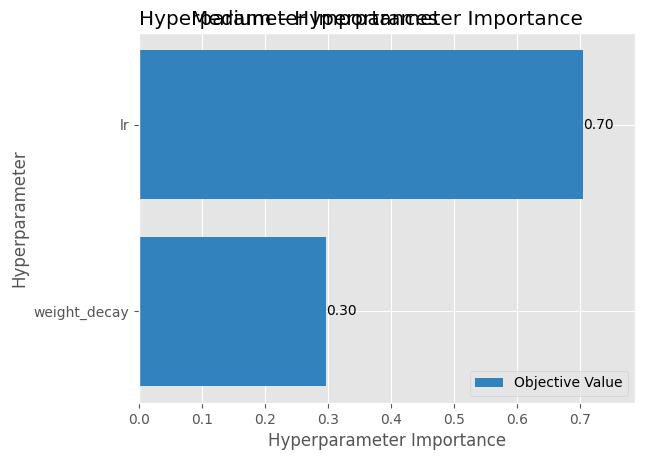

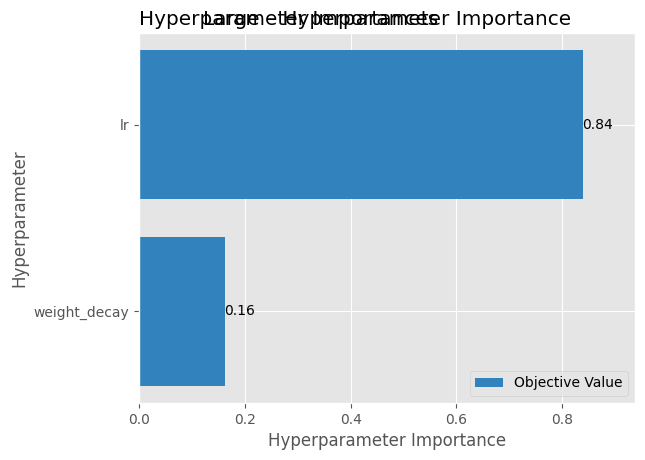

In [36]:
for arch, study in studies.items():
    fig = optuna_vis.plot_param_importances(study)
    plt.title(f"{arch.capitalize()} – Hyperparameter Importance")
    plt.show()

# 32x32 Evaluation for Report

Running final evaluation on held-out Test Set...

--- FINAL TEST RESULTS ---
Model MAE:     0.111617
Model MSE:     0.028919
Model R²:      0.1275
Zero MAE:      0.109444
Mean MAE:      0.117356


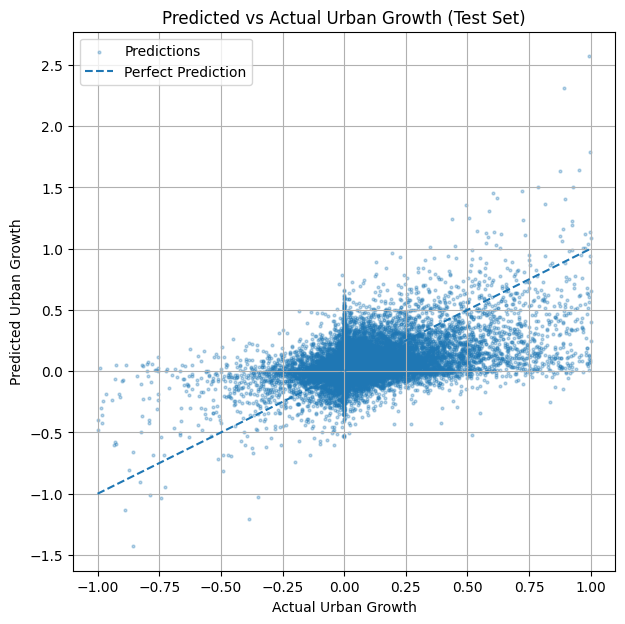

In [34]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load best model (selected on validation performance)
model = UrbanGrowthCNN(in_channels=in_channels).to(DEVICE)
model.load_state_dict(
    torch.load("best_urban_growth_model_32_fixed.pt", map_location=DEVICE)
)
model.eval()

print("Running final evaluation on held-out Test Set...")

# Collect predictions and targets
all_preds = []
all_targets = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        preds = model(x)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y.numpy())

y_true = np.array(all_targets)
y_pred = np.array(all_preds)

# Metrics
model_mae = mean_absolute_error(y_true, y_pred)
model_mse = mean_squared_error(y_true, y_pred)
model_r2 = r2_score(y_true, y_pred)

# Baseline 1: predict zero change
zeros_pred = np.zeros_like(y_true)
base_mae = mean_absolute_error(y_true, zeros_pred)

# Baseline 2: predict mean
mean_pred = np.full_like(y_true, y_true.mean())
mean_mae = mean_absolute_error(y_true, mean_pred)

print("\n FINAL TEST RESULTS ")
print(f"Model MAE: {model_mae:.6f}")
print(f"Model MSE: {model_mse:.6f}")
print(f"Model R2: {model_r2:.4f}")
print(f"Zero MAE: {base_mae:.6f}")
print(f"Mean MAE: {mean_mae:.6f}")

# Make and show scatter plot
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, alpha=0.3, s=4, label="Predictions")

lims = [
    min(y_true.min(), y_pred.min()),
    max(y_true.max(), y_pred.max())
]
plt.plot(lims, lims, linestyle="--", label="Perfect Prediction")

plt.xlabel("Actual Urban Growth")
plt.ylabel("Predicted Urban Growth")
plt.title("Predicted vs Actual Urban Growth (Test Set)")
plt.legend()
plt.grid(True)
plt.show()


32x32

In [17]:
PATCH_DIR = "patches_npz_32"

In [20]:
from torch.utils.data import random_split

# Initialize Dataset
print("Loading dataset...", PATCH_DIR)
full_dataset = UrbanGrowthDataset(PATCH_DIR)
N = len(full_dataset)

# Split datasets
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size

print(
    f"Total samples: {N} | "
    f"Train: {train_size} | "
    f"Val: {val_size} | "
    f"Test: {test_size}"
)

train_ds, val_ds, test_ds = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

Loading dataset... patches_npz_32
Total samples: 253331 | Train: 189998 | Val: 37999 | Test: 25334


In [21]:
# Create loaders
train_loader_32 = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader_32 = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader_32 = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Initialise model
sample_x, _ = full_dataset[0]
in_channels = sample_x.shape[0]

print(f"Building 32x32 model with {in_channels} input channels...")
model_32 = UrbanGrowthCNN(in_channels=in_channels).to(DEVICE)

optimizer_32 = Adam(model_32.parameters(), lr=LR)
criterion_32 = SmoothL1Loss()

# Training loop
train_losses_32 = []
val_losses_32 = []
best_epoch_32 = -1

print("Starting 32x32 training...")
best_val_loss_32 = float("inf")

for epoch in range(EPOCHS):
    # Train
    model_32.train()
    train_loss = 0.0

    for x, y in train_loader_32:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer_32.zero_grad()
        pred = model_32(x)
        loss = criterion_32(pred, y)
        loss.backward()
        optimizer_32.step()

        train_loss += loss.item() * x.size(0)

    avg_train_loss = train_loss / len(train_loader_32.dataset)

    # Validation
    avg_val_loss = evaluate(model_32, val_loader_32, criterion_32)

    # Store metrics
    train_losses_32.append(avg_train_loss)
    val_losses_32.append(avg_val_loss)

    print(
        f"[32x32] Epoch {epoch+1:02d} | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f}"
    )

    # Save best model (validation-based)
    if avg_val_loss < best_val_loss_32:
        best_val_loss_32 = avg_val_loss
        best_epoch_32 = epoch + 1
        torch.save(
            model_32.state_dict(),
            "best_urban_growth_model_32_fixed.pt"
        )
        print("=> New best 32x32 model saved!")

# Save training logs
np.save("train_losses_32.npy", train_losses_32)
np.save("val_losses_32.npy", val_losses_32)

with open("training_meta_32.txt", "w") as f:
    f.write(f"Best epoch: {best_epoch_32}\n")
    f.write(f"Best val loss: {best_val_loss_32:.6f}\n")

print("\n32x32 training complete.")

Building 32x32 model with 15 input channels...
Starting 32x32 training...
[32x32] Epoch 01 | Train Loss: 0.018137 | Val Loss: 0.015416
=> New best 32x32 model saved!
[32x32] Epoch 02 | Train Loss: 0.014978 | Val Loss: 0.014882
=> New best 32x32 model saved!
[32x32] Epoch 03 | Train Loss: 0.014392 | Val Loss: 0.014029
=> New best 32x32 model saved!
[32x32] Epoch 04 | Train Loss: 0.013939 | Val Loss: 0.013618
=> New best 32x32 model saved!
... (17 lines trimmed) ...
=> New best 32x32 model saved!
[32x32] Epoch 15 | Train Loss: 0.008923 | Val Loss: 0.012330
[32x32] Epoch 16 | Train Loss: 0.008296 | Val Loss: 0.012799
[32x32] Epoch 17 | Train Loss: 0.007724 | Val Loss: 0.012211
=> New best 32x32 model saved!
[32x32] Epoch 18 | Train Loss: 0.007210 | Val Loss: 0.012587
[32x32] Epoch 19 | Train Loss: 0.006796 | Val Loss: 0.012356
[32x32] Epoch 20 | Train Loss: 0.006301 | Val Loss: 0.012521

32x32 training complete.


In [22]:
# Load best model
model.load_state_dict(
    torch.load("best_urban_growth_model_32_fixed.pt")
)

# Final evaluation
test_loss = evaluate(model, test_loader, criterion)
print(f"Final Test Loss: {test_loss:.6f}")

Final Test Loss: 0.003414


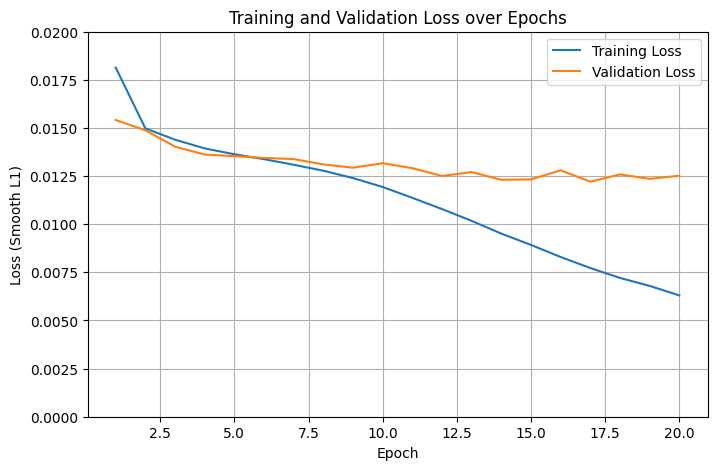

In [24]:
# Load logged losses
train_losses = np.load("train_losses_32.npy")
val_losses = np.load("val_losses_32.npy")

epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (Smooth L1)")
plt.title("Training and Validation Loss over Epochs")
plt.legend()
plt.grid(True)
plt.ylim(0.0, 0.02)
plt.show()

Running final evaluation on held-out Test Set...

--- FINAL TEST RESULTS ---
Model MAE:     0.101941
Model MSE:     0.024515
Model R²:      0.2603
Zero MAE:      0.109444
Mean MAE:      0.117356


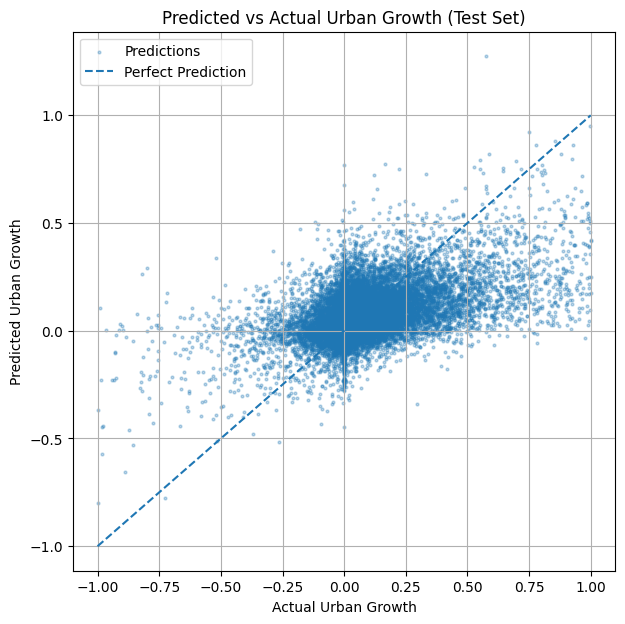

In [33]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load best model (selected on VALIDATION)
model = UrbanGrowthCNN(in_channels=in_channels).to(DEVICE)
model.load_state_dict(
    torch.load("best_urban_growth_model_32_fixed.pt", map_location=DEVICE)
)
model.eval()

print("Running final evaluation on held-out Test Set...")

# Collect predictions and targets
all_preds = []
all_targets = []

with torch.no_grad():
    for x, y in test_loader_32:
        x = x.to(DEVICE)
        preds = model(x)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y.numpy())

y_true = np.array(all_targets)
y_pred = np.array(all_preds)

# Metrics
model_mae = mean_absolute_error(y_true, y_pred)
model_mse = mean_squared_error(y_true, y_pred)
model_r2  = r2_score(y_true, y_pred)

# Baseline 1: predict zero change
zeros_pred = np.zeros_like(y_true)
base_mae = mean_absolute_error(y_true, zeros_pred)

# Baseline 2: predict mean
mean_pred = np.full_like(y_true, y_true.mean())
mean_mae = mean_absolute_error(y_true, mean_pred)

print("\nFinal test results:")
print(f"Model MAE: {model_mae:.6f}")
print(f"Model MSE: {model_mse:.6f}")
print(f"Model R2: {model_r2:.4f}")
print(f"Zero MAE: {base_mae:.6f}")
print(f"Mean MAE: {mean_mae:.6f}")

# Scatter plot: Predictions vs Ground Truth
plt.figure(figsize=(7, 7))
plt.scatter(y_true, y_pred, alpha=0.3, s=4, label="Predictions")

lims = [
    min(y_true.min(), y_pred.min()),
    max(y_true.max(), y_pred.max())
]
plt.plot(lims, lims, linestyle="--", label="Perfect Prediction")

plt.xlabel("Actual Urban Growth")
plt.ylabel("Predicted Urban Growth")
plt.title("Predicted vs Actual Urban Growth (Test Set)")
plt.legend()
plt.grid(True)
plt.show()


# Random Forest

Extracting features from 189998 patches...


Extracting features from 25334 patches...


Training features shape: (189998, 30)
Training Random Forest...


Evaluating...



--- Random Forest Results ---
MAE: 0.088581
MSE: 0.020204


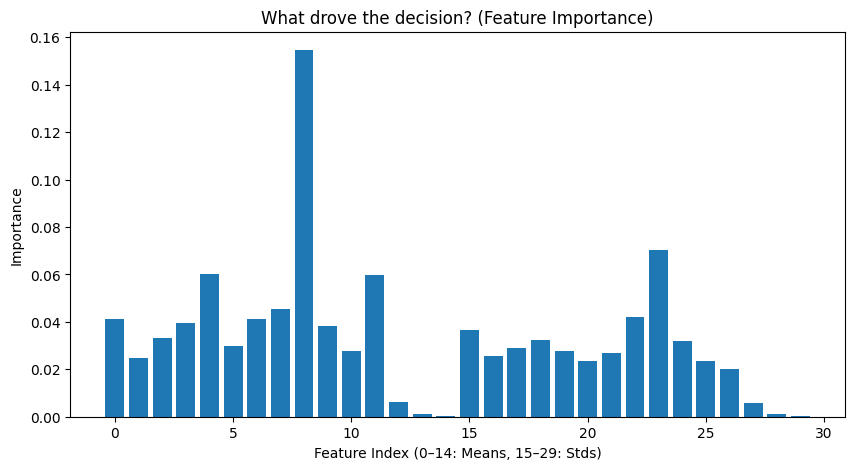

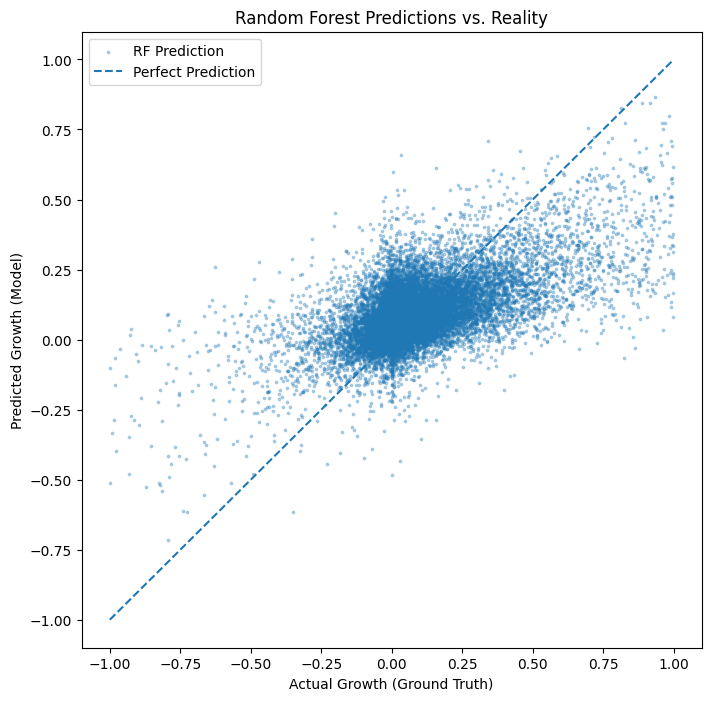

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
from tqdm import tqdm

BATCH_SIZE = 1000

def extract_tabular_features(loader):
    print(f"Extracting features from {len(loader.dataset)} patches...")
    X_list = []
    y_list = []

    for images, targets in tqdm(loader):
        means = torch.mean(images, dim=[2, 3])
        stds  = torch.std(images, dim=[2, 3])

        features = torch.cat([means, stds], dim=1)

        X_list.append(features.numpy())
        y_list.append(targets.numpy())

    return np.vstack(X_list), np.hstack(y_list)

# Uses same split as CNN
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# Extract features
X_train, y_train = extract_tabular_features(train_loader)
X_test, y_test = extract_tabular_features(test_loader)

print(f"Training features shape: {X_train.shape}")

# Train the RF model
print("Training Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=100,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_model.fit(X_train, y_train)

# Evaluate
print("Evaluating...")
y_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("\nRandom Forest Results")
print(f"MAE: {mae:.6f}")
print(f"MSE: {mse:.6f}")

# Feature importance
num_features = len(rf_model.feature_importances_)
half_features = num_features // 2

plt.figure(figsize=(10, 5))
plt.bar(range(num_features), rf_model.feature_importances_)
plt.title("Feature Importance")
plt.xlabel(
    f"Feature Index (0–{half_features-1}: Means, "
    f"{half_features}–{num_features-1}: Stds)"
)
plt.ylabel("Importance")
plt.show()

# Plot actual vs predicted
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.3, s=3, label="RF Prediction")

max_lim = max(y_test.max(), y_pred.max())
min_lim = min(y_test.min(), y_pred.min())

plt.plot([min_lim, max_lim], [min_lim, max_lim], "--", label="Perfect Prediction")

plt.xlabel("Actual Growth (Ground Truth)")
plt.ylabel("Predicted Growth (Model)")
plt.title("Random Forest Predictions vs. Reality")
plt.legend()
plt.show()


In [ ]:
# Define channel names
channel_names = [
    "Dry_1", "Dry_2", "Dry_3", "Dry_4",
    "Wet_1", "Wet_2", "Wet_3", "Wet_4",
    "LULC_2019",
    "School_1", "School_2", "School_3",
    "Airport_1", "Airport_2", "Airport_3"
]

# Create feature names for Mean and Std
feature_names = [f"Mean_{c}" for c in channel_names] + [f"Std_{c}" for c in channel_names]

# Create a DataFrame of importances
df_imp = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(df_imp.head(10))

           Feature  Importance
8   Mean_LULC_2019    0.154645
23   Std_LULC_2019    0.070311
4       Mean_Wet_1    0.060252
11   Mean_School_3    0.059958
7       Mean_Wet_4    0.045280
22       Std_Wet_4    0.041931
6       Mean_Wet_3    0.041138
0       Mean_Dry_1    0.041127
3       Mean_Dry_4    0.039500
9    Mean_School_1    0.038103


In [32]:
import joblib

# Save to a file
joblib.dump(rf_model, "urban_growth_rf.joblib")

print("Model saved successfully!")

# # Load from file
# loaded_model = joblib.load("urban_growth_rf.joblib")

Model saved successfully!


In [11]:
from torch.utils.data import random_split

# Initialize Dataset
print("Loading dataset...", CNN_PATCHES_OUT_DIR)
full_dataset = UrbanGrowthDatasetBaseline(CNN_PATCHES_OUT_DIR)
N = len(full_dataset)

# Split datasets
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size

print(
    f"Total samples: {N} | "
    f"Train: {train_size} | "
    f"Val: {val_size} | "
    f"Test: {test_size}"
)

train_ds, val_ds, test_ds = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

Loading dataset... data/patches
Total samples: 139269 | Train: 104451 | Val: 20890 | Test: 13928


In [12]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tqdm import tqdm
import joblib
import os

BATCH_SIZE = 1000
SAVE_DIR = "rf_models"
os.makedirs(SAVE_DIR, exist_ok=True)

def extract_tabular_features(loader):
    print(f"Extracting features from {len(loader.dataset)} patches...")
    X_list = []
    y_list = []

    for images, targets in tqdm(loader):
        means = torch.mean(images, dim=[2, 3])
        stds  = torch.std(images, dim=[2, 3])

        features = torch.cat([means, stds], dim=1)

        X_list.append(features.numpy())
        y_list.append(targets.numpy())

    return np.vstack(X_list), np.hstack(y_list)

# Data loaders (same as CNN)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Extract features once
X_train, y_train = extract_tabular_features(train_loader)
X_test, y_test = extract_tabular_features(test_loader)

print(f"Training features shape: {X_train.shape}")

# Hyperparameters to test
n_estimators_list = [50, 100, 200]
max_depth_list = [None, 10, 20]

results = []

for n_estimators in n_estimators_list:
    for max_depth in max_depth_list:

        depth_name = "none" if max_depth is None else str(max_depth)
        model_name = f"rf_{n_estimators}_{depth_name}_depth"
        model_path = os.path.join(SAVE_DIR, f"{model_name}.joblib")

        print(f"\nTraining {model_name}")

        rf_model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            n_jobs=-1,
            random_state=42,
            verbose=1
        )

        rf_model.fit(X_train, y_train)

        # Save model
        joblib.dump(rf_model, model_path)
        print(f"Saved model to {model_path}")

        # Evaluate
        y_pred = rf_model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)

        print(f"{model_name} -> MAE: {mae:.6f}, MSE: {mse:.6f}")

        results.append({
            "model": model_name,
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "MAE": mae,
            "MSE": mse
        })

# Print summary
print("\nSummary:")
for r in results:
    print(r)

Extracting features from 104451 patches...


Extracting features from 13928 patches...


Training features shape: (104451, 30)

Training rf_50_none_depth


Saved model to rf_models\rf_50_none_depth.joblib
rf_50_none_depth -> MAE: 0.038100, MSE: 0.015420

Training rf_50_10_depth


Saved model to rf_models\rf_50_10_depth.joblib
rf_50_10_depth -> MAE: 0.037164, MSE: 0.015215

Training rf_50_20_depth


Saved model to rf_models\rf_50_20_depth.joblib
rf_50_20_depth -> MAE: 0.037675, MSE: 0.015304

Training rf_100_none_depth


... (2 outputs left out)

Saved model to rf_models\rf_100_20_depth.joblib
rf_100_20_depth -> MAE: 0.037630, MSE: 0.015222

Training rf_200_none_depth


Saved model to rf_models\rf_200_none_depth.joblib
rf_200_none_depth -> MAE: 0.037863, MSE: 0.015182

Training rf_200_10_depth


Saved model to rf_models\rf_200_10_depth.joblib
rf_200_10_depth -> MAE: 0.037109, MSE: 0.015160

Training rf_200_20_depth


Saved model to rf_models\rf_200_20_depth.joblib
rf_200_20_depth -> MAE: 0.037518, MSE: 0.015136

Summary:
{'model': 'rf_50_none_depth', 'n_estimators': 50, 'max_depth': None, 'MAE': 0.038099704439772425, 'MSE': 0.015419577850811429}
{'model': 'rf_50_10_depth', 'n_estimators': 50, 'max_depth': 10, 'MAE': 0.03716410663931376, 'MSE': 0.015214645863734567}
{'model': 'rf_50_20_depth', 'n_estimators': 50, 'max_depth': 20, 'MAE': 0.03767452056996208, 'MSE': 0.015304458286947214}
{'model': 'rf_100_none_depth', 'n_estimators': 100, 'max_depth': None, 'MAE': 0.038025093408743965, 'MSE': 0.015293989457305155}
{'model': 'rf_100_10_depth', 'n_estimators': 100, 'max_depth': 10, 'MAE': 0.03716580473309615, 'MSE': 0.015176694618526035}
{'model': 'rf_100_20_depth', 'n_estimators': 100, 'max_depth': 20, 'MAE': 0.037630139292755854, 'MSE': 0.015221665605752352}
{'model': 'rf_200_none_depth', 'n_estimators': 200, 'max_depth': None, 'MAE': 0.03786323598028843, 'MSE': 0.01518198004025049}
{'model': 'rf_200_

# Evaluation

Test samples: 21439
Random Forest:
MAE: 0.094566
RMSE: 0.126458
R2: -1.0207
Pearson r: 0.3780 (p=0.00e+00)
Bias: 0.069455 (overpredicts)

Baseline CNN:
MAE: 0.027433
RMSE: 0.051934
R2: 0.6592
Pearson r: 0.8121 (p=0.00e+00)
Bias: 0.001044 (overpredicts)



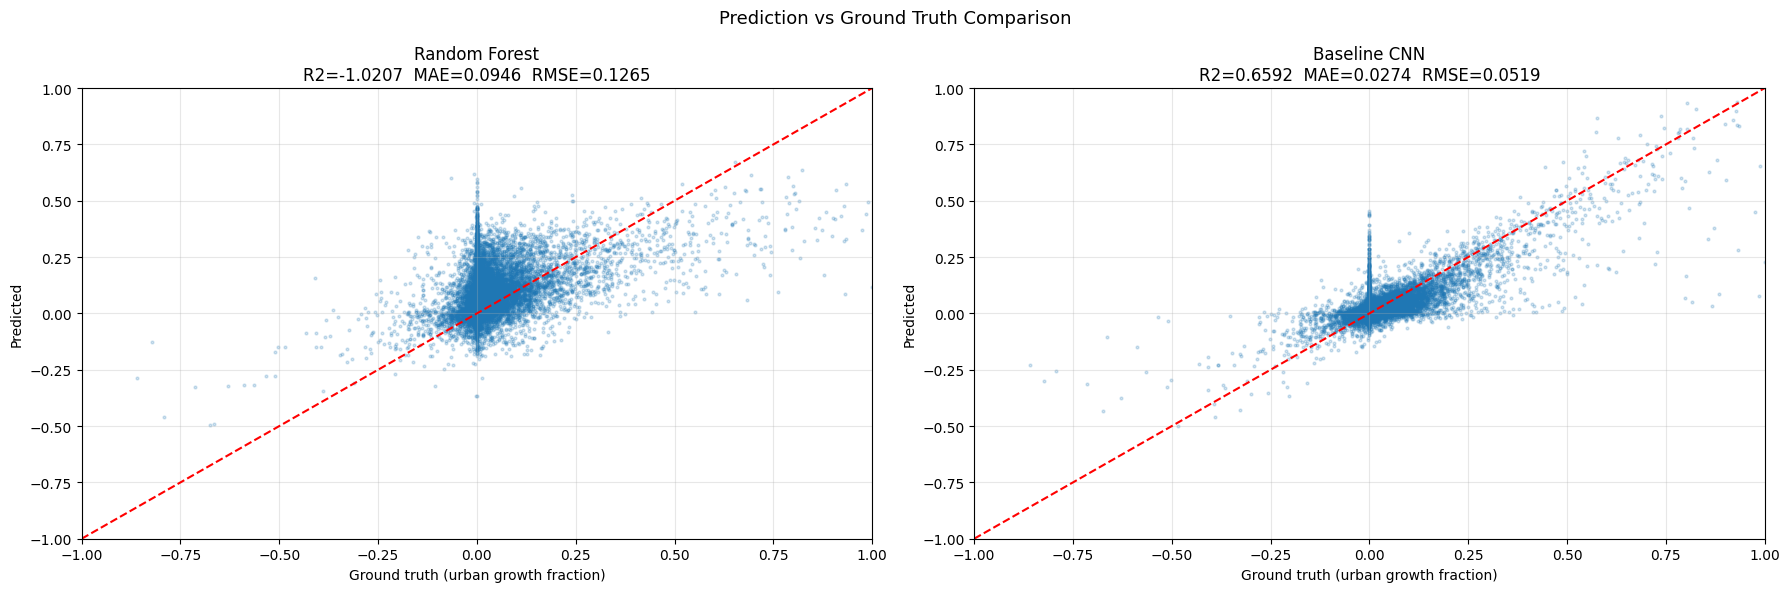

In [122]:
import numpy as np
import torch
import os
import joblib
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import r2_score, mean_absolute_error
import scipy.stats as stats

BATCH_SIZE = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GROWTH_THRESHOLD = 0.05

# Datasets
full_dataset_baseline = UrbanGrowthDatasetBaseline("data/patches")
full_dataset_auxmae = UrbanGrowthDataset("data/patches")

N = len(full_dataset_baseline)
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size

_, _, test_ds_baseline = random_split(
    full_dataset_baseline,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

_, _, test_ds_auxmae = random_split(
    full_dataset_auxmae,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

test_loader_baseline = DataLoader(test_ds_baseline, batch_size=BATCH_SIZE, shuffle=False)
test_loader_auxmae = DataLoader(test_ds_auxmae, batch_size=BATCH_SIZE, shuffle=False)

# Load models
baseline_model = UrbanGrowthCNNLarge(in_channels=15).to(DEVICE)
baseline_model.load_state_dict(torch.load("best_urban_growth_model_64_large.pt", map_location=DEVICE))
baseline_model.eval()

# auxmae_model_cnn = UrbanGrowthCNNLarge(in_channels=16).to(DEVICE)
# auxmae_model_cnn.load_state_dict(torch.load("cnn_auxmae_no_decay.pt", map_location=DEVICE))
# auxmae_model_cnn.eval()

rf_model = joblib.load("urban_growth_rf.joblib")

# Feature extraction for RF
def extract_features_from_loader(loader):
    X_list = []
    y_list = []

    for images, targets in loader:
        means = torch.mean(images, dim=[2, 3])
        stds  = torch.std(images, dim=[2, 3])
        features = torch.cat([means, stds], dim=1)

        X_list.append(features.numpy())
        y_list.append(targets.numpy())

    return np.vstack(X_list), np.hstack(y_list)

# CNN predictions
def get_predictions_cnn(model, loader):
    model.eval()
    all_preds, all_targets = [], []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            preds = model(x)

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y.cpu().numpy())

    return np.array(all_preds), np.array(all_targets)

preds_base, targets_base = get_predictions_cnn(baseline_model, test_loader_baseline)
# preds_aux, targets_aux = get_predictions_cnn(auxmae_model_cnn, test_loader_auxmae)

# RF predictions
X_test_rf, y_test_rf = extract_features_from_loader(test_loader_baseline)
preds_rf = rf_model.predict(X_test_rf)
targets_rf = y_test_rf

print(f"Test samples: {len(targets_base)}")

# Metrics
def compute_metrics(preds, targets, name):
    mae = mean_absolute_error(targets, preds)
    rmse = np.sqrt(np.mean((preds - targets) ** 2))
    r2 = r2_score(targets, preds)
    pearson_r, pearson_p = stats.pearsonr(preds, targets)
    bias = np.mean(preds - targets)

    print(f"{name}:")
    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R2: {r2:.4f}")
    print(f"Pearson r: {pearson_r:.4f} (p={pearson_p:.2e})")
    print(f"Bias: {bias:.6f} ({'overpredicts' if bias > 0 else 'underpredicts'})")
    print()

    return {
        "name": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Pearson_r": pearson_r,
        "Bias": bias
    }

metrics_rf = compute_metrics(preds_rf, targets_rf, "Random Forest")
metrics_base = compute_metrics(preds_base, targets_base, "Baseline CNN")
# metrics_aux  = compute_metrics(preds_aux, targets_aux, "AuxMAE CNN")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fixed_lims = [-1, 1]

for ax, preds, targets, name, metrics in [
    (axes[0], preds_rf, targets_rf, "Random Forest", metrics_rf),
    (axes[1], preds_base, targets_base, "Baseline CNN", metrics_base),
    # (axes[2], preds_aux, targets_aux, "AuxMAE CNN", metrics_aux),
]:
    ax.scatter(targets, preds, alpha=0.2, s=4)
    ax.plot(fixed_lims, fixed_lims, "r--", linewidth=1.5)

    ax.set_xlim(fixed_lims)
    ax.set_ylim(fixed_lims)

    ax.set_xlabel("Ground truth (urban growth fraction)")
    ax.set_ylabel("Predicted")
    ax.set_title(
        f"{name}\nR2={metrics['R2']:.4f}  MAE={metrics['MAE']:.4f}  RMSE={metrics['RMSE']:.4f}"
    )
    ax.grid(alpha=0.3)

plt.suptitle("Prediction vs Ground Truth Comparison", fontsize=13)
plt.tight_layout()
plt.savefig("eval_scatter_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

In [127]:
import numpy as np
import torch
import os
import re
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import r2_score, mean_absolute_error, classification_report, confusion_matrix
import scipy.stats as stats

GROWTH_THRESHOLD = 0.008

# Datasets
full_dataset_baseline = UrbanGrowthDatasetBaseline("data/patches")
full_dataset_auxmae = UrbanGrowthDataset("data/patches")
N = len(full_dataset_baseline)
train_size = int(0.75 * N)
val_size = int(0.15 * N)
test_size = N - train_size - val_size

_, _, test_ds_baseline = random_split(
    full_dataset_baseline, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)
_, _, test_ds_auxmae = random_split(
    full_dataset_auxmae, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

test_loader_baseline = DataLoader(test_ds_baseline, batch_size=BATCH_SIZE, shuffle=False)
test_loader_auxmae = DataLoader(test_ds_auxmae, batch_size=BATCH_SIZE, shuffle=False)

# Load models
baseline_model = UrbanGrowthCNNLarge(in_channels=15).to(DEVICE)
baseline_model.load_state_dict(torch.load("best_urban_growth_model_64_large.pt", map_location=DEVICE))
baseline_model.eval()

auxmae_model_cnn = UrbanGrowthCNNLarge(in_channels=16).to(DEVICE)
auxmae_model_cnn.load_state_dict(torch.load("best_urban_growth_model_auxmaecnn_updated.pt", map_location=DEVICE))
auxmae_model_cnn.eval()

# Generate predictions
def get_predictions(model, loader):
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            all_preds.extend(model(x).cpu().numpy())
            all_targets.extend(y.cpu().numpy())
    return np.array(all_preds), np.array(all_targets)

preds_base, targets_base = get_predictions(baseline_model, test_loader_baseline)
preds_aux, targets_aux = get_predictions(auxmae_model_cnn, test_loader_auxmae)

print(f"Test samples: {len(targets_base)}")
print(f"Baseline predictions range: [{preds_base.min():.4f}, {preds_base.max():.4f}]")
print(f"AuxMAE predictions range: [{preds_aux.min():.4f}, {preds_aux.max():.4f}]")
print(f"Ground truth range: [{targets_base.min():.4f}, {targets_base.max():.4f}]")

Test samples: 21439
Baseline predictions range: [-0.4995, 1.1123]
AuxMAE predictions range: [-0.6097, 1.3470]
Ground truth range: [-0.8596, 1.0000]


In [128]:
def compute_metrics(preds, targets, name):
    mae = mean_absolute_error(targets, preds)
    rmse = np.sqrt(np.mean((preds - targets) ** 2))
    r2 = r2_score(targets, preds)
    pearson_r, pearson_p = stats.pearsonr(preds, targets)
    bias = np.mean(preds - targets)

    print(f"{name}:")
    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R2: {r2:.4f}")
    print(f"Pearson r: {pearson_r:.4f}  (p={pearson_p:.2e})")
    print(f"Bias: {bias:.6f}  ({'overpredicts' if bias > 0 else 'underpredicts'})")
    print()
    return {"name": name, "MAE": mae, "RMSE": rmse, "R2": r2,
            "Pearson_r": pearson_r, "Bias": bias}

metrics_base = compute_metrics(preds_base, targets_base, "Baseline")
metrics_aux = compute_metrics(preds_aux, targets_aux, "AuxMAE")

Baseline:
MAE: 0.027433
RMSE: 0.051934
R2: 0.6592
Pearson r: 0.8121  (p=0.00e+00)
Bias: 0.001044  (overpredicts)

AuxMAE:
MAE: 0.028857
RMSE: 0.060575
R2: 0.5363
Pearson r: 0.7380  (p=0.00e+00)
Bias: 0.006018  (overpredicts)



In [96]:
def stratified_evaluation(preds, targets, name):
    print(f"{name} - stratified by growth category:")

    strata = [
        (targets < -0.01, "Decline (<-1%)"),
        (np.abs(targets) < 0.01,"No change (<1%)"),
        ((targets >= 0.01) & (targets < 0.05), "Low growth  (1-5%)"),
        ((targets >= 0.05) & (targets < 0.10), "Med growth  (5-10%)"),
        (targets >= 0.10, "High growth (>10%)"),
    ]

    rows = []
    for mask, label in strata:
        if mask.sum() < 10:
            continue
        r2 = r2_score(targets[mask], preds[mask])
        mae = mean_absolute_error(targets[mask], preds[mask])
        rmse = np.sqrt(np.mean((preds[mask] - targets[mask]) ** 2))
        print(f"  {label}  n={mask.sum():5d} | R2={r2:7.4f} | MAE={mae:.6f} | RMSE={rmse:.6f}")
        rows.append({"category": label.strip(), "n": mask.sum(),
                     "R2": r2, "MAE": mae, "RMSE": rmse})
    print()
    return pd.DataFrame(rows)

strat_base = stratified_evaluation(preds_base, targets_base, "Baseline")
strat_aux = stratified_evaluation(preds_aux, targets_aux, "AuxMAE")

Baseline - stratified by growth category:
  Decline (<-1%)  n= 1744 | R2= 0.2144 | MAE=0.046412 | RMSE=0.070513
  No change (<1%)  n=13152 | R2=-205.8322 | MAE=0.016203 | RMSE=0.033380
  Low growth  (1-5%)  n= 2976 | R2=-5.8453 | MAE=0.021382 | RMSE=0.029246
  Med growth  (5-10%)  n= 1638 | R2=-9.9057 | MAE=0.039679 | RMSE=0.047359
  High growth (>10%)  n= 1929 | R2= 0.4245 | MAE=0.085770 | RMSE=0.121079

AuxMAE - stratified by growth category:
  Decline (<-1%)  n= 1744 | R2=-0.4339 | MAE=0.066669 | RMSE=0.095261
  No change (<1%)  n=13152 | R2=-70.4285 | MAE=0.007942 | RMSE=0.019616
  Low growth  (1-5%)  n= 2976 | R2=-11.8140 | MAE=0.027337 | RMSE=0.040014
  Med growth  (5-10%)  n= 1638 | R2=-13.1189 | MAE=0.042491 | RMSE=0.053886
  High growth (>10%)  n= 1929 | R2= 0.0684 | MAE=0.110373 | RMSE=0.154053



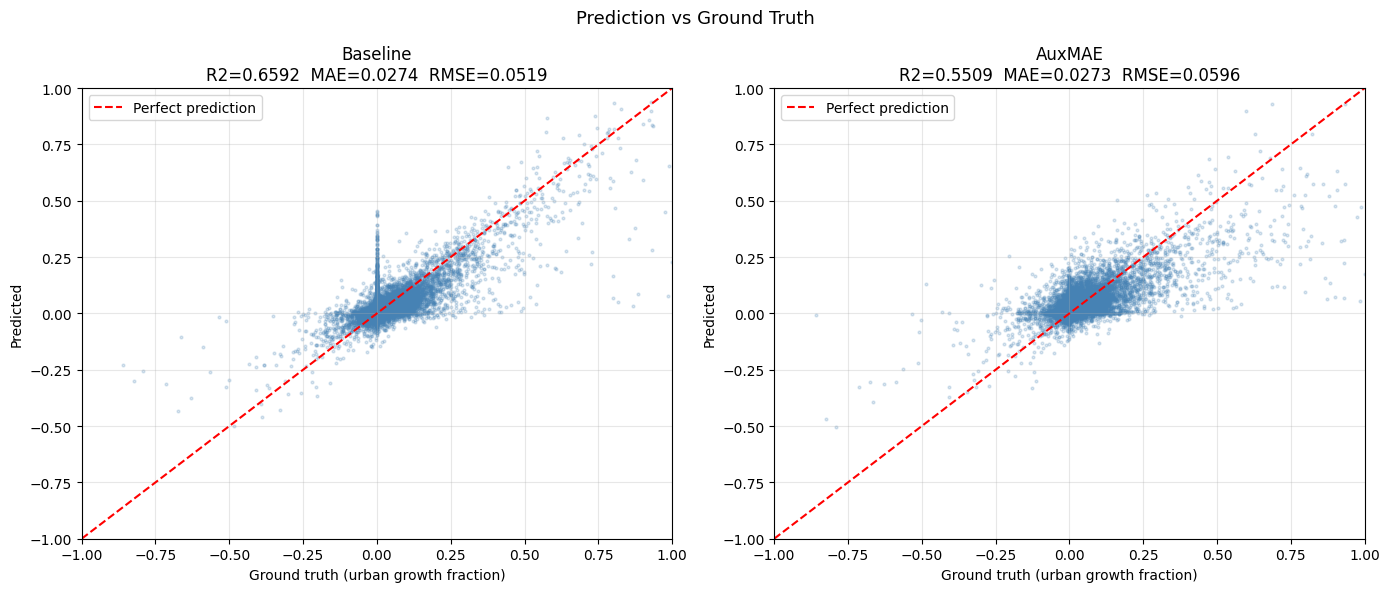

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Define the fixed limits
fixed_lims = [-1, 1]

for ax, preds, targets, name, metrics in [
    (axes[0], preds_base, targets_base, "Baseline", metrics_base),
    (axes[1], preds_aux, targets_aux, "AuxMAE", metrics_aux),
]:
    ax.scatter(targets, preds, alpha=0.2, s=4, color="steelblue")
    
    # Use the fixed limits for the identity line
    ax.plot(fixed_lims, fixed_lims, "r--", linewidth=1.5, label="Perfect prediction")
    
    # Force the axes to -1 and 1
    ax.set_xlim(fixed_lims)
    ax.set_ylim(fixed_lims)
    
    ax.set_xlabel("Ground truth (urban growth fraction)")
    ax.set_ylabel("Predicted")
    ax.set_title(
        f"{name}\nR2={metrics['R2']:.4f}  MAE={metrics['MAE']:.4f}  RMSE={metrics['RMSE']:.4f}"
    )
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Prediction vs Ground Truth", fontsize=13)
plt.tight_layout()
plt.savefig("eval_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

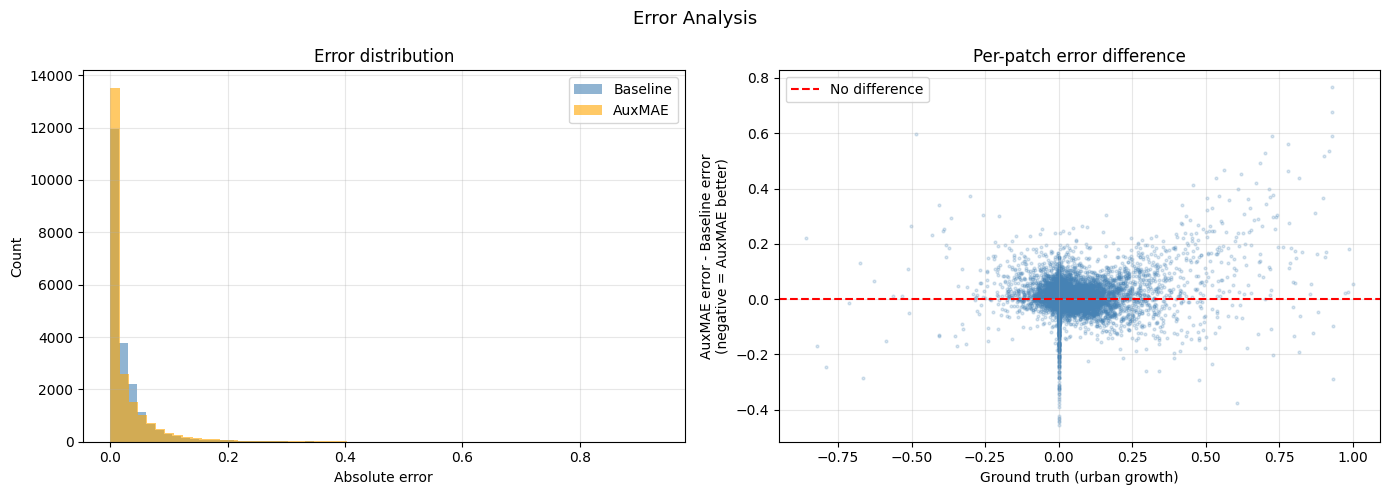

In [81]:
errors_base = np.abs(preds_base - targets_base)
errors_aux = np.abs(preds_aux - targets_aux)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(errors_base, bins=60, alpha=0.6, label="Baseline", color="steelblue")
axes[0].hist(errors_aux, bins=60, alpha=0.6, label="AuxMAE", color="orange")
axes[0].set_xlabel("Absolute error")
axes[0].set_ylabel("Count")
axes[0].set_title("Error distribution")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(targets_base, errors_aux - errors_base, alpha=0.2, s=4, color="steelblue")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5, label="No difference")
axes[1].set_xlabel("Ground truth (urban growth)")
axes[1].set_ylabel("AuxMAE error - Baseline error\n(negative = AuxMAE better)")
axes[1].set_title("Per-patch error difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Error Analysis", fontsize=13)
plt.tight_layout()
plt.savefig("eval_errors.png", dpi=150, bbox_inches="tight")
plt.show()

Baseline - growth detection (threshold=0.008):
              precision    recall  f1-score   support

   No growth       0.86      0.58      0.69     14670
      Growth       0.46      0.79      0.59      6769

    accuracy                           0.65     21439
   macro avg       0.66      0.69      0.64     21439
weighted avg       0.73      0.65      0.66     21439

AuxMAE - growth detection (threshold=0.008):
              precision    recall  f1-score   support

   No growth       0.90      0.81      0.85     14670
      Growth       0.66      0.80      0.72      6769

    accuracy                           0.80     21439
   macro avg       0.78      0.80      0.79     21439
weighted avg       0.82      0.80      0.81     21439



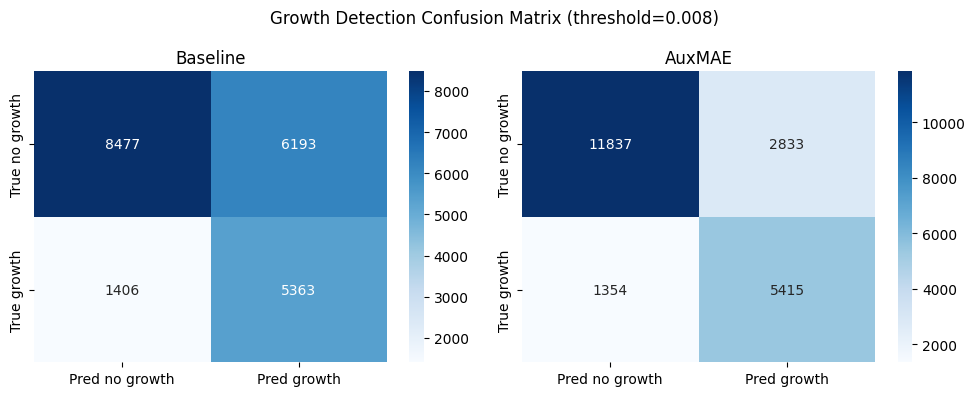

In [109]:
GROWTH_THRESHOLD = 0.008

true_grew = (targets_base >= GROWTH_THRESHOLD).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, preds, name in [(axes[0], preds_base, "Baseline"), (axes[1], preds_aux, "AuxMAE")]:
    pred_grew = (preds >= GROWTH_THRESHOLD).astype(int)
    print(f"{name} - growth detection (threshold={GROWTH_THRESHOLD}):")
    print(classification_report(true_grew, pred_grew, target_names=["No growth", "Growth"]))

    cm = confusion_matrix(true_grew, pred_grew)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Pred no growth", "Pred growth"],
                yticklabels=["True no growth", "True growth"],
                ax=ax)
    ax.set_title(f"{name}")

plt.suptitle(f"Growth Detection Confusion Matrix (threshold={GROWTH_THRESHOLD})", fontsize=12)
plt.tight_layout()
plt.savefig("eval_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

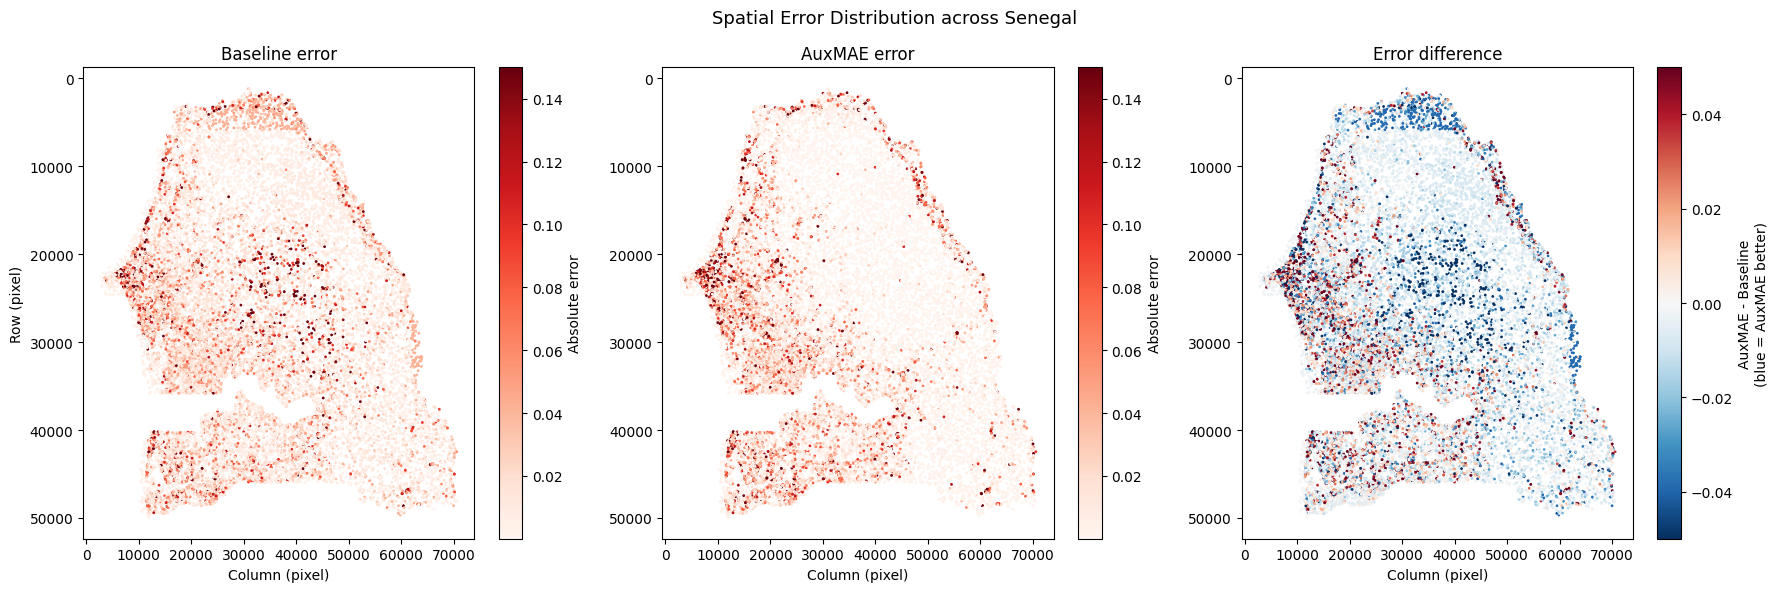

In [112]:
def extract_coords(fpath):
    match = re.search(r"patch_r(\d+)_c(\d+)", os.path.basename(fpath))
    if match:
        return int(match.group(1)), int(match.group(2))
    return None, None

test_files = [full_dataset_auxmae.files[i] for i in test_ds_auxmae.indices]
coords = [extract_coords(f) for f in test_files]
rows_px, cols_px = zip(*coords)
rows_px = np.array(rows_px)
cols_px = np.array(cols_px)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sc = axes[0].scatter(cols_px, rows_px, c=errors_base, cmap="Reds", s=1, vmax=0.15)
plt.colorbar(sc, ax=axes[0], label="Absolute error")
axes[0].set_title("Baseline error")
axes[0].invert_yaxis()
axes[0].set_xlabel("Column (pixel)")
axes[0].set_ylabel("Row (pixel)")

sc = axes[1].scatter(cols_px, rows_px, c=errors_aux, cmap="Reds", s=1, vmax=0.15)
plt.colorbar(sc, ax=axes[1], label="Absolute error")
axes[1].set_title("AuxMAE error")
axes[1].invert_yaxis()
axes[1].set_xlabel("Column (pixel)")

sc = axes[2].scatter(cols_px, rows_px, c=errors_aux - errors_base,
                     cmap="RdBu_r", s=1, vmin=-0.05, vmax=0.05)
plt.colorbar(sc, ax=axes[2], label="AuxMAE - Baseline\n(blue = AuxMAE better)")
axes[2].set_title("Error difference")
axes[2].invert_yaxis()
axes[2].set_xlabel("Column (pixel)")

plt.suptitle("Spatial Error Distribution across Senegal", fontsize=13)
plt.tight_layout()
plt.savefig("eval_spatial.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

def growth_clf_metrics(preds, targets, threshold):
    true = (targets >= threshold).astype(int)
    pred = (preds >= threshold).astype(int)
    return {
        "precision": precision_score(true, pred, zero_division=0),
        "recall": recall_score(true, pred, zero_division=0),
        "f1": f1_score(true, pred, zero_division=0),
    }

clf_base = growth_clf_metrics(preds_base, targets_base, GROWTH_THRESHOLD)
clf_aux = growth_clf_metrics(preds_aux, targets_aux, GROWTH_THRESHOLD)

summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "Pearson r", "Bias",
               "Growth Precision", "Growth Recall", "Growth F1"],
    "Baseline": [
        f"{metrics_base['MAE']:.6f}",
        f"{metrics_base['RMSE']:.6f}",
        f"{metrics_base['R2']:.4f}",
        f"{metrics_base['Pearson_r']:.4f}",
        f"{metrics_base['Bias']:.6f}",
        f"{clf_base['precision']:.4f}",
        f"{clf_base['recall']:.4f}",
        f"{clf_base['f1']:.4f}",
    ],
    "AuxMAE": [
        f"{metrics_aux['MAE']:.6f}",
        f"{metrics_aux['RMSE']:.6f}",
        f"{metrics_aux['R2']:.4f}",
        f"{metrics_aux['Pearson_r']:.4f}",
        f"{metrics_aux['Bias']:.6f}",
        f"{clf_aux['precision']:.4f}",
        f"{clf_aux['recall']:.4f}",
        f"{clf_aux['f1']:.4f}",
    ],
})

print(summary.to_string(index=False))
summary.to_csv("evaluation_summary.csv", index=False)
print("Saved -> evaluation_summary.csv")

          Metric Baseline    AuxMAE
             MAE 0.026981  0.022198
            RMSE 0.051016  0.046004
              R2   0.6615    0.7247
       Pearson r   0.8142    0.8519
            Bias 0.001352 -0.000132
Growth Precision   0.6934    0.7261
   Growth Recall   0.6162    0.6591
       Growth F1   0.6526    0.6910
Saved -> evaluation_summary.csv


In [44]:
BLOCK_ROWS = 512

def process_block_for_inference(
    dry_block,
    wet_block,
    s1_block,
    lulc_2019_block,
    lulc_2024_block,
    school_dist_block,
    airport_dist_block,
    patch_size,
    stride,
    global_row_offset,
    model,
    auxmae_model,
    device,
    pred_map,
    gt_map,
    all_preds,
    all_targets,
):
    H, W, _ = dry_block.shape

    for r in range(0, H - patch_size + 1, stride):
        for c in range(0, W - patch_size + 1, stride):

            # LULC
            lulc_2019_patch = lulc_2019_block[r:r+patch_size, c:c+patch_size]
            lulc_2024_patch = lulc_2024_block[r:r+patch_size, c:c+patch_size]

            if np.any(lulc_2019_patch == 0):
                continue

            # MODALITIES
            dry_patch = dry_block[r:r+patch_size, c:c+patch_size, :]
            wet_patch = wet_block[r:r+patch_size, c:c+patch_size, :]
            s1_patch  = s1_block[r:r+patch_size, c:c+patch_size, :]

            school_patch  = school_dist_block[r:r+patch_size, c:c+patch_size, :]
            airport_patch = airport_dist_block[r:r+patch_size, c:c+patch_size, :]

            # Build the input like in training
            patch = np.concatenate([
                np.transpose(dry_patch, (2, 0, 1)),
                np.transpose(wet_patch, (2, 0, 1)),
                lulc_2019_patch[None, :, :],
                lulc_2024_patch[None, :, :],
                np.transpose(school_patch, (2, 0, 1)),
                np.transpose(airport_patch, (2, 0, 1)),
            ], axis=0)

            # AuxMAE features
            auxmae_features = extract_auxmae_features(
                s2_patch=dry_patch,
                s1_patch=s1_patch,
                model=auxmae_model,
                device=device,
                patch_size=auxmae_model.patch_size,
                img_size=patch_size,
            )

            patch = np.concatenate([patch, auxmae_features], axis=0)

            # Do inference
            x_tensor = torch.tensor(patch, dtype=torch.float32).unsqueeze(0).to(device)

            with torch.no_grad():
                pred = model(x_tensor).item()

            # Ground truth
            urban_frac_2019 = np.mean(lulc_2019_patch == URBAN_CLASS)
            urban_frac_2024 = np.mean(lulc_2024_patch == URBAN_CLASS)
            gt = urban_frac_2024 - urban_frac_2019

            # Store for evaluation
            all_preds.append(pred)
            all_targets.append(gt)

            y_global = global_row_offset + r
            x_global = c

            pred_map[y_global:y_global+patch_size, x_global:x_global+patch_size] = pred
            gt_map[y_global:y_global+patch_size, x_global:x_global+patch_size] = gt

from rasterio.windows import Window

def run_full_inference_blockwise(
    img_dry_path,
    img_wet_path,
    s1_path,
    lulc_2019_path,
    lulc_2024_path,
    school_dists_array,
    airport_dists_array,
    patch_size,
    stride,
    block_rows,
    model,
    auxmae_model,
):
    all_preds = []
    all_targets = []

    with rasterio.open(img_dry_path) as dry_ds, \
         rasterio.open(img_wet_path) as wet_ds, \
         rasterio.open(s1_path) as s1_ds, \
         rasterio.open(lulc_2019_path) as lulc_ds_2019, \
         rasterio.open(lulc_2024_path) as lulc_ds_2024:

        H, W = dry_ds.height, dry_ds.width

        pred_map = np.full((H, W), np.nan, dtype=np.float32)
        gt_map   = np.full((H, W), np.nan, dtype=np.float32)

        print(f"Raster size: {H} x {W}")

        for row0 in tqdm(range(0, H, block_rows), desc="Blocks"):
            row1 = min(row0 + block_rows + patch_size, H)

            win = Window(0, row0, W, row1 - row0)

            # Read blocks
            dry_block = np.stack([dry_ds.read(b, window=win) for b in (1,2,3,4)], axis=-1)
            wet_block = np.stack([wet_ds.read(b, window=win) for b in (1,2,3,4)], axis=-1)
            s1_block = np.stack([s1_ds.read(b, window=win) for b in (1,2)], axis=-1)

            lulc_2019_block = lulc_ds_2019.read(1, window=win)
            lulc_2024_block = lulc_ds_2024.read(1, window=win)

            school_block = school_dists_array[row0:row1, :, :]
            airport_block = airport_dists_array[row0:row1, :, :]

            process_block_for_inference(
                dry_block,
                wet_block,
                s1_block,
                lulc_2019_block,
                lulc_2024_block,
                school_block,
                airport_block,
                patch_size,
                stride,
                row0,
                model,
                auxmae_model,
                device,
                pred_map,
                gt_map,
                all_preds,
                all_targets,
            )

    return pred_map, gt_map, np.array(all_preds), np.array(all_targets)

In [68]:
def run_full_inference_blockwise(
    img_dry_path, img_wet_path, s1_path,
    lulc_2019_path, lulc_2024_path,
    school_dists_array, airport_dists_array,
    patch_size, stride, block_rows,
    model, auxmae_model,
    pred_map_path="pred_map.tif",
    gt_map_path="gt_map.tif",
):
    all_preds = []
    all_targets = []

    with rasterio.open(img_dry_path) as dry_ds:
        H, W = dry_ds.height, dry_ds.width
        profile = dry_ds.profile.copy()

    profile.update(count=1, dtype="float32", nodata=np.nan)

    with rasterio.open(img_dry_path) as dry_ds, \
         rasterio.open(img_wet_path) as wet_ds, \
         rasterio.open(s1_path) as s1_ds, \
         rasterio.open(lulc_2019_path) as lulc_ds_2019, \
         rasterio.open(lulc_2024_path) as lulc_ds_2024, \
         rasterio.open(pred_map_path, "w", **profile) as pred_ds, \
         rasterio.open(gt_map_path, "w", **profile) as gt_ds:

        print(f"Raster size: {H} x {W}")
        print(f"Writing pred map to: {pred_map_path}")
        print(f"Writing gt map to: {gt_map_path}")

        for row0 in tqdm(range(0, H, block_rows), desc="Blocks"):
            row1 = min(row0 + block_rows + patch_size, H)
            win = Window(0, row0, W, row1 - row0)

            dry_block = np.stack([dry_ds.read(b, window=win) for b in (1,2,3,4)], axis=-1)
            wet_block = np.stack([wet_ds.read(b, window=win) for b in (1,2,3,4)], axis=-1)
            s1_block = np.stack([s1_ds.read(b, window=win) for b in (1,2)], axis=-1)
            lulc_2019_block = lulc_ds_2019.read(1, window=win)
            lulc_2024_block = lulc_ds_2024.read(1, window=win)
            school_block = school_dists_array[row0:row1, :, :]
            airport_block = airport_dists_array[row0:row1, :, :]

            block_h = dry_block.shape[0]

            # Small buffers just for this block — much smaller than full raster
            pred_block = np.full((block_h, W), np.nan, dtype=np.float32)
            gt_block = np.full((block_h, W), np.nan, dtype=np.float32)

            for r in range(0, block_h - patch_size + 1, stride):
                for c in range(0, W - patch_size + 1, stride):
                    lulc_2019_patch = lulc_2019_block[r:r+patch_size, c:c+patch_size]
                    lulc_2024_patch = lulc_2024_block[r:r+patch_size, c:c+patch_size]

                    if np.any(lulc_2019_patch == 0):
                        continue

                    dry_patch = dry_block[r:r+patch_size, c:c+patch_size, :]
                    wet_patch = wet_block[r:r+patch_size, c:c+patch_size, :]
                    s1_patch = s1_block[r:r+patch_size, c:c+patch_size, :]
                    school_patch = school_block[r:r+patch_size, c:c+patch_size, :]
                    airport_patch = airport_block[r:r+patch_size, c:c+patch_size, :]

                    patch = np.concatenate([
                        np.transpose(dry_patch, (2, 0, 1)),
                        np.transpose(wet_patch, (2, 0, 1)),
                        lulc_2019_patch[None, :, :],
                        lulc_2024_patch[None, :, :],
                        np.transpose(school_patch, (2, 0, 1)),
                        np.transpose(airport_patch, (2, 0, 1)),
                    ], axis=0)

                    
                    
                    auxmae_features = extract_auxmae_features(
                        s2_patch=dry_patch,
                        s1_patch=s1_patch,
                        model=auxmae_model,
                        device=device,
                        patch_size=auxmae_model.patch_size,
                        img_size=patch_size,
                    )
                    patch = np.concatenate([patch, auxmae_features], axis=0)

                    # Remove lulc_2024 (channel 9) to match training input
                    patch = np.concatenate([patch[:9], patch[10:]], axis=0)
                    
                    x_tensor = torch.tensor(patch, dtype=torch.float32).unsqueeze(0).to(device)
                    with torch.no_grad():
                        pred = model(x_tensor).item()

                    urban_frac_2019 = np.mean(lulc_2019_patch == URBAN_CLASS)
                    urban_frac_2024 = np.mean(lulc_2024_patch == URBAN_CLASS)
                    gt = urban_frac_2024 - urban_frac_2019

                    all_preds.append(pred)
                    all_targets.append(gt)

                    pred_block[r:r+patch_size, c:c+patch_size] = pred
                    gt_block[r:r+patch_size, c:c+patch_size] = gt

            # Write this block's results to disk
            write_win = Window(0, row0, W, block_h)
            pred_ds.write(pred_block[np.newaxis, :, :], window=write_win)
            gt_ds.write(gt_block[np.newaxis, :, :], window=write_win)

    print(f"Done. Processed {len(all_preds):,} patches.")
    return np.array(all_preds), np.array(all_targets)

In [51]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [58]:
# Copy of AuxMAE class so we can use it in this notebook

import os
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from einops import repeat
from tqdm import tqdm
import matplotlib.pyplot as plt
import glob
import psutil

IMG_SIZE = 64
PATCH_SIZE = 8
IN_CHANNELS_S2 = 4
IN_CHANNELS_S1 = 2
ENCODER_DIM = 256
ENCODER_DEPTH = 6
ENCODER_HEADS = 8
AUX_DEPTH = 2
DECODER_DIM = 128
DECODER_DEPTH = 4
DECODER_HEADS = 8
MASK_RATIO = 0.75
BATCH_SIZE = 128
NUM_EPOCHS = 400
LR = 1.5e-4
WARMUP_EPOCHS = 40
MAE_PATCH_DIR = "data/mae_patches_all"
CHECKPOINT_PATH = "models/auxmae_best.pt"

class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, x):
        return self.net(x) + x


class Attention(nn.Module):
    def __init__(self, dim, heads=8):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)

    def forward(self, x):
        x_norm = self.norm(x)
        attn_out, _ = self.attn(x_norm, x_norm, x_norm)
        return attn_out + x


class CrossAttention(nn.Module):
    def __init__(self, dim, heads=8):
        super().__init__()
        self.norm_q = nn.LayerNorm(dim)
        self.norm_kv = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)

    def forward(self, query, key_value):
        q = self.norm_q(query)
        kv = self.norm_kv(key_value)
        attn_out, _ = self.attn(q, kv, kv)
        return attn_out + query


class Transformer(nn.Module):
    def __init__(self, dim, depth, heads, mlp_ratio=4):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.ModuleList([
                Attention(dim, heads),
                FeedForward(dim, dim * mlp_ratio),
            ])
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        for attn, ff in self.layers:
            x = attn(x)
            x = ff(x)
        return self.norm(x)


class DecoderTransformer(nn.Module):
    """Decoder transformer where each block does self-attn then cross-attn to S1."""
    def __init__(self, dim, depth, heads, mlp_ratio=4):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.ModuleList([
                Attention(dim, heads),
                CrossAttention(dim, heads),
                FeedForward(dim, dim * mlp_ratio),
            ])
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(dim)

    def forward(self, x, s1_tokens):
        for self_attn, cross_attn, ff in self.layers:
            x = self_attn(x)
            x = cross_attn(x, s1_tokens) # attend to S1 auxiliary tokens
            x = ff(x)
        return self.norm(x)


print("Transformer blocks defined.")


class AuxMAE(nn.Module):
    def __init__(self, img_size=IMG_SIZE, patch_size=PATCH_SIZE,
                 in_ch_s2=IN_CHANNELS_S2, in_ch_s1=IN_CHANNELS_S1,
                 encoder_dim=ENCODER_DIM, encoder_depth=ENCODER_DEPTH,
                 encoder_heads=ENCODER_HEADS, aux_depth=AUX_DEPTH,
                 decoder_dim=DECODER_DIM, decoder_depth=DECODER_DEPTH,
                 decoder_heads=DECODER_HEADS, mask_ratio=MASK_RATIO):
        super().__init__()
        self.patch_size = patch_size
        self.mask_ratio = mask_ratio
        num_patches = (img_size // patch_size) ** 2
        patch_dim_s2 = patch_size * patch_size * in_ch_s2
        patch_dim_s1 = patch_size * patch_size * in_ch_s1

        # S2 patch embedding - splits image into patches then projects to encoder_dim
        # to_patch: rearranges image into flat patches (done in forward)
        # patch_to_emb: linear projection from raw pixels to encoder_dim
        self.s2_patch_to_emb = nn.Sequential(
            nn.LayerNorm(patch_dim_s2),
            nn.Linear(patch_dim_s2, encoder_dim),
            nn.LayerNorm(encoder_dim),
        )

        # S1 patch embedding (same structure, different input dim)
        self.s1_patch_to_emb = nn.Sequential(
            nn.LayerNorm(patch_dim_s1),
            nn.Linear(patch_dim_s1, encoder_dim),
            nn.LayerNorm(encoder_dim),
        )

        # Positional embeddings - shared between S2 and S1 (same spatial grid)
        self.pos_embedding = nn.Embedding(num_patches, encoder_dim)

        # S2 primary encoder
        self.s2_encoder = Transformer(encoder_dim, encoder_depth, encoder_heads)

        # S1 auxiliary encoder - shallow, just enough to get useful spatial tokens
        self.s1_aux_encoder = Transformer(encoder_dim, aux_depth, encoder_heads)

        # Mask token - substituted for masked S2 positions before decoding
        self.mask_token = nn.Parameter(torch.randn(decoder_dim))

        # Project encoder_dim -> decoder_dim if they differ
        self.enc_to_dec = nn.Linear(encoder_dim, decoder_dim) if encoder_dim != decoder_dim else nn.Identity()
        self.s1_to_dec = nn.Linear(encoder_dim, decoder_dim) if encoder_dim != decoder_dim else nn.Identity()

        # Decoder positional embeddings
        self.decoder_pos_emb = nn.Embedding(num_patches, decoder_dim)

        # Decoder with cross-attention to S1
        self.decoder = DecoderTransformer(decoder_dim, decoder_depth, decoder_heads)

        # Final projection to reconstruct pixel values
        self.to_pixels = nn.Linear(decoder_dim, patch_dim_s2)

    def _image_to_patches(self, img, patch_size):
        """
        img: (B, C, H, W)
        returns: (B, num_patches, patch_size*patch_size*C)
        """
        B, C, H, W = img.shape
        h = H // patch_size
        x = img.reshape(B, C, h, patch_size, h, patch_size)
        x = x.permute(0, 2, 4, 3, 5, 1) # (B, h, h, p, p, C)
        x = x.reshape(B, h * h, patch_size * patch_size * C)
        return x

    def encode_s2_only(self, s2):
        """
        Inference-only path. Encodes all S2 tokens without any masking.
        Used during CNN patch feature extraction - no S1 needed.
        """
        patches = self._image_to_patches(s2, self.patch_size)
        tokens = self.s2_patch_to_emb(patches)
        n = tokens.shape[1]
        pos_indices = torch.arange(n, device=s2.device)
        tokens = tokens + self.pos_embedding(pos_indices)
        return self.s2_encoder(tokens)

    def forward(self, s2, s1):
        device = s2.device
        batch_size = s2.shape[0]

        # Patchify both modalities
        s2_patches = self._image_to_patches(s2, self.patch_size) # (B, N, patch_dim_s2)
        s1_patches = self._image_to_patches(s1, self.patch_size) # (B, N, patch_dim_s1)

        # Embed patches
        s2_tokens = self.s2_patch_to_emb(s2_patches) # (B, N, encoder_dim)
        s1_tokens = self.s1_patch_to_emb(s1_patches) # (B, N, encoder_dim)

        num_patches = s2_tokens.shape[1]
        pos_indices = torch.arange(num_patches, device=device)

        # Add positional embeddings
        s2_tokens = s2_tokens + self.pos_embedding(pos_indices)
        s1_tokens = s1_tokens + self.pos_embedding(pos_indices)

        # Random masking for S2 only
        num_masked = int(self.mask_ratio * num_patches)
        rand_indices = torch.rand(batch_size, num_patches, device=device).argsort(dim=-1)
        masked_indices = rand_indices[:, :num_masked]
        unmasked_indices = rand_indices[:, num_masked:]

        batch_range = torch.arange(batch_size, device=device)[:, None]

        # Encode only the visible S2 tokens
        visible_tokens = s2_tokens[batch_range, unmasked_indices
        encoded_tokens = self.s2_encoder(visible_tokens)

        # Encode ALL S1 tokens - no masking, S1 is fully available as auxiliary
        s1_encoded = self.s1_aux_encoder(s1_tokens)

        # Project to decoder dim
        decoder_tokens = self.enc_to_dec(encoded_tokens)
        s1_dec_tokens = self.s1_to_dec(s1_encoded)

        # Add decoder positional embeddings to visible tokens
        unmasked_decoder_tokens = decoder_tokens + self.decoder_pos_emb(unmasked_indices)

        # Create mask tokens for masked positions and add positional embeddings
        mask_tokens = repeat(self.mask_token, 'd -> b n d', b=batch_size, n=num_masked)
        mask_tokens = mask_tokens + self.decoder_pos_emb(masked_indices)

        # Reconstruct full sequence in original patch order
        decoder_sequence = torch.zeros(batch_size, num_patches, self.to_pixels.in_features, device=device)
        decoder_sequence[batch_range, unmasked_indices] = unmasked_decoder_tokens
        decoder_sequence[batch_range, masked_indices] = mask_tokens

        # Decode with cross-attention to S1 auxiliary tokens
        decoded_tokens = self.decoder(decoder_sequence, s1_dec_tokens)

        # Extract only masked positions and reconstruct pixels
        masked_decoded = decoded_tokens[batch_range, masked_indices]
        pred_pixel_values = self.to_pixels(masked_decoded) # (B, n_masked, patch_dim_s2)

        # Ground truth: original S2 pixel values at masked positions
        masked_patches = s2_patches[batch_range, masked_indices]

        recon_loss = F.mse_loss(pred_pixel_values, masked_patches)
        return recon_loss, pred_pixel_values, masked_indices, rand_indices


model = AuxMAE().to(device)

n_total = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_s2_enc = sum(p.numel() for p in model.s2_encoder.parameters())
n_s1_enc = sum(p.numel() for p in model.s1_aux_encoder.parameters())
n_decoder = sum(p.numel() for p in model.decoder.parameters())
print(f"Total params: {n_total/1e6:.2f}M")
print(f"S2 encoder: {n_s2_enc/1e6:.2f}M")
print(f"S1 aux encoder: {n_s1_enc/1e6:.2f}M")
print(f"Decoder: {n_decoder/1e6:.2f}M")

# Quick forward pass test
s2_test = torch.randn(2, 4, IMG_SIZE, IMG_SIZE).to(device)
s1_test = torch.randn(2, 2, IMG_SIZE, IMG_SIZE).to(device)
loss_test, _, _, _ = model(s2_test, s1_test)
print(f"Test forward pass loss: {loss_test.item():.4f}")

Transformer blocks defined.
Total params: 7.60M
S2 encoder: 4.74M
S1 aux encoder: 1.58M
Decoder: 1.06M
Test forward pass loss: 1.3481


In [59]:
auxmae_model = AuxMAE().to(device)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
auxmae_model.load_state_dict(checkpoint["model"])
auxmae_model.eval()
print(f"AuxMAE loaded from epoch {checkpoint['epoch']} | val loss: {checkpoint['val_loss']:.6f}")

AuxMAE loaded from epoch 269 | val loss: 0.000709


In [64]:
def extract_auxmae_features(s2_patch, s1_patch, model, device, patch_size, img_size):
    """
    Extracts AuxMAE encoder features for a single S2 patch.
    Uses encode_s2_only so no S1 is needed at inference time.

    returns: numpy (n_out, H, W)
    """
    s2_raw = np.transpose(s2_patch, (2, 0, 1)).astype(np.float32)
    s1_raw = np.transpose(s1_patch, (2, 0, 1)).astype(np.float32)
    
    if s2_raw.max() > 10.0:
        s2_raw = s2_raw / 10000.0
        
    with torch.no_grad():
        s2 = torch.tensor(s2_raw).unsqueeze(0).to(device)
        s1 = torch.tensor(s1_raw).unsqueeze(0).to(device)
        
        # Full forward pass - S1 guides S2 reconstruction via cross-attention
        # mask is random but that's fine since we save to disk once
        _, pred_pixels, masked_indices, rand_indices = model(s2, s1)

        # Reconstruct full patch sequence: visible = original, masked = predicted
        s2_patches = model._image_to_patches(s2, model.patch_size)[0] # (N, patch_dim)
        full_patches = s2_patches.clone()
        full_patches[masked_indices[0]] = pred_pixels[0]

        # Reshape to spatial image
        h = img_size // patch_size
        n_patches = h * h
        reconstruction = full_patches.reshape(h, h, patch_size, patch_size, 4)
        reconstruction = reconstruction.permute(4, 0, 2, 1, 3).reshape(4, img_size, img_size) # (4, H, W)

    return reconstruction.cpu().numpy()

Raster size: 51867 x 70964
Writing pred map to: data/pred_map.tif
Writing gt map to: data/gt_map.tif


Done. Processed 2,163,248 patches.
              precision    recall  f1-score   support

           0       0.99      0.75      0.85   2145123
           1       0.02      0.46      0.03     18125

    accuracy                           0.74   2163248
   macro avg       0.50      0.61      0.44   2163248
weighted avg       0.99      0.74      0.85   2163248



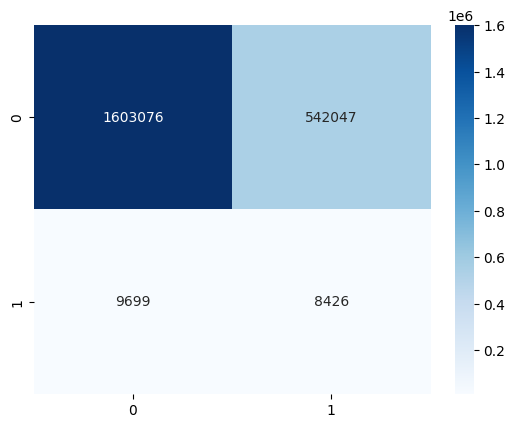

In [69]:
school_dists_array = np.load(
    "data/preprocessed_data/school_distances.npy",
    mmap_mode="r"
)

airport_dists_array = np.load(
    "data/preprocessed_data/airport_distances.npy",
    mmap_mode="r"
)

# pred_map, gt_map, preds, targets = run_full_inference_blockwise(
#     IMG_PATH_2019_DRY,
#     IMG_PATH_2019_WET,
#     IMG_PATH_2024,
#     LULC_PATH_2019,
#     LULC_PATH_2024,
#     school_dists_array,
#     airport_dists_array,
#     PATCH_SIZE,
#     STRIDE,
#     BLOCK_ROWS,
#     auxmae_model_cnn,
#     auxmae_model,
# )

preds, targets = run_full_inference_blockwise(
    IMG_PATH_2019_DRY,
    IMG_PATH_2019_WET,
    IMG_PATH_2024,
    LULC_PATH_2019,
    LULC_PATH_2024,
    school_dists_array,
    airport_dists_array,
    PATCH_SIZE,
    STRIDE,
    BLOCK_ROWS,
    auxmae_model_cnn,
    auxmae_model,
    pred_map_path="data/pred_map.tif",
    gt_map_path="data/gt_map.tif",
)

true_grew = (targets >= GROWTH_THRESHOLD).astype(int)
pred_grew = (preds >= GROWTH_THRESHOLD).astype(int)

print(classification_report(true_grew, pred_grew))

cm = confusion_matrix(true_grew, pred_grew)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.show()

In [6]:
import numpy as np
import rasterio
from rasterio.windows import Window
from tqdm import tqdm

def expand_patch_predictions_blockwise(
    input_tif,
    output_tif,
    patch_size=64,
    stride=32,
    block_rows=512
):
    with rasterio.open(input_tif) as src:
        H, W = src.height, src.width
        profile = src.profile.copy()

    profile.update(dtype="float32", count=1, nodata=np.nan)

    with rasterio.open(input_tif) as src, \
         rasterio.open(output_tif, "w", **profile) as dst:

        for row0 in tqdm(range(0, H, block_rows), desc="Blocks"):
            row1 = min(row0 + block_rows + patch_size, H)

            win = Window(0, row0, W, row1 - row0)
            pred_block = src.read(1, window=win)

            block_h = pred_block.shape[0]

            # Local buffers (small)
            expanded = np.zeros((block_h, W), dtype=np.float32)
            count = np.zeros((block_h, W), dtype=np.float32)

            # Expand within this block
            for r in range(0, block_h, stride):
                for c in range(0, W, stride):
                    val = pred_block[r, c]

                    if np.isnan(val):
                        continue

                    r1_local = min(r + patch_size, block_h)
                    c1 = min(c + patch_size, W)

                    expanded[r:r1_local, c:c1] += val
                    count[r:r1_local, c:c1] += 1

            # Average overlaps
            mask = count > 0
            expanded[mask] /= count[mask]
            expanded[~mask] = np.nan

            # IMPORTANT: crop overlap before writing
            valid_h = min(block_rows, H - row0)

            write_win = Window(0, row0, W, valid_h)
            dst.write(expanded[:valid_h, :][np.newaxis, :, :], window=write_win)

    print(f"Saved expanded map to: {output_tif}")


# RUN
expand_patch_predictions_blockwise(
    input_tif="data/pred_map.tif",
    output_tif="data/pred_map_expanded.tif",
    patch_size=64,
    stride=32,
    block_rows=512
)

Saved expanded map to: data/pred_map_expanded.tif


In [5]:
import numpy as np
import rasterio
from rasterio.windows import Window
from tqdm import tqdm

def clamp_negative_to_zero(
    input_tif,
    output_tif,
    block_rows=512
):
    with rasterio.open(input_tif) as src:
        H, W = src.height, src.width
        profile = src.profile.copy()

    profile.update(dtype="float32", count=1, nodata=np.nan)

    with rasterio.open(input_tif) as src, \
         rasterio.open(output_tif, "w", **profile) as dst:

        for row0 in tqdm(range(0, H, block_rows), desc="Clamping"):
            row1 = min(row0 + block_rows, H)

            win = Window(0, row0, W, row1 - row0)
            block = src.read(1, window=win)

            # Clamp negatives to 0
            block = np.where(block < 0, 0, block)

            dst.write(block[np.newaxis, :, :], window=win)

    print(f"Saved clamped map to: {output_tif}")


clamp_negative_to_zero(
    input_tif="data/pred_map_expanded.tif",
    output_tif="data/pred_map_relu.tif"
)

Saved clamped map to: data/pred_map_relu.tif
